In [ ]:
# general imports
import os
import scipy.stats as stats
from itertools import product, combinations_with_replacement
import pickle
import ast
from unidecode import unidecode
import sys
import pandas as pd
import json
import itertools

# plotting imports
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import plotly.graph_objects as go
# kaleido is necessary for saving plots made with plotly
# this needs to be version 0.1 (pip install --upgrade kaleido=="0.1.0.post1") because higher versions crash
import kaleido
import nbformat

# local imports
# from processing_utils import convert_to_two_level_multiindex, normalize_df_to_rpm
from unicode_utils import apply_greek_labels_heatmap, introduce_greek_letters, replace_greek_letters
from constants import CELL_TYPE_COLORS, ALL_CELL_TYPES
from plotting_utils import cm_to_inches, setup_plotting_environment
setup_plotting_environment()

ALL_CELL_TYPES_EXCLUDE = [cell for cell in ALL_CELL_TYPES if cell not in ["ILC", "pDC"]]

# set up folders
input_data_folder = f"../../data/"
os.makedirs(input_data_folder, exist_ok=True)

base_plot_folder = f"./plots/"
os.makedirs(base_plot_folder, exist_ok=True)

intermediate_output_folder = f"./output/"
os.makedirs(intermediate_output_folder, exist_ok=True)

output_tables_folder = f"./output_tables/"
os.makedirs(output_tables_folder, exist_ok=True)

# 1 - Load the data

In [2]:
plot_folder = os.path.join(base_plot_folder, "1_data_loading")
os.makedirs(plot_folder, exist_ok=True)

In [3]:
# info on cytokines
cytokine_info = pd.read_excel("../annotations/20250405_cytokine_info_with_functional_classification_LO.xlsx", index_col=0, sheet_name="all_cytokines")
cytokine_info["single_gene"] = cytokine_info["gene"].str.split(",").str[0]

cytokine_info_parse = cytokine_info[cytokine_info["parse_cytokine"]]
cytokine_info_order = pd.read_excel("../annotations/20250405_cytokine_info_with_functional_classification_LO.xlsx", index_col=0, sheet_name="suggested_order")

CYTOKINE_ORDER = list(cytokine_info_order["name"])
CYTOKINE_ORDER_WITH_PBS = ["PBS"] + CYTOKINE_ORDER
SINGLE_FAMILY_ORDER = cytokine_info_order["DEG_plot_family"].unique()

In [4]:
cytokine_name_to_level_1_family = cytokine_info.reset_index().set_index("name")["family_level_1"].to_dict()
cytokine_name_to_level_2_family = cytokine_info.reset_index().set_index("name")["family_level_2"].to_dict()

cytokine_level_1_order = list(dict.fromkeys(cytokine_name_to_level_1_family.values()))
cytokine_level_2_order = list(dict.fromkeys(cytokine_name_to_level_2_family.values()))

level2_to_level1 = cytokine_info.set_index("family_level_2")["family_level_1"].to_dict()

In [5]:
# donor info - not really using this for now
# donor_names = [f"Donor{i+1}" for i in range(12)]
# donor_metadata = pd.read_excel("../annotations/donor_metadata.xlsx")
# donor_metadata["Donor number"] = donor_metadata["Donor number"].str.replace(" ", "")
# donor_metadata.index = donor_metadata["Donor number"]
# donor_metadata["age"] = 2024 - donor_metadata["Birth year"]

## 1.1 - Process pseudobulks

#### Convert pseudobulk files into a usable format

In [6]:
relevant_cell_types = [
    "CD4",
    "CD8",
    "B",
    "CD56-bright_NK",
    "Treg",
    "MAIT",
    "CD14_Mono",
    "CD16_Mono",
    "CD56-dim_NK",
    "NKT",
    "cDC",
    "pDC",
    "other",
    "ILC",
    "HSPC",
]

relevant_cell_type_conversion = {
    "Treg": "Treg",
    "CD14_Mono": "CD14 Mono",
    "HSPC": "HSPC", 
    "pDC": "pDC",
    "NKT": "NKT",
    "other": "granulocyte",
    "CD16_Mono": "CD16 Mono",
    "CD56-bright_NK": "NK CD56hi",
    "CD56-dim_NK": "NK CD56low",
    "MAIT": "MAIT",
    "cDC": "cDC",
    "ILC": "ILC",
    "CD8": "CD8 T cell",
    "B": "B cell",
    "CD4": "CD4 T cell",
    "HPSC": "HPSC"
}

In [7]:
pseudobulk_files = os.listdir(os.path.join(input_data_folder, "pseudobulks"))

cell_types = []
cytokines = []
cell_type_counts = {}
for file in pseudobulk_files:
    cell_type = "_".join(file.split("_")[1:-1])
    cell_types.append(cell_type)
    cytokines.append(file.split("_")[-1].split(".")[0])
    cell_type_counts[cell_type] = cell_type_counts.get(cell_type, 0) + 1
cell_types = list(set(cell_types))
cytokines = sorted(list(set(cytokines)))

# make sure everything is in order
for cell_type in cell_types:
    for cytokine in cytokines:
        if not cytokine in CYTOKINE_ORDER_WITH_PBS:
            print("Not in cytokine_info_parse:", cytokine)

#### This only needs to be run once - comment out afterward

In [8]:
# # read .h5ad file
# import anndata as ad
#
# all_dfs = []
# counts_by_condition = {}
# for cell_type in relevant_cell_types:
#     for cytokine in CYTOKINE_ORDER_WITH_PBS:
#         adata = ad.read_h5ad(input_data_folder + f"pseudobulks/pbulk_{cell_type}_{cytokine}.h5ad")
#         df = adata.to_df()
#         # Split the index at _ to create a multiindex
#         df.index = pd.MultiIndex.from_tuples([idx.split('_') for idx in df.index])
#         # prepend the cell_type to the second level of the index
#         df.index = df.index.set_levels([relevant_cell_type_conversion[cell_type] + "_" + x for x in df.index.levels[1]], level=1)
#         all_dfs.append(df)
        
#         # also save counts_by_condition
#         counts_by_condition[(relevant_cell_type_conversion[cell_type], cytokine)] = adata.obs["psbulk_n_cells"]
        
# sum_gene_count_df = pd.concat(all_dfs, axis=0)
# sum_gene_count_df.fillna(0, inplace=True)

# average_sum_gene_count_df = sum_gene_count_df.groupby(level=1).mean()
# average_sum_gene_count_df = convert_to_two_level_multiindex(average_sum_gene_count_df)

# sum_gene_count_df_norm = normalize_df_to_rpm(sum_gene_count_df)
# average_norm_sum_gene_count_df = sum_gene_count_df_norm.groupby(level=1).mean()
# average_norm_sum_gene_count_df = convert_to_two_level_multiindex(average_norm_sum_gene_count_df)
# average_norm_sum_gene_count_df = average_norm_sum_gene_count_df.loc[:, ALL_CELL_TYPES]

# average_sum_gene_count_df.to_csv(input_data_folder + "pbulk_average_sum_gene_count_df.csv")
# average_norm_sum_gene_count_df.to_csv(input_data_folder + "pbulk_average_norm_sum_gene_count_df.csv")

In [9]:
average_norm_sum_gene_count_df = pd.read_csv(input_data_folder + "pbulk_average_norm_sum_gene_count_df.csv", index_col=0, header=[0, 1])
average_sum_gene_count_df = pd.read_csv(input_data_folder + "pbulk_average_sum_gene_count_df.csv", index_col=0, header=[0, 1])

average_norm_sum_gene_count_df = average_norm_sum_gene_count_df[ALL_CELL_TYPES]
average_sum_gene_count_df = average_sum_gene_count_df[ALL_CELL_TYPES]
average_norm_sum_gene_count_df_log = np.log2(average_norm_sum_gene_count_df + 1)

# separate out the control data
control_norm_gene_count_df = average_norm_sum_gene_count_df.loc[:, (slice(None), "PBS")]
# drop the "PBS" from the index
control_norm_gene_count_df.columns = control_norm_gene_count_df.columns.droplevel(1)

In [10]:
unfiltered_genes = average_norm_sum_gene_count_df.index

inclusive_filters_by_cell_type = {}
for cell_type in ALL_CELL_TYPES:
    df = average_sum_gene_count_df[cell_type]
    df = df[df.max(axis=1) > 20]
    print(cell_type, len(df))
    inclusive_filters_by_cell_type[cell_type] = df.index

B cell 15606
CD4 T cell 20312
CD8 T cell 17118
Treg 11059
MAIT 11375
NKT 10549
NK CD56hi 10525
NK CD56low 13428
pDC 7407
cDC 13493
CD14 Mono 18975
CD16 Mono 12410
HSPC 6370


## 1.2 - Load DEGs

In [11]:
questionable_genes = set(pd.read_csv(os.path.join(output_tables_folder, "questionable_genes.csv"))['gene'])

In [12]:
def create_edger_val_df(result_df, val_type):
    """
    Creates a DataFrame from EdgeR results with a MultiIndex of (cell_type, cytokine) columns.
    
    Parameters:
    -----------
    result_df : pandas.DataFrame
        The EdgeR results DataFrame containing gene, cell_type, cytokine, and value columns.
    val_type : str
        The column name in result_df to use as values (e.g., 'adj_p_value', 'log_fc', 'logCPM').
        
    Returns:
    --------
    pandas.DataFrame
        A pivoted DataFrame with genes as index and MultiIndex columns of (cell_type, cytokine),
        containing the specified values. Missing combinations are filled with NaN.
    """
    # rename 
    df = result_df[[val_type, "gene", "cell_type", "cytokine"]]
    # reformat to columns = (cell_type, cytokine)
    df = df.pivot(index="gene",columns=["cell_type", "cytokine"], values=val_type)
    # Create tuples of (cell_type, cytokine) for all combinations
    column_tuples = [(cell_type, cytokine) 
                    for cell_type in ALL_CELL_TYPES 
                    for cytokine in CYTOKINE_ORDER]
    df = df.reindex(pd.MultiIndex.from_tuples(column_tuples), axis=1)
    return df

edger_results = pd.read_csv(os.path.join(input_data_folder, "EdgeR_DEGs_all.csv"), index_col=0)
edger_results = edger_results.rename(columns={"celltype": "cell_type"})

edger_results = edger_results[edger_results["cell_type"].isin(relevant_cell_type_conversion.keys())]
edger_results["cell_type"] = edger_results["cell_type"].map(relevant_cell_type_conversion)
edger_results = edger_results[~edger_results["gene"].isin(questionable_genes)]

edger_df_padj = create_edger_val_df(edger_results, "adj_p_value")
edger_df_log2CPM = create_edger_val_df(edger_results, "logCPM")
edger_df_log2FoldChange = create_edger_val_df(edger_results, "log_fc")

In [13]:
if not os.path.exists(os.path.join(output_tables_folder, "1_edger_df_padj.csv")):
    edger_df_padj.to_csv(os.path.join(output_tables_folder, "1_edger_df_padj.csv"))
if not os.path.exists(os.path.join(output_tables_folder, "1_edger_df_log2FoldChange.csv")):
    edger_df_log2FoldChange.to_csv(os.path.join(output_tables_folder, "1_edger_df_log2FoldChange.csv"))

## 1.3 - Filter unwanted genes


#### Option to remove mitochondrial, RNA, and ribosomal genes. Should probably be done before EdgeR calculation if at all.

In [14]:
import pybiomart as pbm

# hg38
dataset_human = pbm.Dataset(name='hsapiens_gene_ensembl',  host='http://www.ensembl.org')
annot = dataset_human.query(attributes=['chromosome_name', 'transcription_start_site', 'strand', 'external_gene_name', 'transcript_biotype'])

# remove mitochondrial genes
annot['Chromosome/scaffold name'] = annot['Chromosome/scaffold name'].astype(str)
annot = annot[~annot['Chromosome/scaffold name'].str.contains('MT')]

transcript_filter = annot['Transcript type'].isin(['protein_coding'])
annot_filtered = annot[transcript_filter]
protein_coding_genes = annot_filtered['Gene name'].unique()
len(protein_coding_genes)

c:\Users\loesi\anaconda3\envs\Bio\Lib\site-packages\pybiomart\dataset.py:269: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  result = pd.read_csv(StringIO(response.text), sep='\t')


19393

In [15]:
# ribosomal genes were taken from https://www.genenames.org/data/genegroup/#!/group/1054
with open("../annotations/ribosomal_genes.json", "r") as f:
    ribosomal_gene_info = json.load(f)
    
ribosomal_gene_info = pd.DataFrame(ribosomal_gene_info)
ribosomal_genes = ribosomal_gene_info["approvedSymbol"].unique()

protein_coding_genes = [gene for gene in protein_coding_genes if not gene in ribosomal_genes]
len(protein_coding_genes)

19222

#### Apply the filtering (disabled for now)

In [16]:
# edger_df_padj = edger_df_padj[edger_df_padj.index.isin(protein_coding_genes)]
# edger_df_log2FoldChange = edger_df_log2FoldChange[edger_df_log2FoldChange.index.isin(protein_coding_genes)]
# average_norm_sum_gene_count_df = average_norm_sum_gene_count_df[average_norm_sum_gene_count_df.index.isin(protein_coding_genes)]
# average_norm_sum_gene_count_df_log = average_norm_sum_gene_count_df_log[average_norm_sum_gene_count_df_log.index.isin(protein_coding_genes)]
# average_sum_gene_count_df = average_sum_gene_count_df[average_sum_gene_count_df.index.isin(protein_coding_genes)]

# for cell_type in ALL_CELL_TYPES:
#     inclusive_filters_by_cell_type[cell_type] = inclusive_filters_by_cell_type[cell_type][inclusive_filters_by_cell_type[cell_type].isin(protein_coding_genes)]

## 1.4 - Overview of significance and fold changes

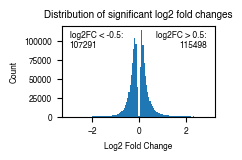

In [17]:
edger_df_log2FoldChange_filtered = edger_df_log2FoldChange[edger_df_padj < 0.05]

positive_values = (edger_df_log2FoldChange_filtered > 0.5).sum(axis=0)
negative_values = (edger_df_log2FoldChange_filtered < -0.5).sum(axis=0)
total_values = positive_values + negative_values

plt.figure(figsize=cm_to_inches((5, 3)))
plt.hist(edger_df_log2FoldChange_filtered.values.flatten(), bins=np.arange(-3, 3, 0.05))

# Calculate total positive and negative values
total_positive = np.sum(positive_values)
total_negative = np.sum(negative_values)

# Add text annotations for counts
plt.text(0.05, 0.95, f"log2FC < -0.5:\n{total_negative}", 
         transform=plt.gca().transAxes, 
         verticalalignment='top', 
         horizontalalignment='left',
         fontsize=6)

plt.text(0.95, 0.95, f"log2FC > 0.5:\n{total_positive}", 
         transform=plt.gca().transAxes, 
         verticalalignment='top', 
         horizontalalignment='right',
         fontsize=6)

plt.xlabel("Log2 Fold Change")
plt.ylabel("Count")
plt.title("Distribution of significant log2 fold changes")

for format in ["png", "svg"]:
    plt.savefig(os.path.join(plot_folder, f"1.4_edger_df_log2FoldChange_filtered_distribution.{format}"), bbox_inches="tight", dpi=300)

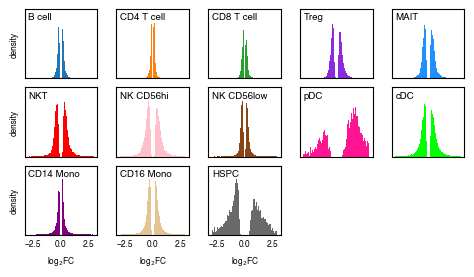

In [18]:
edger_df_log2FoldChange_filtered = edger_df_log2FoldChange[edger_df_padj < 0.05]

# Create subplots for each cell type
fig, axes = plt.subplots(3, 5, figsize=cm_to_inches((12, 7)))
fig.tight_layout(pad=2.0)

axes = axes.flatten()
for i, cell_type in enumerate(ALL_CELL_TYPES):
    # Filter data for this cell type
    cell_type_data = edger_df_log2FoldChange_filtered.xs(cell_type, level=0, axis=1)
    
    # Calculate positive and negative values for this cell type
    positive_values_cell = (cell_type_data > 0.5).sum(axis=0)
    negative_values_cell = (cell_type_data < -0.5).sum(axis=0)
    
    # Calculate totals
    total_positive_cell = np.sum(positive_values_cell)
    total_negative_cell = np.sum(negative_values_cell)
    
    # Plot histogram
    n, bins, patches = axes[i].hist(cell_type_data.values.flatten(), bins=np.arange(-3, 3, 0.05), density=True, color=CELL_TYPE_COLORS[cell_type])
    
    # Add labels
    axes[i].set_xlabel(f"log$_{2}$FC")
    axes[i].set_ylabel("density")
    axes[i].set_ylim(0, max(n) * 1.25)
    # Add title in the upper left corner
    axes[i].text(0.05, 0.95, f"{cell_type}", transform=axes[i].transAxes, 
                 va='top', ha='left', fontsize=7)
    axes[i].label_outer()
    
    # Set tick length to 0 for inner plots
    axes[i].tick_params(length=0)
    
    # Remove y ticks
    axes[i].set_yticks([])
    
# Delete unused plots
for i in range(len(ALL_CELL_TYPES), len(axes)):
    fig.delaxes(axes[i])
    
plt.tight_layout()
for format in ["png", "svg"]:
    plt.savefig(os.path.join(plot_folder, f"1.4_edger_df_log2FoldChange_filtered_distribution_by_cell_type.{format}"), bbox_inches="tight", dpi=300)

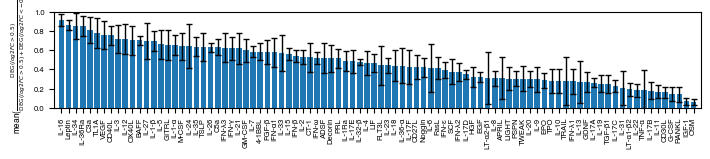

In [19]:
positive_values = positive_values[total_values > 10]
negative_values = negative_values[total_values > 10]
ratio = positive_values / (positive_values + negative_values)
ratio_mean = ratio.groupby(level=1).mean()
ratio_std = ratio.groupby(level=1).std()
ratio_mean = ratio_mean.sort_values(ascending=False)
ratio_std = ratio_std.loc[ratio_mean.index]

# Create a bar plot of the ratio of positive to total DEGs for each cytokine with error bars
plt.figure(figsize=cm_to_inches((18, 4)))
x_pos = range(len(ratio_mean))
bars = plt.bar(x_pos, ratio_mean.values, yerr=ratio_std.values, capsize=2, error_kw={'elinewidth': 1})
# Apply Greek letters to x-tick labels
x_labels = [introduce_greek_letters(lbl) for lbl in ratio_mean.index]
plt.xticks(x_pos, x_labels, rotation=90, fontsize=5.5)
plt.yticks(fontsize=5.5)
plt.ylabel(r'mean($\frac{\mathrm{DEG}(log2FC>0.5)}{\mathrm{DEG}(log2FC>0.5) + \mathrm{DEG}(log2FC<-0.5)}$)')

plt.ylim(0, 1)
plt.xlim(-1, len(ratio_mean))  # Reduce space on left and right of x-axis
plt.tight_layout()
for format in ["png", "svg"]:
    plt.savefig(os.path.join(plot_folder, f"1.4_ratio_of_positive_to_total_DEGs.{format}"), bbox_inches="tight", dpi=300)

## 1.5 - Alyssa's reference data

In [20]:
alyssa_secretion_df = pd.read_csv("immuneXpresso_alyssa/secretion_dataframe.csv")
alyssa_immunexpresso_df = pd.read_csv("immuneXpresso_alyssa/cytokine_effects_on_cells.csv")

In [21]:
# what fraction is in cytokine_info?
len(alyssa_immunexpresso_df[alyssa_immunexpresso_df["cytokine"].isin(cytokine_info.index)]) / len(alyssa_immunexpresso_df)

0.7773019271948608

In [22]:
alyssa_secretion_df["sumpapers"] = alyssa_secretion_df["sumpapers"].fillna(0)

In [23]:
# Create a reverse mapping dictionary for cell types
cell_type_mapping_alyssa = {
    "Monocyte": ["CD14 Mono", "CD16 Mono"],
    "NK cell": ["NK CD56low", "NK CD56hi"]
}

# Replace general cell types with our more specific cell types
# For each entry in alyssa's dataframes, if the Cell_Type is a general type (like "Monocyte"),
# create duplicate rows with each of our specific types (like "CD14 Mono", "CD16 Mono")

# Create new dataframes to store the expanded data
expanded_secretion_df = []
expanded_immunexpresso_df = []

# Process secretion dataframe
for _, row in alyssa_secretion_df.iterrows():
    cell_type = row["cell_type"]
    if isinstance(cell_type, str) and cell_type in cell_type_mapping_alyssa:
        # For each specific cell type, create a new row
        for specific_type in cell_type_mapping_alyssa[cell_type]:
            new_row = row.copy()
            new_row["cell_type"] = specific_type
            expanded_secretion_df.append(new_row)
    else:
        # Keep the original row
        expanded_secretion_df.append(row)

# Process immunexpresso dataframe
for _, row in alyssa_immunexpresso_df.iterrows():
    cell_type = row["cell_type"]
    if isinstance(cell_type, str) and cell_type in cell_type_mapping_alyssa:
        # For each specific cell type, create a new row
        for specific_type in cell_type_mapping_alyssa[cell_type]:
            new_row = row.copy()
            new_row["cell_type"] = specific_type
            expanded_immunexpresso_df.append(new_row)
    else:
        # Keep the original row
        expanded_immunexpresso_df.append(row)

# Convert lists back to dataframes
alyssa_secretion_df = pd.DataFrame(expanded_secretion_df)
alyssa_immunexpresso_df = pd.DataFrame(expanded_immunexpresso_df)

In [24]:
alyssa_secretion_df["cytokine"] = alyssa_secretion_df["cytokine"].apply(replace_greek_letters)
alyssa_immunexpresso_df["cytokine"] = alyssa_immunexpresso_df["cytokine"].apply(replace_greek_letters)

In [25]:
alyssa_secretion_df = alyssa_secretion_df[alyssa_secretion_df["cell_type"].isin(ALL_CELL_TYPES)]
alyssa_immunexpresso_df = alyssa_immunexpresso_df[alyssa_immunexpresso_df["cell_type"].isin(ALL_CELL_TYPES)]

In [26]:
alyssa_immunexpresso_df["total_interactions"] = alyssa_immunexpresso_df["Positive"] + alyssa_immunexpresso_df["Negative"] + alyssa_immunexpresso_df["Unknown"]

## 1.6 - spatial gene set and cytokine expression

In [27]:
df = pd.read_excel("polarization/all_effects.xlsx")

In [28]:
df = pd.read_excel("polarization/polarization_of_programs_interpretability.xlsx")
df['no_cytokines'] = df['relevant_cytokines'].apply(lambda x: len(x.split(',')))

In [29]:
df = df.sort_values(by=["program_title", "score"], ascending=False)

In [30]:
genes_by_program = df.groupby("program_title")["gene"].apply(list).to_dict()
genes_by_program = {program: genes[:10] for program, genes in genes_by_program.items()}

In [31]:
common_programs = df.drop_duplicates(subset=['program_title']).sort_values(by="no_cytokines", ascending=False).head(10)
common_programs['gene']

15357         FTL
14052       CXCL9
153           NHS
4090      CD163L1
18481    CPVL-AS2
28244      LINGO2
3400        OLFM1
23441      SLC1A3
33723      CCSER1
16647      IL31RA
Name: gene, dtype: object

In [32]:
genes_by_program['DR 19']

['FTL',
 'AIF1',
 'TYROBP',
 'IFI30',
 'S100A8',
 'IFITM3',
 'CST3',
 'FCER1G',
 'C1QA',
 'HCST']

In [33]:
common_programs.iloc[0]['relevant_cytokines']

'ADSF,APRIL,BAFF,CD27L,CD30L,CD40L,CT-1,Decorin,EGF,EPO,FGF-β,FasL,G-CSF,GITRL,GM-CSF,HGF,IFN-α1,IFN-β,IFN-ε,IFN-λ1,IFN-λ2,IFN-λ3,IFN-ω,IGF-1,IL-1-α,IL-1-β,IL-10,IL-11,IL-13,IL-15,IL-17A,IL-17B,IL-17C,IL-17E,IL-17F,IL-18,IL-19,IL-20,IL-22,IL-23,IL-3,IL-31,IL-32-β,IL-36-α,IL-36Ra,IL-4,IL-7,IL-9,LIF,LIGHT,M-CSF,Noggin,OSM,OX40L,RANKL,TGF-β1,TL1A,TRAIL,TSLP'

In [34]:
spatial_gene_set = pd.read_csv("../annotations/spatial_genes.csv")["gene_name"].tolist()

In [35]:
cytokine_genes = cytokine_info_parse["gene"]
cytokine_genes_in_spatial = []
for gene in cytokine_genes:
    gene = gene.split(", ")
    present = all([g in spatial_gene_set for g in gene])
    if present:
        cytokine_genes_in_spatial.append(', '.join(gene) if len(gene) > 1 else gene[0])
print(len(cytokine_genes_in_spatial))

57


# 2 - Summarize results

## 2.1 -  Calculate the magnitude of the response

In [36]:
plot_folder = os.path.join(base_plot_folder, "2_result_summary")
os.makedirs(plot_folder, exist_ok=True)

### 2.1.1 - Calculate Euclidean distances

In [37]:
from scipy.spatial.distance import euclidean
from scipy.stats import mstats

def compute_response_euclidean_distance(df, cell_type, cytokine, control="PBS"):
    """
    Compute the Euclidean distance between the treatment and control cytokine response for a given cell type.

    Parameters:
    - df (pd.DataFrame): A DataFrame containing gene expression data with a MultiIndex of genes,(cell_type, cytokine).
    - cell_type (str): The specific cell type for which the distance is to be computed.
    - cytokine (str): The treatment cytokine whose response is being compared.
    - control (str, optional): The control cytokine to compare against, default is "PBS".

    Returns:
    - float: The Euclidean distance between the treatment and control responses for the specified cell type and cytokine.
    """
    df_treatment = df.loc[:, (cell_type, cytokine)]
    df_control = df.loc[:, (cell_type, control)]
    
    # compute distance
    distance = euclidean(df_treatment.values.flatten(), df_control.values.flatten())
    
    return distance

def winsorize_and_normalize_distances(distances: pd.Series):
    """
    Winsorize and normalize the distances to a scale of 0 to 100.

    Parameters:
    - distances (pd.Series): A pandas Series containing the distances to be winsorized and normalized.

    Returns:
    - pd.Series: A pandas Series of the same index as the input, containing the normalized distances.
                 The distances are first winsorized to limit extreme values, then scaled to a range of 0 to 100.
    """
    # winsorize the distances (first limit: increase smallest values, second limit: decrease largest values)
    winsorized_distances = mstats.winsorize(distances, limits=[0, 0.05])
    # make it a pandas series with the same index
    winsorized_distances = pd.Series(winsorized_distances, index=distances.index)
    
    min_val, max_val = winsorized_distances.min(), winsorized_distances.max()
    normalized_distances = 100 * (winsorized_distances - min_val) / (max_val - min_val)
    
    return normalized_distances

In [38]:
all_normalized_euclidean_distances = {}
average_norm_sum_gene_count_df_log = np.log2(average_norm_sum_gene_count_df + 1)

for cell_type in ALL_CELL_TYPES:
    distances = {}
    
    # get the inclusive filter and average normalized log2 data
    all_inclusive_filter = inclusive_filters_by_cell_type[cell_type]
    average_norm_filter = average_norm_sum_gene_count_df_log.loc[all_inclusive_filter, :]
    
    for cytokine in CYTOKINE_ORDER:
        distance = compute_response_euclidean_distance(average_norm_filter, cell_type, cytokine)
        distances[cytokine] = distance
    distances_series = pd.Series(distances)
    
    all_normalized_euclidean_distances[cell_type] = winsorize_and_normalize_distances(distances_series)
    
all_normalized_euclidean_distances = pd.DataFrame(all_normalized_euclidean_distances)

In [39]:
%%capture output

for cell_type in ALL_CELL_TYPES:
    plt.figure(figsize=(3, 2.4))
    plt.hist(all_normalized_euclidean_distances[cell_type])
    plt.xlabel("Euclidean distance")
    plt.ylabel("Count")
    plt.title(cell_type)
    plt.tight_layout()
    plt.savefig(os.path.join(plot_folder, f"2.1_normalized_euclidean_distance_{cell_type}.png"), bbox_inches="tight", dpi=300)

### 2.1.2 - Calculate p-value distances

R_{\text{strength}} = \sum_{i=1}^{N} \left| \log_2 \text{FC}_i \right| \cdot -\log_{10}(p_{\text{adj},i})

In [40]:
# get the absolute value of the log2 fold change
# the filled values will drop out in the sum
edger_df_log2FoldChange_abs = edger_df_log2FoldChange.fillna(0).abs()
edger_df_padj_fillna = edger_df_padj.fillna(1).copy()

# cap the p-values at 1e-10 and log10-transform
edger_df_padj_fillna = edger_df_padj_fillna.clip(lower=1e-10)
edger_df_padj_fillna = -np.log10(edger_df_padj_fillna)

# this implements the formula above
all_logfoldchange_padj_distances = edger_df_log2FoldChange_abs * edger_df_padj_fillna
all_logfoldchange_padj_distances = all_logfoldchange_padj_distances.sum()

# make it a dataframe (cytokine x cell_type)
all_logfoldchange_padj_distances = all_logfoldchange_padj_distances.unstack(level=0)
all_logfoldchange_padj_distances = all_logfoldchange_padj_distances.loc[CYTOKINE_ORDER]

# apply normalization and winsorization
for cell_type in ALL_CELL_TYPES:
    distances_series = all_logfoldchange_padj_distances[cell_type]
    all_logfoldchange_padj_distances[cell_type] = winsorize_and_normalize_distances(distances_series)

In [41]:
test = edger_df_log2FoldChange.notna().sum()
test = test[test < 500]
test

pDC  IL-10         0
     IL-32-beta    0
dtype: int64

In [42]:
import plotly.express as px
import pandas as pd

# Create a DataFrame for plotting
plot_data = pd.DataFrame({
    'x': all_normalized_euclidean_distances['pDC'],
    'y': all_logfoldchange_padj_distances['pDC'],
    'cytokine': all_normalized_euclidean_distances['pDC'].index
})

fig = px.scatter(plot_data, x='x', y='y', hover_name='cytokine',
                 labels={'x': 'Normalized Euclidean distance',
                         'y': 'Log2FC * -log10(padj)'})
fig.show()

### 2.1.3 - Merge distance measurements and calculate thresholds for a strong response

C:\Users\loesi\AppData\Local\Temp\ipykernel_37688\3484729529.py:15: UserWarning:

Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.



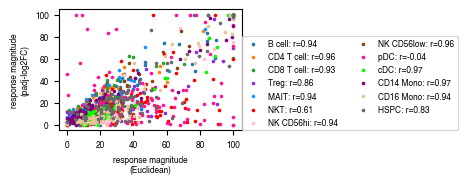

In [43]:
plt.figure(figsize=cm_to_inches((6, 4)))
for cell_type in ALL_CELL_TYPES:
    r = np.corrcoef(all_normalized_euclidean_distances[cell_type],
                all_logfoldchange_padj_distances[cell_type])
    plt.scatter(all_normalized_euclidean_distances[cell_type],
                all_logfoldchange_padj_distances[cell_type],
                label=f"{cell_type}: r={r[0, 1]:.2f}",
                color=CELL_TYPE_COLORS[cell_type],
                s = 2.5,
                alpha=1)
    
plt.xlabel("response magnitude\n(Euclidean)")
plt.ylabel("response magnitude\n(padj-log2FC)")
plt.legend(loc=[1,0], fontsize=6, ncol=2)
plt.tight_layout()
for format in ["png", "svg"]:
    plt.savefig(os.path.join(plot_folder, f"2_normalized_distance_comparison.{format}"), bbox_inches="tight", dpi=300)

In [44]:
# merge the two distance measurements
all_normalized_distances_mean = (all_normalized_euclidean_distances + all_logfoldchange_padj_distances) / 200
# reset to the correct order
all_normalized_distances_mean = all_normalized_distances_mean[ALL_CELL_TYPES]
# calculate relative distances (divide by the max distance for each cytokine)
all_relative_distances_mean = all_normalized_distances_mean.div(all_normalized_distances_mean.max(axis=1), axis=0)

In [45]:
# all_normalized_distances_mean = all_normalized_euclidean_distances[ALL_CELL_TYPES].copy() / 100
# nces_mean = all_normalized_distances_mean.div(all_normalized_distances_mean.max(axis=1), axis=0)

In [46]:
def convert_to_percentile_along_axis(df, axis, granularity=5):
    """Convert values to percentile ranks along specified axis with given granularity.
    
    Args:
        df: pandas DataFrame to convert
        axis: 0 for columns, 1 for rows 
        granularity: Size of percentile bins (e.g. 5 means bins of 0-5%, 5-10%, etc)
        
    Returns:
        DataFrame with values converted to percentile ranks
    """
    # Calculate percentile rank along axis
    percentile_df = df.rank(axis=axis, pct=True) * 100
    
    # Round to nearest granularity value
    percentile_df = (percentile_df / granularity).round() * granularity
    
    return percentile_df

all_normalized_distances_percentile = convert_to_percentile_along_axis(all_normalized_distances_mean, axis=0, granularity=5)

In [47]:
# calculate the magntiude threshold for each cell type
magnitude_threshold_by_cell_type = {}
for cell_type in ALL_CELL_TYPES:
    # get the mean of the low percentile cytokines
    low_percentile = all_normalized_distances_percentile[cell_type] < 35
    low_percentile_cytokines = low_percentile.index[low_percentile]
    low_percentile_mean = all_normalized_distances_mean[cell_type][low_percentile_cytokines].mean()
    
    # set the threshold to 3x the mean of the low percentile cytokines
    magnitude_threshold_by_cell_type[cell_type] = 3*low_percentile_mean
    
strong_impact_by_cell_type = {}
for cell_type in ALL_CELL_TYPES:
    strong_impact_by_cell_type[cell_type] = all_normalized_distances_mean[cell_type] > magnitude_threshold_by_cell_type[cell_type]
strong_impact_by_cell_type = pd.DataFrame(strong_impact_by_cell_type, index=all_normalized_distances_mean.index)

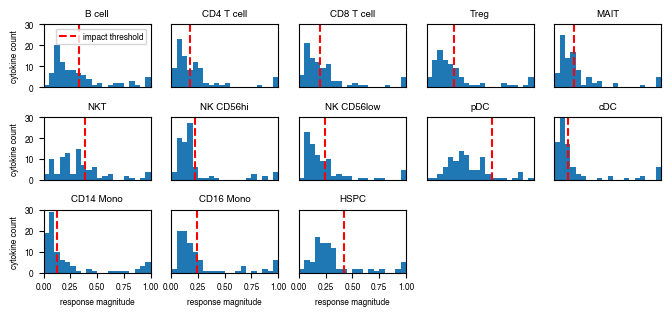

In [48]:
# Create a figure with subplots arranged in a grid
n_cell_types = len(ALL_CELL_TYPES)
n_rows = 3 
n_cols = 5
fig, axes = plt.subplots(n_rows, n_cols, figsize=cm_to_inches((17, 8)))

# Flatten axes array for easier iteration
axes_flat = axes.flatten()

for idx, cell_type in enumerate(ALL_CELL_TYPES):
    ax = axes_flat[idx]
    ax.hist(all_normalized_distances_mean[cell_type].values, bins=np.arange(0, 1.05, 0.05))
    ax.axvline(magnitude_threshold_by_cell_type[cell_type], color="red", linestyle="--", label="impact threshold" if idx == 0 else "")
    if idx % n_cols == 0:  # Only show y-label on leftmost plots
        ax.set_ylabel("cytokine count")
    else:
        ax.set_yticks([])
    if idx >= n_cols * (n_rows-1):  # Only show x-label on bottom plots
        ax.set_xlabel("response magnitude")
    else:
        ax.set_xticks([])
    ax.set_title(cell_type, fontsize=7)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 30)
    if idx == 0:
        ax.legend(fontsize=6)

# Remove any empty subplots
for idx in range(len(ALL_CELL_TYPES), len(axes_flat)):
    fig.delaxes(axes_flat[idx])

plt.tight_layout()

# Save the figure
for format in ["png", "svg"]:
    plt.savefig(os.path.join(plot_folder, f"2_distance_distributions.{format}"), bbox_inches="tight", dpi=300)

In [49]:
all_normalized_distances_mean.to_csv(os.path.join(output_tables_folder, "2_response_magnitudes.csv"))
strong_impact_by_cell_type.to_csv(os.path.join(output_tables_folder, "2_strong_impact.csv"))
pd.Series(magnitude_threshold_by_cell_type).to_csv(os.path.join(output_tables_folder, "2_response_magnitude_thresholds.csv"))

## 2.2 - Create an overview plot for DEGs and the response magnitude

In [50]:
# Load filtered DEGs
filtered_DEGs_consistency = pd.read_csv(os.path.join(output_tables_folder, "external_filtered_padj_by_consistency.csv"), index_col=0, header=[0,1])
filtered_DEGs_consistency = filtered_DEGs_consistency[ALL_CELL_TYPES]
edger_df_padj_orig = edger_df_padj.copy()
edger_df_padj = filtered_DEGs_consistency

if not os.path.exists(os.path.join(output_tables_folder, "2_edger_df_padj_filtered.csv")):
    edger_df_padj.to_csv(os.path.join(output_tables_folder, "2_edger_df_padj_filtered.csv"))

In [51]:
significant_results = pd.DataFrame(index=ALL_CELL_TYPES, columns=CYTOKINE_ORDER, data=0)
for cell_line in ALL_CELL_TYPES:
    padj_df = edger_df_padj[cell_line]
    num_significant = (padj_df < 0.05).sum(axis=0)
    significant_results.loc[cell_line, CYTOKINE_ORDER] = num_significant[CYTOKINE_ORDER].values

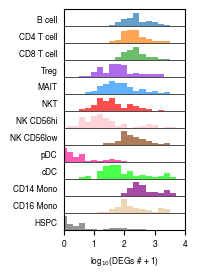

In [52]:
# Create a figure for histograms of log10(significant genes+1) per cell type
plt.figure(figsize=cm_to_inches((5, 7)))
ax = plt.gca()

# Calculate log10 of significant results (adding 1 to avoid log(0))
log_significant = np.log10(significant_results + 1)

# Define vertical offset between histograms
offset = 0.5

# Plot histograms for each cell type with vertical offset
for i, cell_type in enumerate(ALL_CELL_TYPES[::-1]):
    # Get data for this cell type
    data = log_significant.loc[cell_type].values
    
    # Create histogram
    counts, bins = np.histogram(data, bins=20, range=(0, 4))
    
    # Normalize counts to have similar heights
    if counts.max() > 0:
        counts = counts / counts.max() * 0.4
    
    # Plot histogram with vertical offset
    plt.bar(bins[:-1], counts, width=bins[1]-bins[0], bottom=i*offset, 
            alpha=0.7, label=cell_type if i == 0 else "", color=CELL_TYPE_COLORS[cell_type])
    
    # Add cell type label
    plt.text(-0.2, i*offset + 0.2, cell_type, ha='right', va='center', fontsize=6)
    
    # Add a horizontal line at the bottom of each histogram instead of a box
    plt.plot([0, 4], [i*offset, i*offset], color='black', linestyle='-', linewidth=0.5)

# Set axis labels and title
plt.xlabel(r'log$_{10}$(DEGs # + 1)')
plt.yticks([])
plt.xlim(0, 4)
plt.ylim(0, len(ALL_CELL_TYPES)*offset)

plt.tight_layout()
# # Save the figure
for format in ["png", "svg"]:
    plt.savefig(os.path.join(plot_folder, f"2_DEG_distributions.{format}"), bbox_inches="tight", dpi=300)

#### Create a long df for scatter plots

In [53]:
data_long = significant_results.reset_index().rename(columns={'index': 'cell_type'})
data_long = data_long.melt(id_vars=['cell_type'], var_name='cytokine', value_name='DEGs')

# Convert Cytokine column to a categorical type with specified order
data_long['cytokine'] = pd.Categorical(data_long['cytokine'], categories=CYTOKINE_ORDER, ordered=True)

# Sort data_long by the categorical order to ensure plotting follows this order
data_long = data_long.sort_values(by='cytokine', ascending=False)

In [54]:
bin_sizes = [10, 33, 100, 333, 1000, 3333, 10000, 10E6]
bin_text = ["<10", "<33", "<100", "<333", "<1000", "<3333", "<10000", ">10000"]

def bin_DEG_numbers(x):
    if x <= bin_sizes[0]:
        return 1
    if x <= bin_sizes[1]:
        return 2
    elif x <= bin_sizes[2]:
        return 3
    elif x <= bin_sizes[3]:
        return 4
    elif x <= bin_sizes[4]:
        return 5
    elif x <= bin_sizes[5]:
        return 6
    elif x <= bin_sizes[6]:
        return 7
    else:
        return 8
    
data_long["binned_DEGs"] = data_long["DEGs"].apply(bin_DEG_numbers)    

In [55]:
all_normalized_distances_long = all_normalized_distances_mean.reset_index().rename(columns={'index': 'cytokine'})
all_normalized_distances_long = all_normalized_distances_long.melt(id_vars=['cytokine'], var_name='cell_type', value_name='Distance')

# clip at 0 and 1 (should basically be already the case)
all_normalized_distances_long["Distance"] = all_normalized_distances_long["Distance"].clip(lower=0, upper=1)

# merge with the DEGs
data_long = data_long.merge(all_normalized_distances_long, on=["cytokine", "cell_type"])

In [56]:
def plot_overview_labels_along_y_axis(fig, ax, labels, vals_per_label, x_offset, no_y_vals,
                                      fontsize=7, fontweight="bold", color="black", linewidth=1, stagger=0,
                                      rotation=90):
    # Get the y-axis tick positions
    y_ticks = ax.get_yticks()
    
    # Get the first and last tick positions
    y_top = y_ticks[-1]
    y_bottom = y_ticks[0]
    
    total_distance = y_top - y_bottom
    step_per_label = total_distance / (no_y_vals - 1)
    
    # Freeze the current plot limits
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    
    cumulative_vals = 0
    for index, label in enumerate(labels):
        y_pos = y_top - step_per_label * (cumulative_vals + vals_per_label[label]/2 - 0.5)
        curr_x_val = x_offset + stagger * (index % 2)
        
        if not "empty" in label and vals_per_label[label] > 0:
            # Add text annotations
            ax.text(
                curr_x_val,
                y_pos,
                label,
                ha='right',
                va='center',
                fontsize=fontsize,
                fontweight=fontweight,
                color=color,
                rotation=rotation,
                transform=ax.transData
            )
            
            adjustment_for_single_value = 0.4 if vals_per_label[label] == 1 else 0
            
            # Draw vertical line
            ax.plot(
                [curr_x_val + 0.2, curr_x_val + 0.2],
                [y_top - step_per_label * (cumulative_vals) + adjustment_for_single_value, 
                y_top - step_per_label * (cumulative_vals + vals_per_label[label] - 1) - adjustment_for_single_value],
                color=color,
                linewidth=linewidth,
                clip_on=False,
                zorder=0  # Ensures it doesn't interfere with other plot elements
            )
        
        cumulative_vals += vals_per_label[label]
    
    # Restore original plot limits to prevent them from changing
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

#### Plotting of absolute DEG numbers

c:\Users\loesi\Dropbox\parse_pbmc data\HumanCytokineDict\code_lukas\unicode_utils.py:151: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

c:\Users\loesi\Dropbox\parse_pbmc data\HumanCytokineDict\code_lukas\unicode_utils.py:155: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

C:\Users\loesi\AppData\Local\Temp\ipykernel_37688\275752635.py:57: UserWarning:

Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.



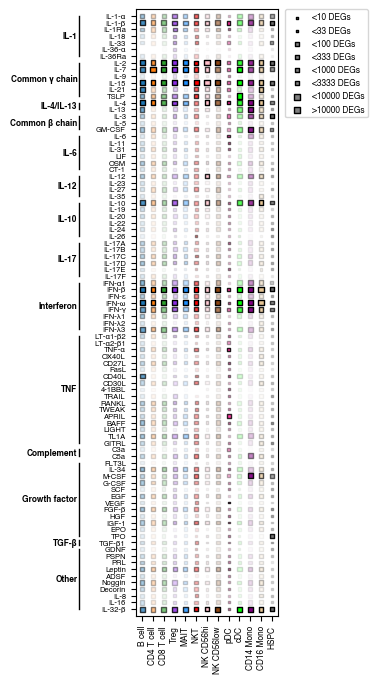

In [57]:
fig, ax = plt.subplots(figsize=cm_to_inches((5, 20)))

# Scatter plot with square markers; `s` controls the marker size, which we scale here by 'DEGs' values
for cell_type in ALL_CELL_TYPES:
    subset = data_long[data_long['cell_type'] == cell_type]
    ax.scatter(
        subset['cell_type'], subset['cytokine'],
        s=subset['binned_DEGs'] * 2,  # Scale sizes as needed
        marker='s', c=[CELL_TYPE_COLORS[cell_type]], edgecolor='k',
        label=cell_type,
        alpha=subset['Distance']  # Scale alpha by 'Distance' values
    )

x_offset_level1 = -6  # Horizontal placement offset for family labels
vals_per_label_level1 = cytokine_info_order["DEG_plot_family"].value_counts()
plot_overview_labels_along_y_axis(fig, ax, SINGLE_FAMILY_ORDER, vals_per_label_level1, x_offset_level1,
                                  len(subset['cytokine']),
                                  fontsize=6, fontweight="bold", color="black", linewidth=1,
                                  rotation=0)

# x_offset_level2 = -5  # Horizontal placement offset for family labels
# vals_per_label_level2 = cytokine_info["level2_family"].value_counts()
# plot_overview_labels_along_y_axis(fig, ax, level2_family_labels, vals_per_label_level2, x_offset_level2,
#                                   len(subset['cytokine']),
#                                   fontsize=6, fontweight="normal", color="gray", linewidth=0.5)


# Create legend for DEG numbers
legend_elements = []
for bin_size, bin_label in zip(bin_sizes, bin_text):
    legend_elements.append(
        plt.scatter([], [], 
                   s=bin_DEG_numbers(bin_size) * 2,  # Base size matching the main plot
                   marker='s',
                   color='gray',
                   edgecolor='k',
                   label=f'{bin_label} DEGs')
    )

# Add the legend
leg = plt.legend(handles=legend_elements,
                bbox_to_anchor=(1.05, 1),
                loc='upper left',
                borderaxespad=0,
                fontsize=6)

# Adjust layout to make room for legend
plt.subplots_adjust(right=0.85)

# rotate x-axis labels
plt.xticks(rotation=90)
ax.set_ylim(-1, len(CYTOKINE_ORDER))
apply_greek_labels_heatmap(ax)
# set label font size to 6
plt.yticks(fontsize=5.5)

plt.tight_layout()
for format in ["png", "svg"]:
    plt.savefig(os.path.join(plot_folder, f"2_DEG_numbers_by_cell_type.{format}"), 
                bbox_inches="tight", 
                dpi=300)

#### Plotting of relative DEG numbers

In [58]:
# pure maximum
data_long["max"] = data_long.groupby("cell_type")["DEGs"].transform("max")

# clip at at most 5% so that the dot size doesn't become too small
data_long["DEGs_clip"] = data_long.apply(lambda x: max(x["DEGs"], x["max"]/20.0), axis=1)
data_long["DEG_rel"] = data_long["DEGs_clip"] / data_long["max"]

# show the response magnitude as quintiles
data_long["distance_quintile"] = (pd.qcut(data_long["Distance"], q=5, labels=False) + 1) / 5

In [59]:
data_long[["cytokine", 'cell_type', "DEG_rel"]]

,cytokine,cell_type,DEG_rel
0,IL-32-beta,HSPC,0.794118
1,IL-32-beta,NK CD56hi,0.224271
2,IL-32-beta,B cell,0.386310
3,IL-32-beta,CD4 T cell,0.352019
4,IL-32-beta,CD8 T cell,0.340066
...,...,...,...
1165,IL-1-alpha,cDC,0.118011
1166,IL-1-alpha,CD14 Mono,0.297210
1167,IL-1-alpha,CD16 Mono,0.222281
1168,IL-1-alpha,HSPC,0.100490


c:\Users\loesi\Dropbox\parse_pbmc data\HumanCytokineDict\code_lukas\unicode_utils.py:151: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

c:\Users\loesi\Dropbox\parse_pbmc data\HumanCytokineDict\code_lukas\unicode_utils.py:155: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.



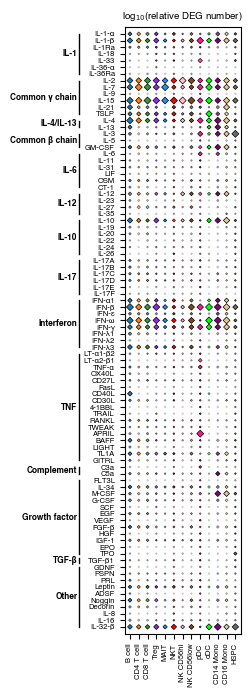

In [60]:
# Plotting
#fig, ax = plt.subplots(figsize=cm_to_inches((4.2, 20)))
fig, ax = plt.subplots(figsize=cm_to_inches((3.8, 20)))

# Scatter plot with square markers; `s` controls the marker size, which we scale here by 'DEGs' values
for cell_type in ALL_CELL_TYPES:
    subset = data_long[data_long['cell_type'] == cell_type]
    ax.scatter(
        subset['cell_type'], subset['cytokine'],
        s=np.log10(subset['DEG_rel']+1) * 42,
        marker='D', c=[CELL_TYPE_COLORS[cell_type]], edgecolor='k',
        alpha=subset['distance_quintile'],
        linewidth=0.5
    )


x_offset_level1 = -6  # Horizontal placement offset for family labels
vals_per_label_level1 = cytokine_info_order["DEG_plot_family"].value_counts()

plot_overview_labels_along_y_axis(fig, ax, SINGLE_FAMILY_ORDER, vals_per_label_level1, x_offset_level1,
                                  len(subset['cytokine']),
                                  fontsize=6, fontweight="bold", color="black", linewidth=1,
                                  rotation=0)

fig.canvas.draw()
ax.set_ylim(-1, len(CYTOKINE_ORDER))
apply_greek_labels_heatmap(ax)

plt.title(r"log$_{10}$(relative DEG number)",fontsize=7)
plt.xticks(rotation=90, fontsize=5.5)
# set label font size to 6
plt.yticks(fontsize=5.5)

# plt.tight_layout()
for format in ["png", "svg"]:
    plt.savefig(os.path.join(plot_folder, f"2_relative_DEG_numbers_by_cell_type.{format}"), bbox_inches="tight", dpi=300)

#### Calculate and plot supplementary barplots (tsi, total DEGs, strong impact)

In [61]:
# subtract threshold values!!!
def calc_tsi(df, cytokine, column):
    cytokine_df = df[df["cytokine"] == cytokine]
    threshold_values = [magnitude_threshold_by_cell_type[c]/2.0 for c in cytokine_df['cell_type']]
    values = cytokine_df[column].values - threshold_values
    values = [max(v, 0.05) for v in values]
    max_value = np.max(values)
    if any(strong_impact_by_cell_type.loc[cytokine].values):
        tsi = sum((1-values/max_value)/(len(values)-1))
    else:
        tsi = 0
    return tsi

tsi_by_cytokine = {}
for cytokine in CYTOKINE_ORDER:
    tsi =  calc_tsi(data_long[data_long["cell_type"].isin(ALL_CELL_TYPES_EXCLUDE)], cytokine, "Distance")
    tsi_by_cytokine[cytokine] = tsi
    
tsi_by_cytokine = pd.Series(tsi_by_cytokine)    

c:\Users\loesi\Dropbox\parse_pbmc data\HumanCytokineDict\code_lukas\unicode_utils.py:151: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

c:\Users\loesi\Dropbox\parse_pbmc data\HumanCytokineDict\code_lukas\unicode_utils.py:155: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

C:\Users\loesi\AppData\Local\Temp\ipykernel_37688\2734904583.py:16: UserWarning:

Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.



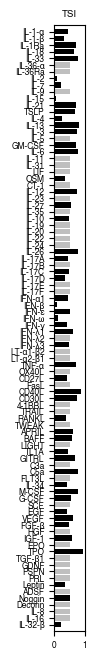

In [62]:
# need to invert the order due to the way that the heatmap is plotted
tsi_by_cytokine = tsi_by_cytokine[CYTOKINE_ORDER[::-1]]
tsi_by_cytokine_0 = tsi_by_cytokine[tsi_by_cytokine == 0]

# make a horizontal bar plot
plt.figure(figsize=cm_to_inches((1, 20)))
plt.barh(tsi_by_cytokine.index, tsi_by_cytokine.values, color="black")
plt.barh(tsi_by_cytokine_0.index, 0.5, color="gray", alpha=0.5)
plt.ylim(-1, len(CYTOKINE_ORDER))
# get the current figure and draw it (to get apply_greek_labels_heatmap to work)
fig = plt.gcf()
fig.canvas.draw()
apply_greek_labels_heatmap(plt.gca())
plt.xticks(np.arange(0, 1.1, 1), [0, 1], rotation=0, fontsize=6)
plt.title("TSI", fontsize=7)
plt.tight_layout()
for format in ["png", "svg"]:
    plt.savefig(os.path.join(plot_folder, f"2_tsi_by_cytokine.{format}"), bbox_inches="tight", dpi=300)

c:\Users\loesi\Dropbox\parse_pbmc data\HumanCytokineDict\code_lukas\unicode_utils.py:151: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

c:\Users\loesi\Dropbox\parse_pbmc data\HumanCytokineDict\code_lukas\unicode_utils.py:155: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.



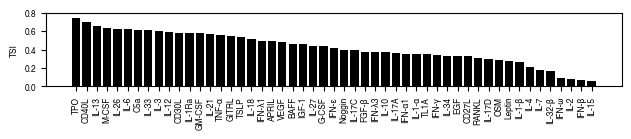

In [63]:
tsi_by_cytokine_filter = tsi_by_cytokine[tsi_by_cytokine > 0].sort_values(ascending=False)
plt.figure(figsize=cm_to_inches((16, 3.5)))
plt.bar(tsi_by_cytokine_filter.index, tsi_by_cytokine_filter.values, color="black")
plt.xticks(rotation=90)
apply_greek_labels_heatmap(plt.gca())
plt.ylabel("TSI")
plt.ylim(0, 1)
plt.tight_layout()
for format in ["png", "svg"]:
    plt.savefig(os.path.join(plot_folder, f"2_tsi_by_cytokine_flat.{format}"), dpi=300)

c:\Users\loesi\Dropbox\parse_pbmc data\HumanCytokineDict\code_lukas\unicode_utils.py:151: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

c:\Users\loesi\Dropbox\parse_pbmc data\HumanCytokineDict\code_lukas\unicode_utils.py:155: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

C:\Users\loesi\AppData\Local\Temp\ipykernel_37688\1827391358.py:13: UserWarning:

Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.



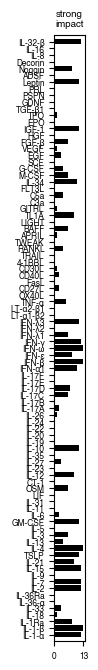

In [64]:
strong_impact_by_cytokine = strong_impact_by_cell_type.sum(axis=1)

# make a horizontal bar plot
plt.figure(figsize=cm_to_inches((1, 20)))
plt.barh(strong_impact_by_cytokine.index, strong_impact_by_cytokine.values, color="black")
plt.ylim(-1, len(CYTOKINE_ORDER))
# get the current figure and draw it (to get apply_greek_labels_heatmap to work)
fig = plt.gcf()
fig.canvas.draw()
apply_greek_labels_heatmap(plt.gca())
plt.xticks([0, len(ALL_CELL_TYPES)], [0, len(ALL_CELL_TYPES)], rotation=0, fontsize=6)
plt.title("strong\nimpact", fontsize=7)
plt.tight_layout()
for format in ["png", "svg"]:
    plt.savefig(os.path.join(plot_folder, f"2_strong_impact_by_cytokine.{format}"), bbox_inches="tight", dpi=300)

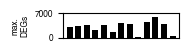

In [65]:
# get the max DEGs per cell type
max_DEGs_by_cell_type = data_long.groupby("cell_type")["DEGs"].max()
max_DEGs_by_cell_type = max_DEGs_by_cell_type[ALL_CELL_TYPES]
# plot the max DEGs per cell type
#plt.figure(figsize=cm_to_inches((5.36, 1.3)))
plt.figure(figsize=cm_to_inches((4.75, 1.3)))
plt.bar(max_DEGs_by_cell_type.index, max_DEGs_by_cell_type.values, color="black", width=0.7)
plt.xticks([])
plt.ylabel("max.\nDEGs")
# cut whitespace at left and right
plt.xlim(-0.75, len(ALL_CELL_TYPES)-0.25)
#plt.yticks([0, 7000], ["0", r"$7\cdot 10^{3}$"])
plt.yticks([0, 7000], ["0", r"7000"])
plt.ylim(0, 7000)
plt.tight_layout()
for format in ["png", "svg"]:
    plt.savefig(os.path.join(plot_folder, f"2_max_DEGs_by_cell_type.{format}"), bbox_inches="tight", dpi=300)


In [279]:
test = strong_impact_by_cell_type.drop(columns=['pDC']).sum(axis=1)
test = test[test == 2]
test

IL-17A    2
CD27L     2
CD40L     2
dtype: int64

In [280]:
strong_impact_by_cell_type.loc["CD40L"]

B cell         True
CD4 T cell    False
CD8 T cell    False
Treg          False
MAIT          False
NKT           False
NK CD56hi     False
NK CD56low    False
pDC           False
cDC            True
CD14 Mono     False
CD16 Mono     False
HSPC          False
Name: CD40L, dtype: bool

## 2.3 - Additional response magnitude plots

In [66]:
strong_impact_by_cell_type_long = strong_impact_by_cell_type.melt(var_name="cell_type", value_name="strong_impact", ignore_index=False).reset_index().rename({"index": "cytokine"}, axis=1)
data_long = pd.merge(data_long, strong_impact_by_cell_type_long, on=["cell_type", "cytokine"])

In [67]:
data_long = pd.merge(data_long, alyssa_immunexpresso_df, on=["cell_type", "cytokine"], how="left")

In [68]:
fraction_strong = []
total_captured = []
for i in range(20):
    df = data_long.dropna(subset="total_interactions")
    df = df[df["total_interactions"] > i]
    fraction = df["strong_impact"].sum() / len(df)
    fraction_strong.append(fraction)
    
    total_captured.append(df["strong_impact"].sum())

In [69]:
strong_impact_by_cell_type.loc["TNF-alpha"]

B cell        False
CD4 T cell     True
CD8 T cell     True
Treg          False
MAIT          False
NKT            True
NK CD56hi     False
NK CD56low    False
pDC            True
cDC           False
CD14 Mono      True
CD16 Mono     False
HSPC          False
Name: TNF-alpha, dtype: bool

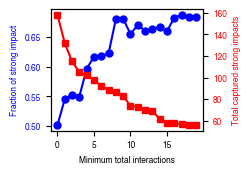

In [70]:
# Create figure with two y-axes
fig, ax1 = plt.subplots(figsize=cm_to_inches((5,4)))
ax2 = ax1.twinx()

# Plot fraction_strong on left y-axis
ax1.plot(np.arange(0, 20, 1), fraction_strong, color='blue', marker='o', markersize=5)
ax1.set_xlabel('Minimum total interactions')
ax1.set_ylabel('Fraction of strong impact', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

# Plot total_captured on right y-axis
ax2.plot(np.arange(0, 20, 1), total_captured, color='red', marker='s', markersize=5)
ax2.set_ylabel('Total captured strong impacts', color='red')
ax2.tick_params(axis='y', labelcolor='red')

In [71]:
data_long["xpresso"] = data_long["total_interactions"] > 9

c:\Users\loesi\Dropbox\parse_pbmc data\HumanCytokineDict\code_lukas\unicode_utils.py:151: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

c:\Users\loesi\Dropbox\parse_pbmc data\HumanCytokineDict\code_lukas\unicode_utils.py:155: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.



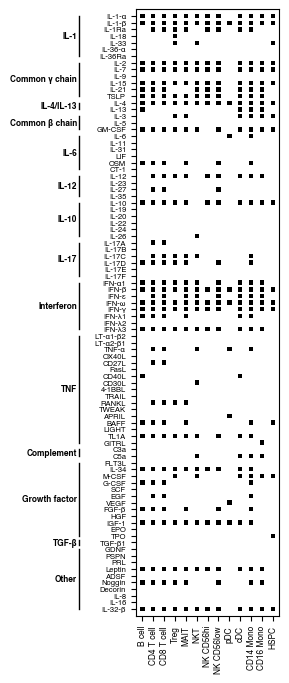

In [72]:
# Plotting
fig, ax = plt.subplots(figsize=cm_to_inches((4.7, 20)))

# Scatter plot with square markers; `s` controls the marker size, which we scale here by 'DEGs' values
for cell_type in ALL_CELL_TYPES:
    subset = data_long[data_long['cell_type'] == cell_type]
    ax.scatter(
        subset['cell_type'], subset['cytokine'],
        s = 10 * subset['strong_impact'].astype(int),
        marker='s', c="black", edgecolor="black", #c=[CELL_TYPE_COLORS[cell_type]], edgecolor='k',
        linewidth=0,
    )

    # ax.scatter(
    #     subset['cell_type'], subset['cytokine'],
    #     s = 10 * subset['xpresso'].astype(int),
    #     marker='s', facecolors="none",
    #     edgecolors='green', linewidth=1,
    # )


x_offset_level1 = -6  # Horizontal placement offset for family labels
vals_per_label_level1 = cytokine_info_order["DEG_plot_family"].value_counts()

plot_overview_labels_along_y_axis(fig, ax, SINGLE_FAMILY_ORDER, vals_per_label_level1, x_offset_level1,
                                  len(subset['cytokine']),
                                  fontsize=6, fontweight="bold", color="black", linewidth=1,
                                  rotation=0)

fig.canvas.draw()
ax.set_ylim(-1, len(CYTOKINE_ORDER))
apply_greek_labels_heatmap(ax)

# plt.title(r"log$_{10}$(relative DEG number)",fontsize=7)
plt.xticks(rotation=90, fontsize=6)
# set label font size to 6
plt.yticks(fontsize=5.5)

#plt.tight_layout()
for format in ["png", "svg"]:
    plt.savefig(os.path.join(plot_folder, f"2.3_strong_impact_vs_expresso.{format}"), bbox_inches="tight", dpi=300)

c:\Users\loesi\Dropbox\parse_pbmc data\HumanCytokineDict\code_lukas\unicode_utils.py:151: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

c:\Users\loesi\Dropbox\parse_pbmc data\HumanCytokineDict\code_lukas\unicode_utils.py:155: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.



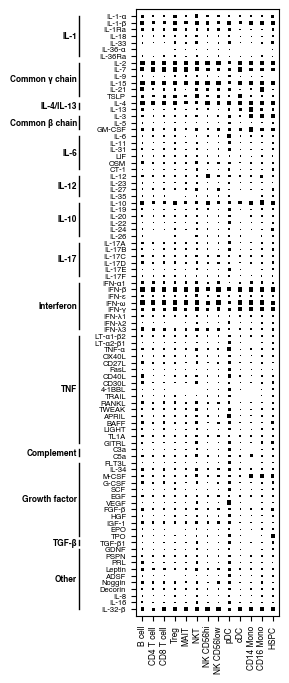

In [73]:
# Plotting
fig, ax = plt.subplots(figsize=cm_to_inches((4.7, 20)))

# Scatter plot with square markers; `s` controls the marker size, which we scale here by 'DEGs' values
for cell_type in ALL_CELL_TYPES:
    subset = data_long[data_long['cell_type'] == cell_type]
    ax.scatter(
        subset['cell_type'], subset['cytokine'],
        s = 10 * subset['Distance'],
        marker='s', c="black", edgecolor="black", #c=[CELL_TYPE_COLORS[cell_type]], edgecolor='k',
        linewidth=0,
    )

    # ax.scatter(
    #     subset['cell_type'], subset['cytokine'],
    #     s = 10 * subset['strong_impact'].astype(int),
    #     marker='s', facecolors="none",
    #     edgecolors='green', linewidth=1,
    # )


x_offset_level1 = -6  # Horizontal placement offset for family labels
vals_per_label_level1 = cytokine_info_order["DEG_plot_family"].value_counts()

plot_overview_labels_along_y_axis(fig, ax, SINGLE_FAMILY_ORDER, vals_per_label_level1, x_offset_level1,
                                  len(subset['cytokine']),
                                  fontsize=6, fontweight="bold", color="black", linewidth=1,
                                  rotation=0)

fig.canvas.draw()
ax.set_ylim(-1, len(CYTOKINE_ORDER))
apply_greek_labels_heatmap(ax)

# plt.title(r"log$_{10}$(relative DEG number)",fontsize=7)
plt.xticks(rotation=90, fontsize=6)
# set label font size to 6
plt.yticks(fontsize=5.5)

#plt.tight_layout()
for format in ["png", "svg"]:
    plt.savefig(os.path.join(plot_folder, f"2.3_response_magnitude_by_size.{format}"), bbox_inches="tight", dpi=300)

# 3 - Literature responses
#### Receptor expression and expected responses

In [74]:
plot_folder = os.path.join(base_plot_folder, "3_literature_responses")
os.makedirs(plot_folder, exist_ok=True)

## 3.1 - Receptor expression

In [75]:
def get_receptor_expression(average_control_expression, cytokine):
    receptor_genes_all = str(cytokine_info_parse.loc[cytokine, "receptor gene"])
    if receptor_genes_all == "nan":
        print(f"No receptor genes found for {cytokine}")
    
    all_receptor_expression_vals = []
    receptor_variants = receptor_genes_all.split(";")
    for receptor_variant in receptor_variants:
        receptor_genes = receptor_variant.split(",")
        receptor_genes = [gene.strip().replace(" ", "") for gene in receptor_genes]
        filtered_receptor_genes = [gene for gene in receptor_genes if gene in average_control_expression.index]
        
        if len(filtered_receptor_genes) > 0:
            receptor_expression = average_control_expression.loc[filtered_receptor_genes, :].min(axis=0) # all subunits must be expressed to trigger a response
            all_receptor_expression_vals.append(receptor_expression)
    if len(all_receptor_expression_vals) > 0:
        receptor_expression = pd.concat(all_receptor_expression_vals, axis=1).max(axis=1) # any of the alternative receptors can trigger a response
    else:
        receptor_expression = None
    return receptor_expression

receptor_expression_by_cytokine = {}
for cytokine in CYTOKINE_ORDER:
    receptor_expression = get_receptor_expression(control_norm_gene_count_df, cytokine)
    if receptor_expression is not None:
        receptor_expression_by_cytokine[cytokine] = receptor_expression
receptor_expression_by_cytokine = pd.DataFrame(receptor_expression_by_cytokine).T

No receptor genes found for IL-32-beta


#### Calculate relative receptor expression (with and without ILC+pDC (exclude)) for plotting purposes

In [76]:
receptor_expression_by_cytokine_raw = receptor_expression_by_cytokine.copy()

# generate the relative receptor expression
receptor_expression_by_cytokine = receptor_expression_by_cytokine[ALL_CELL_TYPES]
receptor_expression_by_cytokine_relative = receptor_expression_by_cytokine.div(receptor_expression_by_cytokine[ALL_CELL_TYPES_EXCLUDE].max(axis=1), axis=0)

# generate the relative receptor expression (excluding ILC and pDC)
receptor_expression_by_cytokine_exclude = receptor_expression_by_cytokine.loc[:, ~receptor_expression_by_cytokine.columns.isin(["ILC", "pDC"])]
receptor_expression_by_cytokine_exclude_relative = receptor_expression_by_cytokine_exclude.div(receptor_expression_by_cytokine_exclude.max(axis=1), axis=0)

# we should have found receptors for all cytokines except for IL-32-beta
for cytokine in CYTOKINE_ORDER:
    if not cytokine in receptor_expression_by_cytokine_relative.index:
        print(f"No receptor expression found for {cytokine}")

# get the subset of distances relevant for later plotting
all_normalized_distances_mean_subset = all_normalized_distances_mean.loc[receptor_expression_by_cytokine_relative.index, receptor_expression_by_cytokine_relative.columns]
all_normalized_distances_mean_exclude_subset = all_normalized_distances_mean.loc[receptor_expression_by_cytokine_exclude_relative.index, receptor_expression_by_cytokine_exclude_relative.columns]

No receptor expression found for IL-32-beta


In [77]:
receptor_expression_by_cytokine.to_csv("output_tables/3.1_receptor_expression_by_cytokine.csv")
receptor_expression_by_cytokine_relative.to_csv("output_tables/3.1_receptor_expression_by_cytokine_relative.csv")

#### Scatter plot between the receptor expression and response magnitude/DEG number

In [78]:
# generate melted dataframes for the scatter plot
receptor_expression_by_cytokine_relative_flat = receptor_expression_by_cytokine_relative.melt(ignore_index=False).rename(columns={"value": "relative_expression"})
all_normalized_distances_mean_flat = all_normalized_distances_mean_subset.melt(ignore_index=False).rename(columns={"value": "distance"}).rename(columns={"variable": "cell_type"})
receptor_expression_by_cytokine_relative_flat = receptor_expression_by_cytokine_relative_flat.reset_index().merge(
    all_normalized_distances_mean_flat.reset_index(),
    on=["index", "cell_type"]).set_index("index")

# add the raw receptor expression
raw_expression = receptor_expression_by_cytokine_raw.melt(ignore_index=False)
raw_expression = raw_expression.rename(columns={"value": "raw_expression", "variable": "cell_type"})
receptor_expression_by_cytokine_relative_flat = receptor_expression_by_cytokine_relative_flat.merge(
    raw_expression, 
    left_on=["index", "cell_type"],
    right_on=[raw_expression.index, "cell_type"]
)

# add the relative number of DEGs
deg_count = data_long[["cell_type", "cytokine", "DEG_rel"]].set_index("cytokine").rename(columns={"cell_type": "cell_type"})
receptor_expression_by_cytokine_relative_flat = receptor_expression_by_cytokine_relative_flat.merge(
    deg_count, 
    left_on=["index", "cell_type"],
    right_on=[deg_count.index, "cell_type"]
)

# order values by ALL_CELL_TYPES
receptor_expression_by_cytokine_relative_flat = receptor_expression_by_cytokine_relative_flat.sort_values(by="cell_type", key=lambda x: pd.Series(x).map(dict(enumerate(ALL_CELL_TYPES))))

C:\Users\loesi\AppData\Local\Temp\ipykernel_37688\3613952066.py:14: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



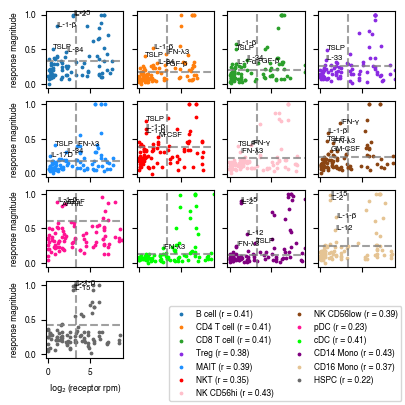

In [79]:
fig, axes = plt.subplots(nrows=4, ncols=4, figsize=cm_to_inches((10, 10)), constrained_layout=True)
axes = axes.flatten()

# Collect legend labels
legend_labels = []

outliers_rec_by_cell_type_low_high = []
outliers_rec_by_cell_type_high_low = []
outliers_rec_by_cell_type_high_high = []
primary_cell_types = []
for i, cell_type in enumerate(ALL_CELL_TYPES):
    ax = axes[i]
    df_subset = receptor_expression_by_cytokine_relative_flat[receptor_expression_by_cytokine_relative_flat["cell_type"] == cell_type]
    df_subset['raw_expression'] = np.log2(df_subset['raw_expression'])
    r = np.corrcoef(df_subset["raw_expression"],
                    df_subset["distance"])[0, 1]
    scatter = ax.scatter(df_subset["raw_expression"],
                         df_subset["distance"], s=3,
                         color=CELL_TYPE_COLORS[cell_type])
    
    df_subset_low_high = df_subset[(df_subset["raw_expression"] < 3.32) & (df_subset["distance"] > 1.5 * magnitude_threshold_by_cell_type[cell_type])]
    df_subset_high_low = df_subset[(df_subset["raw_expression"] > 5) & (df_subset["distance"] < 1 * magnitude_threshold_by_cell_type[cell_type])]
    df_subset_high_high = df_subset[(df_subset["raw_expression"] > 4) & (df_subset["distance"] > 1.5 * magnitude_threshold_by_cell_type[cell_type])]
    df_subset_primary = df_subset[(df_subset["raw_expression"] > 3.32) & (df_subset["distance"] > 1.0 * magnitude_threshold_by_cell_type[cell_type])]
    outliers_rec_by_cell_type_low_high.append(df_subset_low_high)
    outliers_rec_by_cell_type_high_low.append(df_subset_high_low)
    outliers_rec_by_cell_type_high_high.append(df_subset_high_high)
    primary_cell_types.append(df_subset_primary)
    
    # for plotting only
    df_subset_very_low = df_subset[(df_subset["raw_expression"] < 3.5) & (df_subset["distance"] > 1.3 * magnitude_threshold_by_cell_type[cell_type])]
    label = df_subset_very_low.sort_values(by="distance", ascending=False).head(5)["index"]
    # Add text labels for all cytokines in 'label'
    for idx, cytokine in enumerate(label):
        ax.annotate(
            introduce_greek_letters(cytokine),
            xy=(df_subset_very_low[df_subset_very_low["index"] == cytokine]["raw_expression"].values[0],
                df_subset_very_low[df_subset_very_low["index"] == cytokine]["distance"].values[0]),
            xytext=(0, 0),  # offset for annotation text position
            textcoords='offset points',
            fontsize=5.5,
            color='black'
        )
    
    
    
    # Collect the label for the legend
    legend_labels.append((scatter, f"{cell_type} (r = {r:.2f})"))
    ax.set_ylim(-0.05, 1.05)
    ax.set_xlim(-0.3, 9)
    
    ax.axhline(y=magnitude_threshold_by_cell_type[cell_type], linestyle='--', color='gray', alpha=0.75)
    ax.axvline(x=3.32, linestyle='--', color='gray', alpha=0.75)
    
    if i % 4 == 0:  # First column
        ax.set_ylabel("response magnitude")
    if i >= 12:  # Last row
        ax.set_xlabel(r"$\log_{2}$(receptor rpm)")
    ax.label_outer()  # Only show outer labels

outliers_rec_by_cell_type_low_high = pd.concat(outliers_rec_by_cell_type_low_high)
outliers_rec_by_cell_type_high_low = pd.concat(outliers_rec_by_cell_type_high_low)
outliers_rec_by_cell_type_high_high = pd.concat(outliers_rec_by_cell_type_high_high)
primary_cell_types = pd.concat(primary_cell_types)

# Remove any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Plot the legend once
handles, labels = zip(*legend_labels)
fig.legend(handles, labels, loc="lower right", fontsize=6, ncol=2)

for format in ["png", "svg"]:
    plt.savefig(os.path.join(plot_folder, f"3_scatter_receptor_vs_distance.{format}"), bbox_inches="tight", dpi=300)

In [80]:
primary_cell_types.rename(columns={
    "index": "cytokine",
    "distance": "response_magnitude",
    "raw_expression": "receptor_rpm",
    "relative_expression": "relative_receptor_expression"
    },
    inplace=True)
primary_cell_types['receptor_rpm'] = 2**primary_cell_types['receptor_rpm']

In [81]:
primary_cell_types = primary_cell_types[["cytokine", "cell_type", "receptor_rpm", "relative_receptor_expression", "response_magnitude"]]
primary_cell_types.to_excel(os.path.join(output_tables_folder, "primary_target_cell_types.xlsx"))

In [82]:
# fig, axes = plt.subplots(nrows=4, ncols=4, figsize=cm_to_inches((10, 10)), constrained_layout=True)
# axes = axes.flatten()

# # Collect legend labels
# legend_labels = []

# for i, cell_type in enumerate(ALL_CELL_TYPES):
#     ax = axes[i]
#     df_subset = receptor_expression_by_cytokine_relative_flat[receptor_expression_by_cytokine_relative_flat["cell_type"] == cell_type]
#     r = np.corrcoef(np.log10(df_subset["raw_expression"]),
#                     np.log10(df_subset["DEG_rel"]))[0, 1]
#     scatter = ax.scatter(np.log10(df_subset["raw_expression"]),
#                          np.log10(df_subset["DEG_rel"]), s=3,
#                          color=CELL_TYPE_COLORS[cell_type])
    
#     # Collect the label for the legend
#     legend_labels.append((scatter, f"{cell_type} (r = {r:.2f})"))
    
#     if i % 4 == 0:  # First column
#         ax.set_ylabel("log$_{10}$(rel. DEGs)")
#     if i >= 12:  # Last row
#         ax.set_xlabel(r"$\log_{10}$(receptor rpm)")
#     ax.label_outer()  # Only show outer labels

# # Remove any unused subplots
# for j in range(i + 1, len(axes)):
#     fig.delaxes(axes[j])

# # Plot the legend once
# handles, labels = zip(*legend_labels)
# fig.legend(handles, labels, loc="lower right", fontsize=6, ncol=2)

# for format in ["png", "svg"]:
#     plt.savefig(os.path.join(plot_folder, f"3_scatter_receptor_vs_DEGs.{format}"), bbox_inches="tight", dpi=300)

### Expression heatmaps

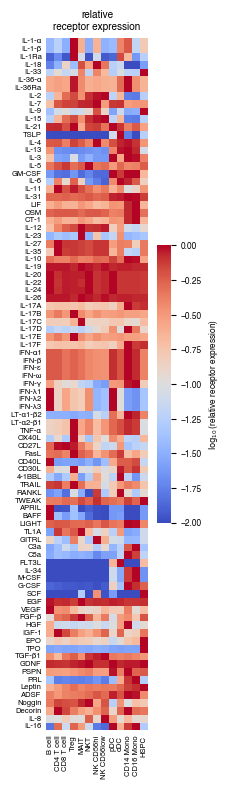

In [83]:
fig = plt.figure(figsize=cm_to_inches((6, 20)))
ax = sns.heatmap(np.log10(receptor_expression_by_cytokine_relative.clip(0.01, 1)), 
                cmap="coolwarm", 
                square=True, 
                cbar_kws={"shrink": 0.4, "label": r"$\log_{10}$(relative receptor expression)"})

# Explicitly set all y-ticks and labels
ax.set_yticks(np.arange(len(receptor_expression_by_cytokine_relative.index)) + 0.5)
ax.set_yticklabels([cytokine for cytokine in receptor_expression_by_cytokine_relative.index], fontsize=5.5)

# Apply Greek letter substitutions
apply_greek_labels_heatmap(ax)

# Adjust other plot parameters
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis='y', length=0)
ax.tick_params(axis='x', rotation=90, labelsize=5.5, length=0)
ax.set_title("relative\nreceptor expression")

plt.tight_layout()
for format in ["png", "svg"]:
    plt.savefig(os.path.join(plot_folder, f"3_receptor_expression_by_cytokine_relative_log.{format}"), 
                bbox_inches="tight", 
                dpi=300)

c:\Users\loesi\Dropbox\parse_pbmc data\HumanCytokineDict\code_lukas\unicode_utils.py:151: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

c:\Users\loesi\Dropbox\parse_pbmc data\HumanCytokineDict\code_lukas\unicode_utils.py:155: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

C:\Users\loesi\AppData\Local\Temp\ipykernel_37688\1849681759.py:13: UserWarning:

Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.



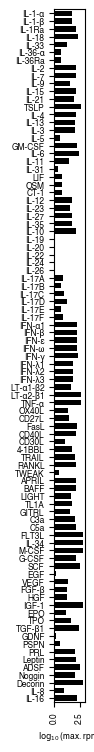

In [84]:
max_receptor_expression = receptor_expression_by_cytokine[ALL_CELL_TYPES_EXCLUDE].max(axis=1)

# make a horizontal bar plot
plt.figure(figsize=cm_to_inches((1, 22.85)))
max_receptor_expression = max_receptor_expression[::-1]
plt.barh(y=max_receptor_expression.index, width=np.log10(max_receptor_expression.values), color="black", height=0.7)
plt.ylim(-0.5, len(max_receptor_expression)-0.5)
# get the current figure and draw it (to get apply_greek_labels_heatmap to work)
fig = plt.gcf()
fig.canvas.draw()
apply_greek_labels_heatmap(plt.gca())
plt.xlabel(r"$\log_{10}$(max. rpm)", fontsize=6)
plt.tight_layout()
for format in ["png", "svg"]:
    plt.savefig(os.path.join(plot_folder, f"3_maximum_receptor_expression_by_cytokine.{format}"), bbox_inches="tight", dpi=300)

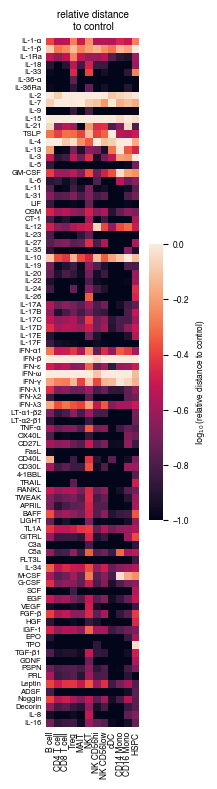

In [85]:
fig = plt.figure(figsize=cm_to_inches((6, 20)))
ax = sns.heatmap(np.log10(all_normalized_distances_mean_exclude_subset.clip(0.1)),
                cmap="rocket", 
                square=True, 
                cbar_kws={"shrink": 0.4, "label": r"$\log_{10}$(relative distance to control)"})   

# Explicitly set all y-ticks and labels
ax.set_yticks(np.arange(len(receptor_expression_by_cytokine_relative.index)) + 0.5)
ax.set_yticklabels([cytokine for cytokine in receptor_expression_by_cytokine_relative.index], fontsize=5.5)

# Apply Greek letter substitutions
apply_greek_labels_heatmap(ax)

# Adjust other plot parameters
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis='y', length=0)
ax.tick_params(axis='x', rotation=90, labelsize=6, length=0)
ax.set_title("relative distance\nto control")

plt.tight_layout()
for format in ["png", "svg"]:
    plt.savefig(os.path.join(plot_folder, f"3_distances_by_cytokine_relative.{format}"), 
                bbox_inches="tight", 
                dpi=300)

## 3.2 - Individual cell type and gene literature responses

In [86]:
plot_folder = os.path.join(base_plot_folder, "3.2_individual_literature_responses")
os.makedirs(plot_folder, exist_ok=True)

In [87]:
edger_df_padj_upregulated = edger_df_padj.copy()
edger_df_padj_downregulated = edger_df_padj.copy()

# Get boolean mask of negative fold changes
negative_fc_mask = edger_df_log2FoldChange < 0
positive_fc_mask = edger_df_log2FoldChange > 0

# Set padj values to 1 where fold change is negative
edger_df_padj_upregulated[negative_fc_mask] = 1
edger_df_padj_downregulated[positive_fc_mask] = 1

### Individual response lookup

In [88]:
# manually look up
strongest_response_in_literature = {}
upregulated_genes = pd.DataFrame(columns=["gene", "cell_type", "cytokine", "response_type"])

def evaluate_cytokine(current_cytokine, strongest_response_in_literature):
    data_long_cytokine = data_long[data_long["cytokine"] == current_cytokine].copy().set_index("cell_type")
    print("There should be strong response in the following cell types:")
    print(strongest_response_in_literature[current_cytokine])
    print("The relative DEGs and Magnitudes are:")
    print(data_long_cytokine[["DEG_rel", "Distance"]])

def print_regulated_genes(upregulated_genes, current_cytokine):
    # Get genes for this cytokine
    cytokine_genes = upregulated_genes[upregulated_genes["cytokine"] == current_cytokine]
    
    # Group by cell type
    for cell_type, cell_genes in cytokine_genes.groupby("cell_type"):
        print(f"{cell_type}")
        print("--------------------------------")
        
        for _, row in cell_genes.iterrows():
            gene = row["gene"]
            if gene in edger_df_log2FoldChange.index:
                fc = edger_df_log2FoldChange.loc[gene, (cell_type, current_cytokine)]
                pval = edger_df_padj.loc[gene, (cell_type, current_cytokine)]
                
                print(f"The fold change for {gene} in response to {current_cytokine} is {fc}")
                print(f"The p-value for {gene} in response to {current_cytokine} is {pval:e}" \
                    if not pd.isna(pval) else f"The p-value for {gene} in response to {current_cytokine} is NaN")
                print("----")
            else:
                if gene in unfiltered_genes:
                    print(f"The gene {gene} is not in padj, but is in the list of unfiltered genes.")
                else:
                    print(f"The gene {gene} is not in padj, and is not in the list of unfiltered genes.")

#### We're interested in these (fairly randomly chosen) cytokines: IL-3, IL-32-beta, GM-CSF, TPO, IL-7, CD40L, IL-4, IL-12

In [89]:
# --------------------------------------------------
# IL-3: 10.3389/fimmu.2024.1411047
current_cytokine = "IL-3"
print(f"Processing {current_cytokine}")
print("""CD123 (IL3RA) is mainly expressed on hematopoietic cells, including hematopoietic stem and progenitor cells (HSPCs),
basophils, eosinophils, mast cells, non-classical monocytes, macrophages, human plasmacytoid dendritic cells (pDCs)
and activated T and B cells (...) In steady-state, murine monocytes and human classical
monocytes do not express the receptor for IL-3. Only human intermediate and non-classical monocytes express it.""")

strongest_response_in_literature[current_cytokine] = ["HSPC", "CD16 Mono"]
evaluate_cytokine(current_cytokine, strongest_response_in_literature)

print("The expression in CD14 Monos is curiously high.")

"""IL-3 stimulates the growth and
differentiation of HSPCs from bone marrow cultures and in naive or
sublethally irradiated mice into a large range of cell lineages,
including basophils, neutrophils, eosinophils, macrophages"""

"""IL-3 synergizes with IL-4 to enhance CCL17 expression in CD14+ monocytes """
upregulated_genes = pd.concat([upregulated_genes, pd.DataFrame([
    {'gene': 'CCL3', 'cytokine': current_cytokine, 'cell_type': 'CD14 Mono', 'response_type': 'chemotaxis'}, 
    {'gene': 'CCL7', 'cytokine': current_cytokine, 'cell_type': 'CD14 Mono', 'response_type': 'chemotaxis'},
    {'gene': 'CCL17', 'cytokine': current_cytokine, 'cell_type': 'CD14 Mono', 'response_type': 'chemotaxis'}
])])

print("upregulated genes")
print_regulated_genes(upregulated_genes, current_cytokine)

Processing IL-3
CD123 (IL3RA) is mainly expressed on hematopoietic cells, including hematopoietic stem and progenitor cells (HSPCs),
basophils, eosinophils, mast cells, non-classical monocytes, macrophages, human plasmacytoid dendritic cells (pDCs)
and activated T and B cells (...) In steady-state, murine monocytes and human classical
monocytes do not express the receptor for IL-3. Only human intermediate and non-classical monocytes express it.
There should be strong response in the following cell types:
['HSPC', 'CD16 Mono']
The relative DEGs and Magnitudes are:
             DEG_rel  Distance
cell_type                     
B cell      0.162318  0.308999
CD4 T cell  0.111531  0.131049
CD8 T cell  0.099613  0.148230
Treg        0.050000  0.304110
MAIT        0.050000  0.190070
NKT         0.081823  0.364496
NK CD56hi   0.050000  0.114827
NK CD56low  0.086220  0.201113
pDC         0.460177  0.496071
cDC         0.149834  0.294898
CD14 Mono   0.464751  0.639977
HSPC        1.000000  1.000

In [90]:
# --------------------------------------------------
# IL-32-beta: 10.1002/JLB.3MR0620-550R
current_cytokine = "IL-32-beta"
print(f"Processing {current_cytokine}")

strongest_response_in_literature[current_cytokine] = ["NK CD56low", "NK CD56hi", "CD14 Mono", "CD16 Mono", "cDC"]
evaluate_cytokine(current_cytokine, strongest_response_in_literature)

# pick some upregulated cytokines
upregulated_genes = pd.concat([upregulated_genes, pd.DataFrame([
    {'gene': 'IL1B', 'cytokine': current_cytokine, 'cell_type': 'CD14 Mono', 'response_type': 'inflammatory'},
    {'gene': 'IL6', 'cytokine': current_cytokine, 'cell_type': 'CD14 Mono', 'response_type': 'inflammatory'}
])])

print_regulated_genes(upregulated_genes, current_cytokine)

Processing IL-32-beta
There should be strong response in the following cell types:
['NK CD56low', 'NK CD56hi', 'CD14 Mono', 'CD16 Mono', 'cDC']
The relative DEGs and Magnitudes are:
             DEG_rel  Distance
cell_type                     
HSPC        0.794118  1.000000
NK CD56hi   0.224271  1.000000
B cell      0.386310  0.746955
CD4 T cell  0.352019  0.496472
CD8 T cell  0.340066  0.627264
MAIT        0.303998  0.846297
NKT         0.516072  0.945473
Treg        0.484043  0.847224
NK CD56low  0.420986  1.000000
pDC         0.050000  0.500000
cDC         0.689503  1.000000
CD14 Mono   0.971598  1.000000
CD16 Mono   0.542827  1.000000
CD14 Mono
--------------------------------
The fold change for IL1B in response to IL-32-beta is 5.5461711868171735
The p-value for IL1B in response to IL-32-beta is 6.154854e-07
----
The fold change for IL6 in response to IL-32-beta is 4.35675315279993
The p-value for IL6 in response to IL-32-beta is 1.285834e-04
----


In [91]:
# --------------------------------------------------
# M/GM-CSF: 10.1016_j.immuni.2016.10.026
current_cytokine = "GM-CSF"
print(f"Processing {current_cytokine}")

strongest_response_in_literature[current_cytokine] = ["CD14 Mono", "CD16 Mono", "cDC"]
evaluate_cytokine(current_cytokine, strongest_response_in_literature)

# Croxford (2015) - Immunity - The Cytokine GM-CSF (pick a subset of genes for plotting)
upregulated_genes = pd.concat([upregulated_genes, pd.DataFrame([
    {'gene': 'PYCARD', 'cytokine': current_cytokine, 'cell_type': 'CD14 Mono', 'response_type': 'phagocytosis'},
    #{'gene': 'MFGE8', 'cytokine': current_cytokine, 'cell_type': 'CD14 Mono', 'response_type': 'phagocytosis'},
    #{'gene': 'CD1D', 'cytokine': current_cytokine, 'cell_type': 'CD14 Mono', 'response_type': 'phagocytosis'},
    #{'gene': 'PLD1', 'cytokine': current_cytokine, 'cell_type': 'CD14 Mono', 'response_type': 'phagocytosis'},
    #{'gene': 'SCARB1', 'cytokine': current_cytokine, 'cell_type': 'CD14 Mono', 'response_type': 'phagocytosis'},
    {'gene': 'CLEC7A', 'cytokine': current_cytokine, 'cell_type': 'CD14 Mono', 'response_type': 'phagocytosis'},
    #{'gene': 'ANXA1', 'cytokine': current_cytokine, 'cell_type': 'CD14 Mono', 'response_type': 'phagocytosis'},
    {'gene': 'CCL17', 'cytokine': current_cytokine, 'cell_type': 'CD14 Mono', 'response_type': 'chemotaxis'},
    {'gene': 'CCL24', 'cytokine': current_cytokine, 'cell_type': 'CD14 Mono', 'response_type': 'chemotaxis'},
    #{'gene': 'CXCL3', 'cytokine': current_cytokine, 'cell_type': 'CD14 Mono', 'response_type': 'chemotaxis'}
])])
print_regulated_genes(upregulated_genes, current_cytokine)

Processing GM-CSF
There should be strong response in the following cell types:
['CD14 Mono', 'CD16 Mono', 'cDC']
The relative DEGs and Magnitudes are:
             DEG_rel  Distance
cell_type                     
NK CD56hi   0.050000  0.192169
CD4 T cell  0.208830  0.252852
CD8 T cell  0.162424  0.245613
Treg        0.146518  0.302195
MAIT        0.066724  0.209890
NKT         0.109293  0.422013
B cell      0.221281  0.389467
NK CD56low  0.179267  0.332614
CD16 Mono   0.504467  0.654710
HSPC        0.050000  0.597380
pDC         0.194690  0.319164
CD14 Mono   0.581572  0.912943
cDC         0.285304  0.426747
CD14 Mono
--------------------------------
The fold change for PYCARD in response to GM-CSF is -0.085763952337896
The p-value for PYCARD in response to GM-CSF is 1.000000e+00
----
The fold change for CLEC7A in response to GM-CSF is 0.3113568739017487
The p-value for CLEC7A in response to GM-CSF is 5.927074e-04
----
The fold change for CCL17 in response to GM-CSF is 8.67455969005576

In [92]:
# --------------------------------------------------
# TPO: 10.1080/09537104.2021.1925102
current_cytokine = "TPO"
print(f"Processing {current_cytokine}")

strongest_response_in_literature[current_cytokine] = ["HSPC"] 
evaluate_cytokine(current_cytokine, strongest_response_in_literature)

# de Graaf (2011) - Cell cycle - Thrombopoietin and hematopoietic stem cells
# these genes aren't really mentioned directly, so don't plot this
upregulated_genes = pd.concat([upregulated_genes, pd.DataFrame([
    {'gene': 'CDKN1C', 'cytokine': current_cytokine, 'cell_type': 'HSPC', 'response_type': 'quiescence'},
    {'gene': 'CDKN2D', 'cytokine': current_cytokine, 'cell_type': 'HSPC', 'response_type': 'quiescence'},
    {'gene': 'HOXB4', 'cytokine': current_cytokine, 'cell_type': 'HSPC', 'response_type': 'stemness'},
    {'gene': 'HOXA5', 'cytokine': current_cytokine, 'cell_type': 'HSPC', 'response_type': 'stemness'},
    {'gene': 'HOXA9', 'cytokine': current_cytokine, 'cell_type': 'HSPC', 'response_type': 'stemness'},
    {'gene': 'HOXA10', 'cytokine': current_cytokine, 'cell_type': 'HSPC', 'response_type': 'stemness'},
    {'gene': 'BCL2L1', 'cytokine': current_cytokine, 'cell_type': 'HSPC', 'response_type': 'survival'}
])])

print_regulated_genes(upregulated_genes, current_cytokine)

Processing TPO
There should be strong response in the following cell types:
['HSPC']
The relative DEGs and Magnitudes are:
             DEG_rel  Distance
cell_type                     
NK CD56hi   0.050000  0.131284
B cell      0.050000  0.104861
CD4 T cell  0.050000  0.049323
CD8 T cell  0.050000  0.051859
Treg        0.050000  0.075502
MAIT        0.050000  0.054734
NKT         0.050000  0.099644
CD14 Mono   0.050000  0.033013
NK CD56low  0.050000  0.076540
cDC         0.050000  0.056296
pDC         0.050000  0.404941
CD16 Mono   0.050000  0.043057
HSPC        0.161765  0.919558
HSPC
--------------------------------
The fold change for CDKN1C in response to TPO is nan
The p-value for CDKN1C in response to TPO is 1.000000e+00
----
The fold change for CDKN2D in response to TPO is nan
The p-value for CDKN2D in response to TPO is 1.000000e+00
----
The fold change for HOXB4 in response to TPO is -0.4367284095448122
The p-value for HOXB4 in response to TPO is 1.000000e+00
----
The fold cha

In [93]:
# --------------------------------------------------
# IL-7: 10.3389/fimmu.2021.747324
current_cytokine = "IL-7"
print(f"Processing {current_cytokine}")

strongest_response_in_literature[current_cytokine] = ["CD4 T cell", "CD8 T cell", "MAIT", "NKT", "Treg"]
evaluate_cytokine(current_cytokine, strongest_response_in_literature)

# IL-7: 10.3389/fimmu.2021.747324
# Don't add CD14 Monos here to avoid clutter
upregulated_genes = pd.concat([upregulated_genes, pd.DataFrame([
    {'gene': 'BCL2', 'cytokine': current_cytokine, 'cell_type': 'NK CD56hi', 'response_type': 'survival'},
    {'gene': 'PIM1', 'cytokine': current_cytokine, 'cell_type': 'NK CD56hi', 'response_type': 'survival'},
    {'gene': 'BCL2', 'cytokine': current_cytokine, 'cell_type': 'CD4 T cell', 'response_type': 'survival'},
    {'gene': 'PIM1', 'cytokine': current_cytokine, 'cell_type': 'CD4 T cell', 'response_type': 'survival'},
    {'gene': 'IFNG', 'cytokine': current_cytokine, 'cell_type': 'NK CD56hi', 'response_type': 'cytokine'},
    # {'gene': 'FASLG', 'cytokine': current_cytokine, 'cell_type': 'NK CD56hi', 'response_type': 'cytokine'},
    # {'gene': 'CD40', 'cytokine': current_cytokine, 'cell_type': 'CD14 Mono', 'response_type': 'activation'},
    # {'gene': 'CD80', 'cytokine': current_cytokine, 'cell_type': 'CD14 Mono', 'response_type': 'activation'},
    # {'gene': 'HLA-DRA', 'cytokine': current_cytokine, 'cell_type': 'CD14 Mono', 'response_type': 'activation'}
])])
print("upregulated genes")
print_regulated_genes(upregulated_genes, current_cytokine)

Processing IL-7
There should be strong response in the following cell types:
['CD4 T cell', 'CD8 T cell', 'MAIT', 'NKT', 'Treg']
The relative DEGs and Magnitudes are:
             DEG_rel  Distance
cell_type                     
NK CD56hi   0.241540  0.778544
CD4 T cell  1.000000  1.000000
CD8 T cell  0.870780  1.000000
Treg        0.681335  0.987997
MAIT        1.000000  1.000000
NKT         0.304500  0.820775
B cell      0.581159  0.838815
NK CD56low  0.369406  0.618200
cDC         0.844862  0.984084
CD14 Mono   0.518850  0.699901
CD16 Mono   0.636364  0.764004
HSPC        0.343137  0.682780
pDC         0.628319  0.527992
upregulated genes
CD4 T cell
--------------------------------
The fold change for BCL2 in response to IL-7 is 2.2031579938085555
The p-value for BCL2 in response to IL-7 is 2.691188e-07
----
The fold change for PIM1 in response to IL-7 is 1.495475616827198
The p-value for PIM1 in response to IL-7 is 1.123080e-05
----
NK CD56hi
--------------------------------
The fo

In [94]:
# --------------------------------------------------
# CD40L: 10.1111/j.1600-065X.2009.00782.x
current_cytokine = "CD40L"
print(f"Processing {current_cytokine}")

strongest_response_in_literature[current_cytokine] = ["B cell", "cDC", "CD14 Mono", "CD16 Mono"]
evaluate_cytokine(current_cytokine, strongest_response_in_literature)

# all of these work, but I'll pick two to actually plot
upregulated_genes = pd.concat([upregulated_genes, pd.DataFrame([
    {'gene': 'NFKB2', 'cytokine': current_cytokine, 'cell_type': 'B cell', 'response_type': 'NF-kappaB'},
    #{'gene': 'IKBKE', 'cytokine': current_cytokine, 'cell_type': 'B cell', 'response_type': 'NF-kappaB'},
    {'gene': 'TRAF1', 'cytokine': current_cytokine, 'cell_type': 'B cell', 'response_type': 'NF-kappaB'},
    #{'gene': 'UBE2K', 'cytokine': current_cytokine, 'cell_type': 'B cell', 'response_type': 'NF-kappaB'}
])])
print("upregulated genes")
print_regulated_genes(upregulated_genes, current_cytokine)

Processing CD40L
There should be strong response in the following cell types:
['B cell', 'cDC', 'CD14 Mono', 'CD16 Mono']
The relative DEGs and Magnitudes are:
             DEG_rel  Distance
cell_type                     
NK CD56low  0.050000  0.099166
CD4 T cell  0.050000  0.051055
Treg        0.050000  0.144941
MAIT        0.050000  0.092158
NKT         0.050000  0.374504
NK CD56hi   0.050000  0.126491
B cell      0.393426  0.702340
pDC         0.050000  0.534571
HSPC        0.050000  0.206884
cDC         0.073812  0.174125
CD8 T cell  0.050000  0.056338
CD16 Mono   0.050000  0.112099
CD14 Mono   0.060693  0.061925
upregulated genes
B cell
--------------------------------
The fold change for NFKB2 in response to CD40L is 1.027861686118018
The p-value for NFKB2 in response to CD40L is 1.267112e-07
----
The fold change for TRAF1 in response to CD40L is 1.4842289812598466
The p-value for TRAF1 in response to CD40L is 1.285956e-08
----


In [95]:
# --------------------------------------------------
# IL-4: 10.12703/r/10-71
current_cytokine = "IL-4"
print(f"Processing {current_cytokine}")

strongest_response_in_literature[current_cytokine] = ["B cell", "CD4 T cell", "CD8 T cell", "MAIT", "NKT", "Treg", "NK CD56low", "NK CD56hi"]
evaluate_cytokine(current_cytokine, strongest_response_in_literature)

# only plot B cell responses for this one
upregulated_genes = pd.concat([upregulated_genes, pd.DataFrame([
    {'gene': 'FCER2', 'cytokine': current_cytokine, 'cell_type': 'B cell', 'response_type': 'isotype'}, # isotype switch, IgE receptor
    #{'gene': 'IGHG4', 'cytokine': current_cytokine, 'cell_type': 'B cell', 'response_type': 'isotype'},# isotype switch, IgG4 
    {'gene': 'IGHE', 'cytokine': current_cytokine, 'cell_type': 'B cell', 'response_type': 'isotype'}, # isotype switch, IgG3
    #{'gene': 'BCL2', 'cytokine': current_cytokine, 'cell_type': 'B cell', 'response_type': 'other'}, # prevents apoptosis
    {'gene': 'IL4I1', 'cytokine': current_cytokine, 'cell_type': 'B cell', 'response_type': 'other'}, ## of recent interest
    {'gene': 'IL4R', 'cytokine': current_cytokine, 'cell_type': 'B cell', 'response_type': 'other'}, ## induce its own receptor
    # {'gene': 'IL4R', 'cytokine': current_cytokine, 'cell_type': 'CD4 T cell', 'response_type': 'other'}, ## induce its own receptor
    # {'gene': 'GATA3', 'cytokine': current_cytokine, 'cell_type': 'CD4 T cell', 'response_type': 'differentiation'},
    # {'gene': 'IL13', 'cytokine': current_cytokine, 'cell_type': 'CD4 T cell', 'response_type': 'cytokine production'},
    # {'gene': 'IL5', 'cytokine': current_cytokine, 'cell_type': 'CD4 T cell', 'response_type': 'cytokine production'},
    # {'gene': 'IL1RL1', 'cytokine': current_cytokine, 'cell_type': 'CD4 T cell', 'response_type': 'activation'},
    # {'gene': 'CD28', 'cytokine': current_cytokine, 'cell_type': 'CD4 T cell', 'response_type': 'activation'},
    # {'gene': 'IL12RB2', 'cytokine': current_cytokine, 'cell_type': 'CD4 T cell', 'response_type': 'receptor expression'},
    # {'gene': 'CD14', 'cytokine': current_cytokine, 'cell_type': 'CD14 Mono', 'response_type': 'activation'},
    # {'gene': 'IL1B', 'cytokine': current_cytokine, 'cell_type': 'CD14 Mono', 'response_type': 'cytokine production'},  #https://doi.org/10.1182/blood.V76.7.1392.1392
    # {'gene': 'TNF', 'cytokine': current_cytokine, 'cell_type': 'CD14 Mono', 'response_type': 'cytokine production'},  #https://doi.org/10.1182/blood.V76.7.1392.1392
    # {'gene': 'IL6', 'cytokine': current_cytokine, 'cell_type': 'CD14 Mono', 'response_type': 'cytokine production'}  #https://doi.org/10.1182/blood.V76.7.1392.1392
])])
print("upregulated genes")
print_regulated_genes(upregulated_genes, current_cytokine)

Processing IL-4
There should be strong response in the following cell types:
['B cell', 'CD4 T cell', 'CD8 T cell', 'MAIT', 'NKT', 'Treg', 'NK CD56low', 'NK CD56hi']
The relative DEGs and Magnitudes are:
             DEG_rel  Distance
cell_type                     
NK CD56hi   0.319253  1.000000
CD4 T cell  0.546035  1.000000
CD8 T cell  0.362756  0.802480
Treg        0.465184  0.923408
MAIT        0.217141  0.586926
NKT         0.170076  0.453238
B cell      0.839038  1.000000
NK CD56low  0.304425  0.766633
cDC         0.515138  0.820988
CD14 Mono   0.809467  1.000000
CD16 Mono   0.698371  0.991161
HSPC        0.171569  0.682627
pDC         0.584071  0.952439
upregulated genes
B cell
--------------------------------
The fold change for FCER2 in response to IL-4 is 5.74765453749204
The p-value for FCER2 in response to IL-4 is 4.116352e-11
----
The fold change for IGHE in response to IL-4 is 4.082329451430545
The p-value for IGHE in response to IL-4 is 1.933198e-08
----
The fold change 

In [96]:
# --------------------------------------------------
# IL-12: 10.17179/excli2020-3104
current_cytokine = "IL-12"
print(f"Processing {current_cytokine}")

strongest_response_in_literature[current_cytokine] = ["NK CD56low", "NK CD56hi", "CD4 T cell", "CD8 T cell", "MAIT", "NKT", "Treg"]
evaluate_cytokine(current_cytokine, strongest_response_in_literature)

upregulated_genes = pd.concat([upregulated_genes, pd.DataFrame([
    {'gene': 'IFNG', 'cytokine': current_cytokine, 'cell_type': 'NK CD56hi', 'response_type': 'cytokine'},
    {'gene': 'TNF', 'cytokine': current_cytokine, 'cell_type': 'NK CD56hi', 'response_type': 'cytokine'},
    {'gene': 'IFNG', 'cytokine': current_cytokine, 'cell_type': 'CD4 T cell', 'response_type': 'cytokine production'},
    #{'gene': 'TBX21', 'cytokine': current_cytokine, 'cell_type': 'CD4 T cell', 'response_type': 'cytokine production'}, 
    # {'gene': 'IFNG', 'cytokine': current_cytokine, 'cell_type': 'CD8 T cell', 'response_type': 'cytokine production'},
    {'gene': 'GZMB', 'cytokine': current_cytokine, 'cell_type': 'NK CD56hi', 'response_type': 'cytotoxicity'},
    #{'gene': 'FASLG', 'cytokine': current_cytokine, 'cell_type': 'NK CD56hi', 'response_type': 'cytotoxicity'},
    {'gene': 'PRF1', 'cytokine': current_cytokine, 'cell_type': 'NK CD56hi', 'response_type': 'cytotoxicity'}
])])
print("upregulated genes")
print_regulated_genes(upregulated_genes, current_cytokine)

Processing IL-12
There should be strong response in the following cell types:
['NK CD56low', 'NK CD56hi', 'CD4 T cell', 'CD8 T cell', 'MAIT', 'NKT', 'Treg']
The relative DEGs and Magnitudes are:
             DEG_rel  Distance
cell_type                     
NK CD56hi   0.278413  0.868588
B cell      0.199932  0.323064
CD4 T cell  0.172234  0.225531
CD8 T cell  0.133924  0.203550
Treg        0.168279  0.276556
MAIT        0.129422  0.307648
NKT         0.050000  0.324213
HSPC        0.050000  0.315106
NK CD56low  0.228066  0.407469
pDC         0.194690  0.310092
cDC         0.150276  0.229473
CD14 Mono   0.339138  0.415526
CD16 Mono   0.453757  0.482841
upregulated genes
CD4 T cell
--------------------------------
The fold change for IFNG in response to IL-12 is nan
The p-value for IFNG in response to IL-12 is 1.000000e+00
----
NK CD56hi
--------------------------------
The fold change for IFNG in response to IL-12 is 3.460992073644634
The p-value for IFNG in response to IL-12 is 3.05366

### Check if expected global impact conforms to expectations

In [97]:
count_significant_responses = 0
expected_responses = pd.DataFrame(index=strongest_response_in_literature.keys(), columns=ALL_CELL_TYPES_EXCLUDE, data=0)
for cytokine in strongest_response_in_literature.keys():
    for cell_type in strongest_response_in_literature[cytokine]:
        if cell_type in ALL_CELL_TYPES_EXCLUDE:
            expected_responses.loc[cytokine, cell_type] = 1
            if strong_impact_by_cell_type.loc[cytokine, cell_type]:
                count_significant_responses += 1
        else:
            print(f"The cell type {cell_type} is not in the list of all cell types.")

In [98]:
no_significant_responses_subset = strong_impact_by_cell_type.loc[expected_responses.index, expected_responses.columns][ALL_CELL_TYPES_EXCLUDE]
count_significant_responses / expected_responses.sum().sum()

0.9142857142857143

In [99]:
all_relative_distances_mean_subset = all_relative_distances_mean.loc[expected_responses.index, expected_responses.columns][ALL_CELL_TYPES_EXCLUDE]
relative_degs_subset = data_long.pivot(index="cytokine", columns="cell_type", values="DEG_rel").loc[expected_responses.index, expected_responses.columns][ALL_CELL_TYPES_EXCLUDE]
relative_degs_subset = relative_degs_subset.div(relative_degs_subset.max(axis=1), axis=0)

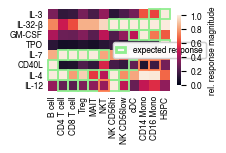

In [100]:
plt.figure(figsize=cm_to_inches((5,3.8)))
ax = sns.heatmap(all_relative_distances_mean_subset, vmin=0.0, vmax=1.0, cmap="rocket",
            cbar_kws={"ticks": [0.0, 0.2, 0.4, 0.6, 0.8, 1.0], "label": "rel. response magnitude", "shrink": 0.6}, square=True)
# add a green box around the expected responses
for cytokine_index, cytokine in enumerate(expected_responses.index):
    for cell_type_index, cell_type in enumerate(expected_responses.columns):
        if expected_responses.loc[cytokine, cell_type] == 1:
            if strong_impact_by_cell_type.loc[cytokine, cell_type]:
                rect = plt.Rectangle((expected_responses.columns.get_loc(cell_type),
                                expected_responses.index.get_loc(cytokine)),
                                1, 1, fill=False, edgecolor="lightgreen", linewidth=1.3, clip_on=False, zorder=2)
            else:
                rect = plt.Rectangle((expected_responses.columns.get_loc(cell_type),
                                expected_responses.index.get_loc(cytokine)),
                                1, 1, fill=False, edgecolor="coral", linewidth=1.3, clip_on=False, zorder=3)
            plt.gca().add_patch(rect)
            
# Add legend for green box
# Create custom legend patch for green box
green_box = plt.Rectangle((0,0), 1, 1, fill=False, edgecolor="lightgreen", linewidth=2)
plt.gca().add_artist(plt.legend([green_box], ['expected response'], loc='center left', bbox_to_anchor=(0.5, 0.5), handlelength=1, handletextpad=1))

apply_greek_labels_heatmap(ax)
plt.gca().tick_params(length=0)

for format in ["png", "svg"]:
    plt.savefig(os.path.join(plot_folder, f"3_expected_strength_responses_literature.{format}"), bbox_inches="tight", dpi=300)

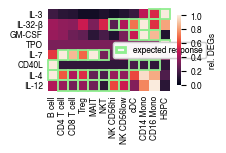

In [101]:
plt.figure(figsize=cm_to_inches((5,3.8)))
ax = sns.heatmap(relative_degs_subset, vmin=0.0, vmax=1.0, cmap="rocket",
            cbar_kws={"ticks": [0.0, 0.2, 0.4, 0.6, 0.8, 1.0], "label": "rel. DEGs", "shrink": 0.6}, square=True)
# add a green box around the expected responses
for cytokine_index, cytokine in enumerate(expected_responses.index):
    for cell_type_index, cell_type in enumerate(expected_responses.columns):
        if expected_responses.loc[cytokine, cell_type] == 1:
            rect = plt.Rectangle((expected_responses.columns.get_loc(cell_type),
                                expected_responses.index.get_loc(cytokine)),
                                1, 1, fill=False, edgecolor="lightgreen", linewidth=1.3, clip_on=False)
            plt.gca().add_patch(rect)
# Add legend for green box
# Create custom legend patch for green box
green_box = plt.Rectangle((0,0), 1, 1, fill=False, edgecolor="lightgreen", linewidth=2)
plt.gca().add_artist(plt.legend([green_box], ['expected response'], loc='center left', bbox_to_anchor=(0.5, 0.5), handlelength=1, handletextpad=1))

apply_greek_labels_heatmap(ax)
plt.gca().tick_params(length=0)

for format in ["png", "svg"]:
    plt.savefig(os.path.join(plot_folder, f"3_expected_DEG_responses_literature.{format}"), bbox_inches="tight", dpi=300)

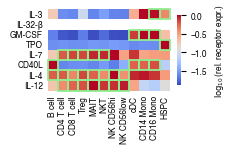

In [102]:
plt.figure(figsize=cm_to_inches((5,3.8)))
receptor_expression_by_cytokine_relative_plot = receptor_expression_by_cytokine_relative.copy()
receptor_expression_by_cytokine_relative_plot.loc["IL-32-beta"] = np.nan
ax = sns.heatmap(np.log10(receptor_expression_by_cytokine_relative_plot.loc[expected_responses.index, expected_responses.columns].clip(0.01)), 
                cmap="coolwarm", 
                square=True, 
                cbar_kws={"shrink": 0.6, "label": r"$\log_{10}$(rel. receptor expr.)"})

# add a green box around the expected responses
for cytokine_index, cytokine in enumerate(expected_responses.index):
    if cytokine == "IL-32-beta":
        continue
    for cell_type_index, cell_type in enumerate(expected_responses.columns):
        if expected_responses.loc[cytokine, cell_type] == 1:
            if receptor_expression_by_cytokine_relative_plot.loc[cytokine, cell_type] > -1:
                rect = plt.Rectangle((expected_responses.columns.get_loc(cell_type),
                                    expected_responses.index.get_loc(cytokine)),
                                    1, 1, fill=False, edgecolor="lightgreen", linewidth=1.3, clip_on=False)
                plt.gca().add_patch(rect)
            else:
                rect = plt.Rectangle((expected_responses.columns.get_loc(cell_type),
                                    expected_responses.index.get_loc(cytokine)),
                                    1, 1, fill=False, edgecolor="coral", linewidth=1.3, clip_on=False)
                plt.gca().add_patch(rect)

apply_greek_labels_heatmap(ax)
plt.gca().tick_params(length=0)

for format in ["png", "svg"]:
    plt.savefig(os.path.join(plot_folder, f"3_receptor_expression_subset.{format}"), 
                bbox_inches="tight", 
                dpi=300)

### Individual gene upregulation

In [103]:
upregulated_genes = upregulated_genes.reset_index(drop=True)
for index, row in upregulated_genes.iterrows():
    if row["gene"] in edger_df_log2FoldChange.index:
        fc = edger_df_log2FoldChange.loc[row["gene"], (row["cell_type"], row["cytokine"])]
        pval = edger_df_padj_orig.loc[row["gene"], (row["cell_type"], row["cytokine"])]
        upregulated_genes.loc[index, "fc"] = fc
        upregulated_genes.loc[index, "pval"] = pval
upregulated_genes.dropna(inplace=True)
upregulated_genes["cyto_response"] = upregulated_genes["cytokine"] + "\n" + upregulated_genes["response_type"]

c:\Users\loesi\Dropbox\parse_pbmc data\HumanCytokineDict\code_lukas\unicode_utils.py:151: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

c:\Users\loesi\Dropbox\parse_pbmc data\HumanCytokineDict\code_lukas\unicode_utils.py:155: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

c:\Users\loesi\Dropbox\parse_pbmc data\HumanCytokineDict\code_lukas\unicode_utils.py:151: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

c:\Users\loesi\Dropbox\parse_pbmc data\HumanCytokineDict\code_lukas\unicode_utils.py:155: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

c:\Users\loesi\Dropbox\parse_pbmc data\HumanCytokineDict\code_lukas\unicode_utils.py:151: UserWarning:

set_ticklabels()

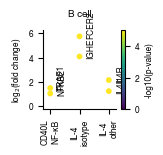

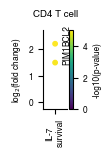

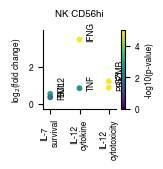

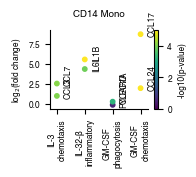

In [104]:
cell_types = ["B cell", "CD4 T cell", "NK CD56hi", "CD14 Mono"]
for cell_type in cell_types:
    df_subset = upregulated_genes[upregulated_genes["cell_type"] == cell_type]

    # Fixed dimensions for the plot area (in cm)
    plot_width = len(df_subset['cyto_response'].unique())  # Width of plot area
    plot_height = 2  # Height of plot area
    margin_bottom = 2  # Extra space for x-labels
    margin_top = 0.5  # Extra space for title
    total_width = plot_width
    total_height = plot_height + margin_bottom + margin_top

    plt.figure(figsize=cm_to_inches((total_width, total_height)))

    # Create subplot with specific spacing to maintain fixed plot area
    plt.subplots_adjust(bottom=margin_bottom/total_height, 
                    top=1-margin_top/total_height)

    # Create colormap based on -log10(pvalue)
    log_pvals = -np.log10(df_subset['pval'].clip(1E-5))
    norm = plt.Normalize(0, log_pvals.max())
    cmap = plt.cm.viridis

    plt.scatter(df_subset['cyto_response'], df_subset['fc'], 
            c=log_pvals, cmap=cmap, norm=norm,
            alpha=1, s=10)

    # Add colorbar
    cbar = plt.colorbar()
    cbar.set_label('-log10(p-value)')

    # Add gene labels next to points
    for _, row in df_subset.iterrows():
        plt.annotate(row['gene'], 
                    (row['cyto_response'], row['fc']),
                    xytext=(5, 0), 
                    textcoords='offset points',
                    rotation=90,
                    fontsize=6)

    plt.xticks(rotation=90, va='top', ha='center')
    plt.ylabel(r'log$_2$(fold change)')
    plt.title(cell_type, fontsize=7, pad=10)
    plt.xlim(-0.25, len(df_subset['cyto_response'].unique()) - 0.75)
    plt.ylim(min(min(df_subset['fc']) - 0.5, -0.25), max(df_subset['fc']) + 0.5)

    apply_greek_labels_heatmap(plt.gca())

    # Remove top and right spines
    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)

    for format in ["png", "svg"]:
        plt.savefig(os.path.join(plot_folder, f"3_individual_upregulated_genes_by_cytokine_{cell_type}.{format}"), bbox_inches="tight", dpi=300)

# 4 - Average cytokine production response across cell types

Here, we
1) Get the average and max over all cytokines.
2) Filter to genes where the maximum average expression is at least 4 and the maximum maximum expression at least 20
    (This filters to cytokine genes that are expressed under at least one condition)
3) Filter the *mean* average expression to these columns.
4) Calculate the relative rpm across cell types

The resultant gene filter (expressed_genes_by_cell_type_dict) is later used to calculate correlation values between expression patterns.

In [105]:
plot_folder = os.path.join(base_plot_folder, "4_average_cytokine_production_by_cell_type")
os.makedirs(plot_folder, exist_ok=True)

In [106]:
# 1) Get the average and max over all cytokine stimulation conditions
sum_over_all_cytokines_mean = average_norm_sum_gene_count_df.T.groupby(level='cell_type').mean().T
sum_over_all_cytokines_max = average_norm_sum_gene_count_df.T.groupby(level='cell_type').max().T
substantial_detection = average_sum_gene_count_df.T.groupby(level=0).max().T # these are total counts

# 2) Calculate the per-gene filter for later use
expressed_genes_by_cell_type_df = (sum_over_all_cytokines_mean > 4) & (sum_over_all_cytokines_max > 20) & (substantial_detection > 20)
expressed_genes_by_cell_type_dict = {cell_type: list(expressed_genes_by_cell_type_df[cell_type][expressed_genes_by_cell_type_df[cell_type]].index) for cell_type in expressed_genes_by_cell_type_df.columns}

In [107]:
# 2) Calculate the per-cytokine filter (different from per-gene filter because cytokines are made up of multiple genes)

# First we calculate a proxy expression level for each cytokine given all genes that constitute it
cytokine_expression_df_mean = {}
cytokine_expression_df_max = {}
cytokine_expression_df_all_details = {}
cytokine_expression_df_all_PBS = {}
cytokine_expression_df_substantial = {}

# iterate over each cytokine gene individually
for index, row in cytokine_info.iterrows():
    cytokine_genes = row["gene"].split(",")
    cytokine_genes = [gene.strip() for gene in cytokine_genes]

    cytokine_genes = [gene for gene in cytokine_genes if gene in sum_over_all_cytokines_mean.index]
    if len(cytokine_genes) == 0:
        continue
    
    # the minimum is taken here under the assumption that all of the individual genes that make up a cytokine need to be expressed
    # e.g. IL23A, IL12B for IL-23
    cytokine_expression_df_mean[index] = sum_over_all_cytokines_mean.loc[cytokine_genes, :].min(axis=0)
    cytokine_expression_df_max[index] = sum_over_all_cytokines_max.loc[cytokine_genes, :].min(axis=0)
    cytokine_expression_df_all_details[index] = average_norm_sum_gene_count_df.loc[cytokine_genes, ALL_CELL_TYPES].min(axis=0)
    cytokine_expression_df_all_PBS[index] = average_norm_sum_gene_count_df.loc[cytokine_genes, (ALL_CELL_TYPES_EXCLUDE, "PBS")].min(axis=0)
    cytokine_expression_df_substantial[index] = substantial_detection.loc[cytokine_genes, :].min(axis=0)
    
cytokine_expression_df_mean = pd.DataFrame(cytokine_expression_df_mean)
cytokine_expression_df_max = pd.DataFrame(cytokine_expression_df_max)
cytokine_expression_df_substantial = pd.DataFrame(cytokine_expression_df_substantial)
cytokine_expression_df_all_details = pd.DataFrame(cytokine_expression_df_all_details)
cytokine_expression_df_all_PBS = pd.DataFrame(cytokine_expression_df_all_PBS).droplevel(1)

In [108]:
cytokine_expression_df_max['CXCL1']

cell_type
B cell          2.653000
CD14 Mono     498.417504
CD16 Mono      16.729360
CD4 T cell      2.086090
CD8 T cell      2.573805
HSPC           27.334495
MAIT            4.833283
NK CD56hi       2.550013
NK CD56low      2.415782
NKT             4.984755
Treg            2.861352
cDC            46.234572
pDC            29.480852
Name: CXCL1, dtype: float64

C:\Users\loesi\AppData\Local\Temp\ipykernel_37688\1752439633.py:71: UserWarning:

Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.



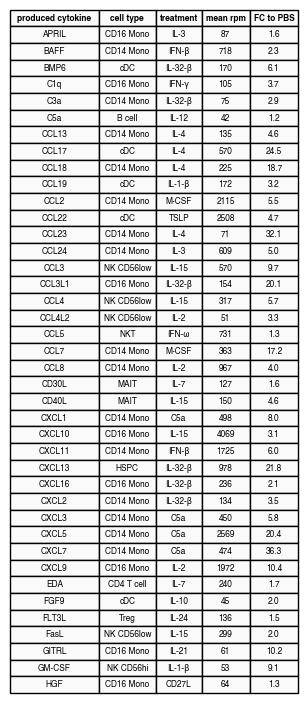

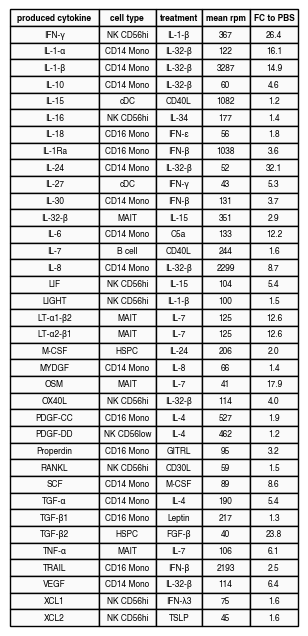

In [109]:
# For each cytokine (column), get the index (cell type) and value of the maximum in cytokine_expression_df_all_details
cytokine_expression_df_all_details_filter = cytokine_expression_df_all_details.loc[ALL_CELL_TYPES_EXCLUDE]

cytokine_max_indices = cytokine_expression_df_all_details_filter.idxmax(axis=0)
cytokine_max_values = cytokine_expression_df_all_details_filter.max(axis=0)

cytokine_max_values = cytokine_max_values[cytokine_max_values > 40]
cytokine_max_indices = cytokine_max_indices.loc[cytokine_max_values.index]

# Create a DataFrame for better display
cytokine_max_indices_df = pd.DataFrame({
    'produced cytokine': cytokine_max_indices.index,
    'cell-stim': cytokine_max_indices.values,
    'mean rpm': cytokine_max_values.values
})
cytokine_max_indices_df['cell type'] = cytokine_max_indices_df['cell-stim'].apply(lambda x: x[0])
cytokine_max_indices_df['treatment'] = cytokine_max_indices_df['cell-stim'].apply(lambda x: x[1])
cytokine_max_indices_df['mean rpm'] = cytokine_max_indices_df['mean rpm']
cytokine_max_indices_df['mean rpm PBS'] = None
for index, row in cytokine_max_indices_df.iterrows():
    cell_type = row['cell type']
    cytokine = row['produced cytokine']
    cytokine_max_indices_df.loc[index, 'mean rpm PBS'] = cytokine_expression_df_all_PBS.loc[cell_type, cytokine]

cytokine_max_indices_df['FC to PBS'] = cytokine_max_indices_df['mean rpm'] / cytokine_max_indices_df['mean rpm PBS']
cytokine_max_indices_df['mean rpm'] = cytokine_max_indices_df['mean rpm'].astype(int)
cytokine_max_indices_df['FC to PBS'] = cytokine_max_indices_df['FC to PBS'].astype(float).round(1)

# Only use max_expression, cell_type, and treatment columns, and split into two tables with at most 40 entries each
cols_to_show = ['produced cytokine', 'cell type', 'treatment', 'mean rpm', 'FC to PBS']
df_to_show = cytokine_max_indices_df[cols_to_show]
df_to_show = df_to_show.sort_values(by='produced cytokine')
df_to_show['produced cytokine'] = df_to_show['produced cytokine'].apply(lambda x: introduce_greek_letters(x))
df_to_show['treatment'] = df_to_show['treatment'].apply(lambda x: introduce_greek_letters(x))

max_rows_per_table = 40
num_rows = len(df_to_show)
num_tables = (num_rows // max_rows_per_table) + int(num_rows % max_rows_per_table > 0)

for i in range(num_tables):
    start_idx = i * max_rows_per_table
    end_idx = min((i + 1) * max_rows_per_table, num_rows)
    sub_df = df_to_show.iloc[start_idx:end_idx]
    
    fig, ax = plt.subplots(figsize=cm_to_inches((7, num_rows / 22)))
    ax.axis('off')
    table = ax.table(
        cellText=sub_df.values,
        colLabels=sub_df.columns,
        loc='center',
        cellLoc='center'
    )
    table.auto_set_font_size(False)
    table.set_fontsize(6)
    table.auto_set_column_width(col=list(range(len(sub_df.columns))))

    # Set header row (row=0) to bold and light gray background
    header_color = '#fafafa'
    for col in range(len(sub_df.columns)):
        cell = table[0, col]
        cell.set_fontsize(6)
        cell.set_text_props(weight='bold')
        cell.set_facecolor(header_color)
    
    # Set all data cells to light gray background
    for row in range(1, len(sub_df) + 1):
        for col in range(len(sub_df.columns)):
            cell = table[row, col]
            cell.set_facecolor(header_color)
    
    plt.tight_layout()
    plt.savefig(os.path.join(plot_folder, f"4_max_cytokine_production_table_{i}.svg")) 

In [110]:
# 2) Get the actual expression filter for all cytokines and out tested (parse) cytokines
expressed_cytokines_by_cell_type_all_df = (cytokine_expression_df_mean > 4) & (cytokine_expression_df_max > 20) & (cytokine_expression_df_substantial > 20)
expressed_cytokines_by_cell_type_all = {}
for cell_type in expressed_cytokines_by_cell_type_all_df.index:
    series = expressed_cytokines_by_cell_type_all_df.loc[cell_type]
    expressed_cytokines_by_cell_type_all[cell_type] = [cyto for cyto in series.index if series[cyto]]
    
expressed_cytokines_by_cell_type_parse = {}
for cell_type in expressed_cytokines_by_cell_type_all.keys():
    curr_list = expressed_cytokines_by_cell_type_all[cell_type]
    expressed_cytokines_by_cell_type_parse[cell_type] = [cyto for cyto in curr_list if cyto in CYTOKINE_ORDER]

In [111]:
# Filter to genes where the maximum average expression (across cell types) is at least 4 and the maximum maximum expression (across cell types) at least 20
cytokine_expression_df_filtered_mean = cytokine_expression_df_mean.loc[:, cytokine_expression_df_mean.loc[ALL_CELL_TYPES_EXCLUDE].max(axis=0) > 4]
cytokine_expression_df_filtered_max = cytokine_expression_df_max.loc[:, cytokine_expression_df_max.loc[ALL_CELL_TYPES_EXCLUDE].max(axis=0) > 20]

# get the intersection of the two column sets
columns_mean = cytokine_expression_df_filtered_mean.columns
columns_max = cytokine_expression_df_filtered_max.columns
columns_intersection = columns_mean.intersection(columns_max)
print(len(columns_intersection))

# 3) Filter the *mean* average expression to these columns.
cytokine_expression_df_filtered = cytokine_expression_df_filtered_mean.loc[ALL_CELL_TYPES_EXCLUDE, columns_intersection]

83


In [112]:
cytokine_expression_df_mean['CX3CL1']

cell_type
B cell        1.039080
CD14 Mono     0.979276
CD16 Mono     0.977927
CD4 T cell    0.983060
CD8 T cell    0.983677
HSPC          0.977748
MAIT          0.985964
NK CD56hi     0.977143
NK CD56low    0.993232
NKT           0.978221
Treg          0.987355
cDC           1.148910
pDC           1.043376
Name: CX3CL1, dtype: float64

#### Calculate family counts

In [113]:
maximum_cell_type_count = {cell_type: 0 for cell_type in ALL_CELL_TYPES_EXCLUDE}
maximum_cell_type_identity = {}
maximum_cell_type_list = []
for column in cytokine_expression_df_filtered.columns:
    maximum_cell_type = cytokine_expression_df_filtered[column].idxmax()
    row = {
        "cell_type": maximum_cell_type,
        "cytokine": column
    }
    maximum_cell_type_list.append(row)
    maximum_cell_type_count[maximum_cell_type] += 1
    maximum_cell_type_identity[column] = maximum_cell_type

maximum_cell_type_df = pd.DataFrame(maximum_cell_type_list)
maximum_cell_type_df["family"] = maximum_cell_type_df["cytokine"].map(cytokine_name_to_level_2_family)
family_value_counts_df = maximum_cell_type_df.groupby("cell_type")["family"].value_counts().unstack().fillna(0)
# Order the family_value_counts_df by ALL_CELL_TYPES
family_value_counts_df = family_value_counts_df.reindex(ALL_CELL_TYPES_EXCLUDE).dropna()

available_families = family_value_counts_df.columns
ordered_available_families = [family for family in cytokine_level_2_order if family in available_families]
family_value_counts_df = family_value_counts_df[ordered_available_families]
family_value_counts_df = family_value_counts_df.iloc[:, ::-1]

In [114]:
maximum_cell_type_df[maximum_cell_type_df['family'] == "CX3C"]

,cell_type,cytokine,family


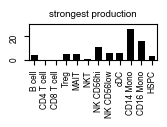

In [115]:
max_value_counts = maximum_cell_type_df["cell_type"].value_counts()
for cell_type in ALL_CELL_TYPES_EXCLUDE:
    if not cell_type in max_value_counts.index:
        max_value_counts[cell_type] = 0
max_value_counts = max_value_counts[ALL_CELL_TYPES_EXCLUDE]

plt.figure(figsize=cm_to_inches((4.2,3.2)))
plt.bar(max_value_counts.index, max_value_counts.values, color="black", width=0.65)
plt.title("strongest production", fontsize=7)
plt.xticks(rotation=90)
plt.yticks(rotation=90)
plt.xlim(-0.5, len(max_value_counts)-0.5)
plt.ylim(0, 30)
plt.tight_layout()
for format in ["png", "svg"]:
    plt.savefig(os.path.join(plot_folder, f"4_max_cell_type_count.{format}"), dpi=300)

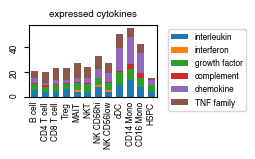

In [116]:
any_value_counts = expressed_cytokines_by_cell_type_all_df.loc[ALL_CELL_TYPES_EXCLUDE].unstack().to_frame().reset_index()
any_value_counts = any_value_counts.rename(columns={0: "expressed", "level_0": "cytokine"})
any_value_counts["level1_family"] = any_value_counts["cytokine"].map(cytokine_name_to_level_1_family)
any_level1_family_count = any_value_counts.groupby(["cell_type", "level1_family"])["expressed"].sum().to_frame().reset_index()
relevant_families = any_level1_family_count.groupby("level1_family")["expressed"].sum()
relevant_families = relevant_families[relevant_families > 0].index
any_level1_family_count = any_level1_family_count[any_level1_family_count["level1_family"].isin(relevant_families)]

# Create a pivot table to get counts by cell type and level1_family
pivot_df = any_level1_family_count.pivot(index="cell_type", columns="level1_family", values="expressed").fillna(0)

# Reindex to ensure all cell types are included in the correct order
pivot_df = pivot_df.reindex(ALL_CELL_TYPES_EXCLUDE).fillna(0)

# Order the families according to a sensible order (could be alphabetical or custom)
ordered_families = sorted(pivot_df.columns)

# Create the stacked bar plot
ax = pivot_df[ordered_families[::-1]].plot(kind='bar', stacked=True, figsize=cm_to_inches((4.2,4)), width=0.65)

# Customize the plot
plt.xlabel("")
plt.title("expressed cytokines", fontsize=7)
plt.xticks(rotation=90)
plt.yticks(rotation=90)

# set xtick length to 0
# Set the x-tick length to 0
plt.tick_params(axis='x', which='both', length=0)


plt.tight_layout()
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
# Save the plot
for format in ["png", "svg"]:
    plt.savefig(os.path.join(plot_folder, f"4_cytokine_family_by_cell_type.{format}"), dpi=300)

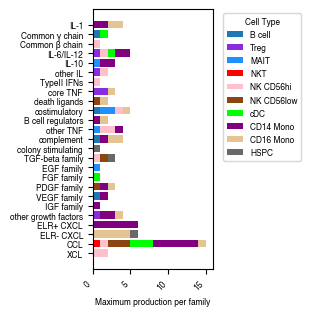

In [117]:
# Transpose the dataframe to plot by cytokine family instead of cell type
family_counts_by_cell_type = family_value_counts_df.T

# Plot the stacked vertical bar graph using matplotlib
fig, ax = plt.subplots(figsize=cm_to_inches((8, 8)))

# Plot each cell type as a separate bar segment
bottom = np.zeros(len(family_counts_by_cell_type.index))
for cell_type in family_counts_by_cell_type.columns:
    ax.barh(family_counts_by_cell_type.index, family_counts_by_cell_type[cell_type], 
           left=bottom, label=cell_type, color=CELL_TYPE_COLORS.get(cell_type, 'gray'))
    bottom += family_counts_by_cell_type[cell_type]

# Add labels and title
ax.set_xlabel('Maximum production per family')
ax.set_ylabel('')
ax.legend(title='Cell Type', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45, ha='right')
plt.xlim(0, 16)
plt.tight_layout()

# Show the plot
for format in ["png", "svg"]:
    plt.savefig(os.path.join(plot_folder, f"4_maximum_expression_by_family.{format}"), dpi=300)

In [118]:
family_counts_by_cell_type

cell_type,B cell,Treg,MAIT,NKT,NK CD56hi,NK CD56low,cDC,CD14 Mono,CD16 Mono,HSPC
family,,,,,,,,,,
XCL,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0
CCL,0.0,0.0,0.0,1.0,1.0,3.0,3.0,6.0,1.0,0.0
ELR- CXCL,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,1.0
ELR+ CXCL,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.0,0.0,0.0
other growth factors,0.0,1.0,0.0,0.0,0.0,0.0,0.0,2.0,1.0,0.0
IGF family,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
VEGF family,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
PDGF family,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0
FGF family,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


In [119]:
# 4) Calculate the relative rpm across cell types
cytokine_expression_df_rel = cytokine_expression_df_filtered.div(cytokine_expression_df_filtered.max(axis=0), axis=1)

# sort the columns by the maximum cell type identity
maximum_cell_type_identity = pd.DataFrame([(k,v) for k,v in maximum_cell_type_identity.items()], columns=['gene', 'cell_type'])

# sort cell type by ALL_CELL_TYPES_EXCLUDE
maximum_cell_type_identity["cell_type"] = pd.Categorical(maximum_cell_type_identity["cell_type"], categories=ALL_CELL_TYPES_EXCLUDE, ordered=True)
maximum_cell_type_identity = maximum_cell_type_identity.sort_values(by="cell_type")

# apply sorting
cytokine_expression_df_rel = cytokine_expression_df_rel.loc[ALL_CELL_TYPES_EXCLUDE, maximum_cell_type_identity["gene"]]

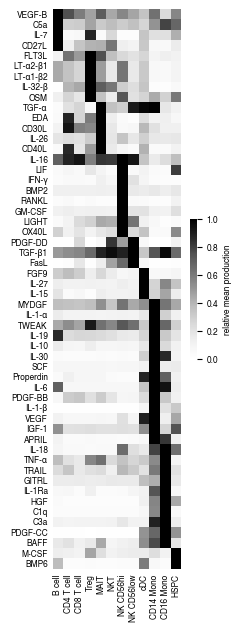

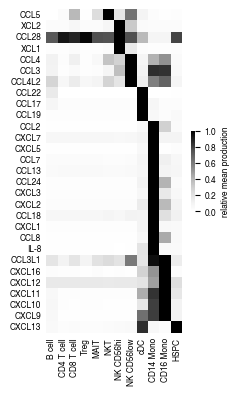

In [120]:
# plot in two separate groups
cytokine_groups_here = [['interleukin', 'interferon', 'TNF family', 'complement', 'growth factor', 'other'], ["chemokine"]]
for group_index, family in enumerate(cytokine_groups_here):
    cytokine_expression_df_rel_family = cytokine_expression_df_rel.loc[:, cytokine_info["family_level_1"].isin(family)]
    if group_index == 0:
        plt.figure(figsize=cm_to_inches((6, 16)))
    else:
        plt.figure(figsize=cm_to_inches((6, 10)))

    # Create heatmap
    ax = sns.heatmap(cytokine_expression_df_rel_family.T, cmap="Grays", vmin=0, vmax=1,
                     cbar_kws={"ticks": [0, 0.2, 0.4, 0.6, 0.8, 1], 
                              "label": "relative mean production", 
                              "shrink": 0.25}, 
                     square=False)

    # Fix y-axis labels
    plt.yticks(rotation=0)  # Make labels horizontal
    ax.tick_params(axis='y', labelsize=6)
    
    # Get all tick positions and labels
    tick_positions = np.arange(len(cytokine_expression_df_rel_family.columns))+0.5
    labels = [introduce_greek_letters(label) for label in cytokine_expression_df_rel_family.columns]
    
    # Set all ticks and labels explicitly
    ax.set_yticks(tick_positions)
    ax.set_yticklabels(labels)
    
    # set lengths to 0
    ax.tick_params(axis='y', labelsize=6, length=0)
    ax.tick_params(axis='x', length=0)

    # Remove x label
    plt.xlabel("")
    
    # Adjust layout
    plt.tight_layout()
    
    # Save plots
    for format in ["png", "svg"]:
        plt.savefig(os.path.join(plot_folder, f"4_average_cytokine_production_by_cell_type_{group_index}.{format}"), 
                    bbox_inches="tight",
                    dpi=300)

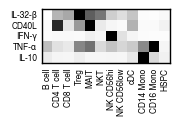

In [121]:

cytokine_expression_df_rel_family = cytokine_expression_df_rel.loc[:, ["IL-32-beta", "CD40L", "IFN-gamma", "TNF-alpha", "IL-10"]]
plt.figure(figsize=cm_to_inches((4.525, 3)))

# Create heatmap
ax = sns.heatmap(cytokine_expression_df_rel_family.T, cmap="Grays", vmin=0, vmax=1,
                    cbar=False,
                    square=True,
                    linewidths=0,  # Add lines between cells
                    linecolor='black')  # Make lines black

# Fix y-axis labels
plt.yticks(rotation=0)  # Make labels horizontal
ax.tick_params(axis='y', labelsize=6)

# Get all tick positions and labels
tick_positions = np.arange(len(cytokine_expression_df_rel_family.columns))+0.5
labels = [introduce_greek_letters(label) for label in cytokine_expression_df_rel_family.columns]

# Set all ticks and labels explicitly
ax.set_yticks(tick_positions)
ax.set_yticklabels(labels)

# set lengths to 0
ax.tick_params(axis='y', labelsize=6, length=0)
ax.tick_params(axis='x', length=0)

# Remove x label
plt.xlabel("")

# Add black box around heatmap
ax.spines['top'].set_visible(True)
ax.spines['right'].set_visible(True)
ax.spines['bottom'].set_visible(True)
ax.spines['left'].set_visible(True)
for spine in ax.spines.values():
    spine.set_color('black')
    spine.set_linewidth(1)

# Adjust layout
plt.tight_layout()

# Save plots
for format in ["png", "svg"]:
    plt.savefig(os.path.join(plot_folder, f"4_average_cytokine_production_by_cell_type_particular.{format}"), 
                bbox_inches="tight",
                dpi=300)

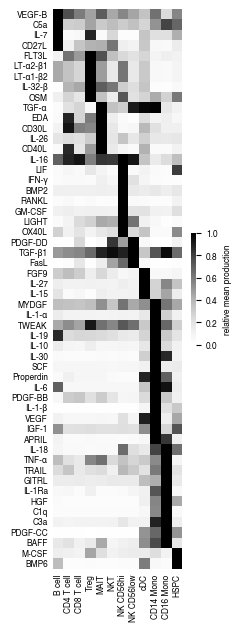

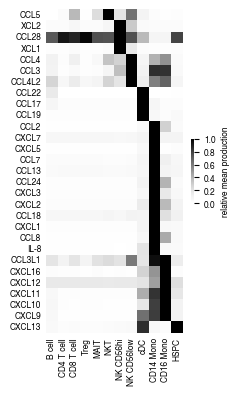

In [122]:
# plot in two separate groups
cytokine_groups_here = [['interleukin', 'interferon', 'TNF family', 'complement', 'growth factor', 'other'], ["chemokine"]]
for group_index, family in enumerate(cytokine_groups_here):
    cytokine_expression_df_rel_family = cytokine_expression_df_rel.loc[:, cytokine_info["family_level_1"].isin(family)]
    if group_index == 0:
        plt.figure(figsize=cm_to_inches((6, 16)))
    else:
        plt.figure(figsize=cm_to_inches((6, 10)))

    # Create heatmap
    ax = sns.heatmap(cytokine_expression_df_rel_family.T, cmap="Grays", vmin=0, vmax=1,
                     cbar_kws={"ticks": [0, 0.2, 0.4, 0.6, 0.8, 1], 
                              "label": "relative mean production", 
                              "shrink": 0.2}, 
                     square=False)

    # Fix y-axis labels
    plt.yticks(rotation=0)  # Make labels horizontal
    ax.tick_params(axis='y', labelsize=6)
    
    # Get all tick positions and labels
    tick_positions = np.arange(len(cytokine_expression_df_rel_family.columns))+0.5
    labels = [introduce_greek_letters(label) for label in cytokine_expression_df_rel_family.columns]
    
    # Set all ticks and labels explicitly
    ax.set_yticks(tick_positions)
    ax.set_yticklabels(labels)
    
    # set lengths to 0
    ax.tick_params(axis='y', labelsize=6, length=0)
    ax.tick_params(axis='x', length=0)

    # Remove x label
    plt.xlabel("")
    
    # Adjust layout
    plt.tight_layout()
    
    # Save plots
    for format in ["png", "svg"]:
        plt.savefig(os.path.join(plot_folder, f"4_average_cytokine_production_by_cell_type_{group_index}.{format}"), 
                    bbox_inches="tight",
                    dpi=300)

### 4.2 - Factor in literature

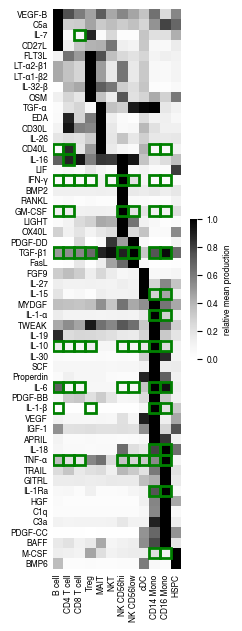

In [123]:
group_index = 0
family = cytokine_groups_here[0]
cytokine_expression_df_rel_family = cytokine_expression_df_rel.loc[:, cytokine_info["family_level_1"].isin(family)]
current_cell_types = cytokine_expression_df_rel_family.index
current_cytokines = cytokine_expression_df_rel_family.columns

if group_index == 0:
    plt.figure(figsize=cm_to_inches((6, 16)))
else:
    plt.figure(figsize=cm_to_inches((6, 10)))

# Create heatmap
ax = sns.heatmap(cytokine_expression_df_rel_family.T, cmap="Grays", vmin=0, vmax=1,
                    cbar_kws={"ticks": [0, 0.2, 0.4, 0.6, 0.8, 1], 
                            "label": "relative mean production", 
                            "shrink": 0.25}, 
                    square=False)

# Map cell types to their index
cell_type_to_index = {cell_type: idx for idx, cell_type in enumerate(current_cell_types)}
alyssa_secretion_df["cell_type_index"] = alyssa_secretion_df["cell_type"].map(cell_type_to_index)

# Map cytokines to their index
cytokine_to_index = {cytokine: idx for idx, cytokine in enumerate(current_cytokines)}
alyssa_secretion_df["cytokine_index"] = alyssa_secretion_df["cytokine"].map(cytokine_to_index)

df_subset = alyssa_secretion_df.dropna(subset=["cell_type_index", "cytokine_index"])
sumpapers_threshold = 3

df_subset = df_subset[df_subset["sumpapers"] >= sumpapers_threshold]

for index, row in df_subset.iterrows():
    x_idx = row["cell_type_index"]
    y_idx = row["cytokine_index"]
    # Create a rectangle patch
    rect = plt.Rectangle(
        (x_idx, y_idx),  # (x, y) bottom left corner
        1, 1,            # width, height
        linewidth=2,
        edgecolor='green',
        facecolor='none',
        zorder=10        # Ensure it's drawn on top
    )

    # Add the rectangle to the plot
    ax.add_patch(rect)


# Fix y-axis labels
plt.yticks(rotation=0)  # Make labels horizontal
ax.tick_params(axis='y', labelsize=6)

# Get all tick positions and labels
tick_positions = np.arange(len(cytokine_expression_df_rel_family.columns))+0.5
labels = [introduce_greek_letters(label) for label in cytokine_expression_df_rel_family.columns]

# Set all ticks and labels explicitly
ax.set_yticks(tick_positions)
ax.set_yticklabels(labels)

# set lengths to 0
ax.tick_params(axis='y', labelsize=6, length=0)
ax.tick_params(axis='x', length=0)

# Remove x label
plt.xlabel("")

# Adjust layout
plt.tight_layout()

# # Save plots
# for format in ["png", "svg"]:
#     plt.savefig(os.path.join(plot_folder, f"4_average_cytokine_production_by_cell_type_{group_index}.{format}"), 
#                 bbox_inches="tight",
#                 dpi=300)

# 5 - Signaling Crosstalk

## 5.1 - Cytokine to cytokine crosstalk

In [124]:
plot_folder = os.path.join(base_plot_folder, "5.1_cytokine_to_cytokine_production")
os.makedirs(plot_folder, exist_ok=True)

In [125]:
# constrain to all cytokines that have a calculated fold change for all subunits (here as gene lists per cytokine)
all_cytokines_in_measured_genes = [cytokine for cytokine in cytokine_info["gene"] if all([subunit in edger_df_padj.index for subunit in cytokine.split(", ")])]

# get the padj and log2FoldChange values for all necessary genes
all_cytokines_in_measured_genes_flat = [subunit for cytokine in all_cytokines_in_measured_genes for subunit in cytokine.split(", ")]
edger_df_padj_cytokine = edger_df_padj.loc[edger_df_padj.index.isin(all_cytokines_in_measured_genes_flat), :].fillna(1)
edger_df_log2FoldChange_cytokine = edger_df_log2FoldChange.loc[edger_df_padj.index.isin(all_cytokines_in_measured_genes_flat), :].fillna(0)

In [126]:
cytokine_response_df_all = pd.DataFrame(columns=["cell_type", "treatment", "response", "p_value", "fold_changes"])

for cell_type in ALL_CELL_TYPES:
    for cytokine_treatment in CYTOKINE_ORDER:
        for cytokine_response in all_cytokines_in_measured_genes:
            individual_cytokines = cytokine_response.split(", ")
            
            # skip this response if not significant
            skip = False
            for individual_cytokine in individual_cytokines:
                if not individual_cytokine in edger_df_padj_cytokine.index:
                    skip = True
            if skip:
                continue
            
            p_value = max([edger_df_padj_cytokine.loc[individual_cytokine, (cell_type, cytokine_treatment)].astype(float) for individual_cytokine in individual_cytokines])
            fold_changes = [edger_df_log2FoldChange_cytokine.loc[individual_cytokine, (cell_type, cytokine_treatment)].astype(float) for individual_cytokine in individual_cytokines]
            if p_value > 0.05:
                continue
            
            new_row = pd.DataFrame({
                "cell_type": [cell_type], 
                "treatment": [cytokine_treatment], 
                "response": [cytokine_response],
                "p_value": [p_value],
                "fold_changes": [fold_changes]
            })
            cytokine_response_df_all = pd.concat([cytokine_response_df_all, new_row], axis=0)

C:\Users\loesi\AppData\Local\Temp\ipykernel_37688\1499141675.py:28: FutureWarning:

The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.



In [127]:
cytokine_response_df_all['single_fc'] = cytokine_response_df_all['fold_changes'].apply(min)
cytokine_response_df_all[cytokine_response_df_all["treatment"] == "IL-32-beta"].sort_values(by="single_fc")

,cell_type,treatment,response,p_value,fold_changes,single_fc
0,CD14 Mono,IL-32-beta,CCL13,8.958717e-08,[-5.786159454419856],-5.786159
0,cDC,IL-32-beta,CXCL11,1.278919e-05,[-4.8506855517734495],-4.850686
0,CD14 Mono,IL-32-beta,CXCL11,7.917248e-05,[-4.6668132798475215],-4.666813
0,CD16 Mono,IL-32-beta,CXCL11,5.702516e-04,[-4.585470287051346],-4.585470
0,CD14 Mono,IL-32-beta,CXCL10,2.827270e-05,[-4.317194029328321],-4.317194
...,...,...,...,...,...,...
0,CD14 Mono,IL-32-beta,CXCL8,7.604813e-07,[5.132771901546818],5.132772
0,CD14 Mono,IL-32-beta,IL1B,6.154854e-07,[5.5461711868171735],5.546171
0,CD14 Mono,IL-32-beta,IL24,1.094415e-05,[6.154761886194283],6.154762
0,cDC,IL-32-beta,CXCL5,1.652073e-05,[6.813785502883873],6.813786


In [128]:
# convert back to actual cytokine names
cytokine_translation = cytokine_info.reset_index().set_index("gene")["name"].to_dict()
cytokine_response_df_all.loc[:, "response"] = cytokine_response_df_all["response"].map(cytokine_translation)

# display duplicates
# cytokine_response_df_all[cytokine_response_df_all.duplicated(subset=["cell_type", "treatment", "response"], keep=False)]

# remove duplicates (basically just LTA, LTB because they have the same genes)
print(len(cytokine_response_df_all))
cytokine_response_df_all = cytokine_response_df_all.drop_duplicates(ignore_index=True, subset=["cell_type", "treatment", "response"])
print(len(cytokine_response_df_all))

# add the direction of the regulation
direction = []
for index, row in cytokine_response_df_all.iterrows():
    if all([fc > 1 for fc in row["fold_changes"]]):
        direction.append("upregulated")
    elif all([fc < -1 for fc in row["fold_changes"]]):
        direction.append("downregulated")
    else:
        direction.append("neither")
        
cytokine_response_df_all["direction"] = direction

3235
3210


In [129]:
# save the results
cytokine_response_df_all.to_csv(os.path.join(output_tables_folder, "Table_4.2_cytokine-cytokine-crosstalk-all.csv"), index=False)

# filter to parse cytokines and save that subset
cytokine_response_df_all_filter = cytokine_response_df_all[cytokine_response_df_all["response"].isin(cytokine_info_parse.index)]
cytokine_response_df_all_filter.to_csv(os.path.join(output_tables_folder, "5.1_cytokine-cytokine-crosstalk-parse.csv"), index=False)

In [130]:
def create_sankey_diagram(df, column1_name=None, column1_order=None, column2_name=None, column2_order=None,
                          column3_name=None, column3_order=None,
                          color1 = "rgba(31, 119, 180, 0.8)", color2 = "rgba(44, 160, 44, 0.8)", color3 = "rgba(255, 127, 14, 0.8)",
                          title="Cytokine crosstalk between treatments and responses"):
    """
    Create a Sankey diagram with preserved node ordering and proper column spacing.
    
    Parameters:
    df: pandas DataFrame
    column1_name: name of the first column
    column1_order: list of column1 names in desired order (optional)
    column2_name: name of the second column
    column2_order: list of column2 names in desired order (optional)
    column3_name: name of the third column
    column3_order: list of column3 names in desired order (optional)
    """

    # get order of values in the columns
    column1_values = pd.unique(df[column1_name]).tolist()
    column2_values = pd.unique(df[column2_name]).tolist()
    column3_values = pd.unique(df[column3_name]).tolist()
    
    # Use provided orders or by the order of the values in the dataframe
    if column1_order is not None:
        missing_column1_values = set(df[column1_name].unique()) - set(column1_order)
        if missing_column1_values:
            raise ValueError(f"Column1 order missing values: {missing_column1_values}")
        column1_values = [value for value in column1_order if value in df[column1_name].unique()]
        
    if column2_order is not None:
        missing_column2_values = set(df[column2_name].unique()) - set(column2_order)
        if missing_column2_values:
            raise ValueError(f"Column2 order missing values: {missing_column2_values}")
        column2_values = [value for value in column2_order if value in df[column2_name].unique()]
        
    if column3_order is not None:
        missing_column3_values = set(df[column3_name].unique()) - set(column3_order)
        if missing_column3_values:
            raise ValueError(f"Column3 order missing values: {missing_column3_values}")
        column3_values = [value for value in column3_order if value in df[column3_name].unique()]

    # Create mapping dictionaries with ordered indices
    column1_to_idx = {t: idx for idx, t in enumerate(column1_values)}
    column2_to_idx = {c: idx + len(column1_values) for idx, c in enumerate(column2_values)}
    column3_to_idx = {r: idx + len(column1_values) + len(column2_values) for idx, r in enumerate(column3_values)}
    
    # Calculate link values while preserving order
    links = []
    
    # First column to second column (treatments to cell types)
    for t in column1_values:
        for c in column2_values:
            count = len(df[(df[column1_name] == t) & (df[column2_name] == c)])
            if count > 0:
                links.append({
                    'source': column1_to_idx[t],
                    'target': column2_to_idx[c],
                    'value': count
                })
        
    # Second column to third column (cell types to responses)
    for c in column2_values:
        for r in column3_values:
            count = len(df[(df[column2_name] == c) & (df[column3_name] == r)])
            if count > 0:
                links.append({
                    'source': column2_to_idx[c],
                    'target': column3_to_idx[r],
                    'value': count
                })

    # Extract sources, targets, and values from links
    sources = [link['source'] for link in links]
    targets = [link['target'] for link in links]
    values = [link['value'] for link in links]

    # Create color scheme
    n_column1_values = len(column1_values)
    n_column2_values = len(column2_values)
    n_column3_values = len(column3_values)
    
    colors = (
        [color1] * n_column1_values +  # Blue for column1
        [color2] * n_column2_values +   # Green for column2
        [color3] * n_column3_values     # Orange for column3
    )
    
    # Create node labels in the correct order
    display_labels = column1_values + column2_values + column3_values
    
    # Calculate node positions
    if n_column1_values > n_column3_values:
        x_positions = (
            [0.0] * n_column1_values +  # First column
            [0.5] * n_column2_values +  # Middle column
            [1.0] * n_column3_values     # Last column
        )
    else:
        x_positions = (
            [0.0] * n_column1_values +  # First column
            [0.3] * n_column2_values +  # Middle column
            [1.0] * n_column3_values     # Last column
        )
    
    # Create y positions that spread nodes evenly within their columns
    y_column1_values = np.linspace(0.05, 0.95, n_column1_values) if n_column1_values > 1 else [0.5]
    y_column2_values = np.linspace(0.05, 0.95, n_column2_values) if n_column2_values > 1 else [0.5]
    y_column3_values = np.linspace(0.05, 0.95, n_column3_values) if n_column3_values > 1 else [0.5]
    
    y_positions = list(y_column1_values) + list(y_column2_values) + list(y_column3_values)
    
    # Create Sankey Diagram
    fig = go.Figure(data=[go.Sankey(
        node=dict(
            pad=5,
            thickness=10,
            line=dict(color='black', width=0.5),
            label=display_labels,
            color=colors,
            x=x_positions,
            y=y_positions,
        ),
        link=dict(
            source=sources,
            target=targets,
            value=values,
            hovertemplate='Source: %{source.label}<br>Target: %{target.label}<br>Value: %{value}<extra></extra>',
            line=dict(color='rgba(0,0,0,0)', width=0)  # Remove edge stroke
        ),
        arrangement='snap'
    )])
    
    # Dynamic height scaling and improved margins
    fig.update_layout(
        font_size=6,
        height=max(n_column1_values, n_column2_values, n_column3_values) * 12.5,  # Adjust node spacing
        width=125,
        margin=dict(
            l=10,  # Left margin
            r=10,  # Right margin
            t=25,  # Top margin
            b=25   # Bottom margin to prevent cutoff
        ),
        showlegend=False,
        # set the font color to black
        font=dict(color='black'),
        title=title
    )
    return fig



In [131]:
treatment_order = CYTOKINE_ORDER
response_order = CYTOKINE_ORDER

treatment_order = [introduce_greek_letters(treatment) for treatment in treatment_order]
response_order = [introduce_greek_letters(response) for response in response_order]

# make sure the fold-change is sufficiently large for all gene products
cytokine_response_df_all_curr = cytokine_response_df_all_filter[cytokine_response_df_all_filter["direction"] == "upregulated"]
cytokine_response_df_all_curr.loc[:, "response"] = cytokine_response_df_all_curr["response"].apply(lambda x: introduce_greek_letters(x))
cytokine_response_df_all_curr.loc[:, "treatment"] = cytokine_response_df_all_curr["treatment"].apply(lambda x: introduce_greek_letters(x))

# now, do this separately for every cytokine
current_plot_folder = os.path.join(plot_folder, "5.1_upregulates_others")
os.makedirs(current_plot_folder, exist_ok=True)
for current_treatment in cytokine_response_df_all_curr["treatment"].unique():
    current_df = cytokine_response_df_all_curr[cytokine_response_df_all_curr["treatment"] == current_treatment]
    if len(current_df) < 4:
        continue
    fig = create_sankey_diagram(
        df=current_df,
        column1_name="treatment",
        column1_order=treatment_order,
        column2_name="cell_type",
        column3_name="response",
        column3_order=response_order,
        color1 = "rgba(44, 160, 44, 0.8)",
        color2 = "rgba(31, 119, 180, 0.8)",
        color3 = "rgba(44, 160, 44, 0.8)",
        title=None
    )
    fig.write_image(os.path.join(current_plot_folder, f"5.1_cytokine_{unidecode(current_treatment)}_upregulates_others.svg"), engine="kaleido")
    fig.write_image(os.path.join(current_plot_folder, f"5.1_cytokine_{unidecode(current_treatment)}_upregulates_others.png"), engine="kaleido")

current_plot_folder = os.path.join(plot_folder, "5.1_is_upregulated_by_others")
os.makedirs(current_plot_folder, exist_ok=True)
for current_response in cytokine_response_df_all_curr["response"].unique():
    current_df = cytokine_response_df_all_curr[cytokine_response_df_all_curr["response"] == current_response]
    if len(current_df) < 6:
        continue
    fig = create_sankey_diagram(
        df=current_df,
        column1_name="treatment",
        column1_order=treatment_order,
        column2_name="cell_type",
        column3_name="response",
        column3_order=response_order,
        color1 = "rgba(44, 160, 44, 0.8)",
        color2 = "rgba(31, 119, 180, 0.8)",
        color3 = "rgba(44, 160, 44, 0.8)",
        title=None
    )
    fig.write_image(os.path.join(current_plot_folder, f"5.1_cytokine_{unidecode(current_response)}_is_upregulated_by_others.svg"), engine="kaleido")
    fig.write_image(os.path.join(current_plot_folder, f"5.1_cytokine_{unidecode(current_response)}_is_upregulated_by_others.png"), engine="kaleido", scale=4)
    
# make sure the fold-change is significant for all gene products
cytokine_response_df_all_curr = cytokine_response_df_all_filter[cytokine_response_df_all_filter["direction"] == "downregulated"]
cytokine_response_df_all_curr.loc[:, "response"] = cytokine_response_df_all_curr["response"].apply(lambda x: introduce_greek_letters(x))
cytokine_response_df_all_curr.loc[:, "treatment"] = cytokine_response_df_all_curr["treatment"].apply(lambda x: introduce_greek_letters(x))

# now, do this separately for every cytokine
current_plot_folder = os.path.join(plot_folder, "5.1_downregulates_others")
os.makedirs(current_plot_folder, exist_ok=True)
for current_treatment in cytokine_response_df_all_curr["treatment"].unique():
    current_df = cytokine_response_df_all_curr[cytokine_response_df_all_curr["treatment"] == current_treatment]
    if len(current_df) < 4:
        continue
    fig = create_sankey_diagram(
        df=current_df,
        column1_name="treatment",
        column1_order=treatment_order,
        column2_name="cell_type",
        column3_name="response",
        column3_order=response_order,
        color1 = "rgba(44, 160, 44, 0.8)",
        color2 = "rgba(31, 119, 180, 0.8)",
        color3 = "rgba(44, 160, 44, 0.8)",
        title=None
    )
    fig.write_image(os.path.join(current_plot_folder, f"5.1_cytokine_{unidecode(current_treatment)}_downregulates_others.svg"), engine="kaleido")
    fig.write_image(os.path.join(current_plot_folder, f"5.1_cytokine_{unidecode(current_treatment)}_downregulates_others.png"), engine="kaleido")

### IL-32-beta analysis

In [132]:
IL32b_response = cytokine_response_df_all[cytokine_response_df_all["response"] == "IL-32-beta"]
IL32b_response.to_csv(os.path.join(output_tables_folder, "Table_4.3_IL-32-beta_response.csv"), index=False)
IL32b_treatment = cytokine_response_df_all[cytokine_response_df_all["treatment"] == "IL-32-beta"]
IL32b_treatment.to_csv(os.path.join(output_tables_folder, "Table_4.3_IL-32-beta_treatment.csv"), index=False)

In [133]:
IL32b_response[IL32b_response["single_fc"] > 1]

,cell_type,treatment,response,p_value,fold_changes,single_fc,direction
371,CD8 T cell,IL-2,IL-32-beta,2.792354e-07,[1.0409775299519672],1.040978,upregulated
407,CD8 T cell,IL-15,IL-32-beta,4.432866e-07,[1.3620582571168331],1.362058,upregulated
731,MAIT,IL-2,IL-32-beta,1.783194e-07,[1.2556292089813448],1.255629,upregulated
749,MAIT,IL-7,IL-32-beta,5.027374e-08,[1.1981237704227563],1.198124,upregulated
770,MAIT,IL-15,IL-32-beta,3.160419e-09,[1.5158751069601004],1.515875,upregulated
1404,cDC,IL-2,IL-32-beta,7.609242e-07,[1.1429983776615638],1.142998,upregulated
1482,cDC,IL-15,IL-32-beta,3.121581e-07,[1.2393414611639506],1.239341,upregulated
1901,CD14 Mono,IL-2,IL-32-beta,5.063766e-06,[2.2033618829651083],2.203362,upregulated
1964,CD14 Mono,IL-15,IL-32-beta,3.590683e-05,[2.01665678869256],2.016657,upregulated
2325,CD14 Mono,IFN-beta,IL-32-beta,2.408302e-08,[2.0125260869851456],2.012526,upregulated


In [134]:
IL32b_treatment_myeloid = IL32b_treatment[IL32b_treatment['cell_type'].isin(['cDC', 'CD14 Mono', 'CD16 Mono'])]

In [135]:
IL32b_treatment_myeloid[IL32b_treatment["single_fc"] > 2].sort_values('single_fc')['response'].value_counts()

C:\Users\loesi\AppData\Local\Temp\ipykernel_37688\281943677.py:1: UserWarning:

Boolean Series key will be reindexed to match DataFrame index.



response
IL-1-beta     3
CXCL5         2
IL-10         2
IL-19         2
CXCL1         2
CXCL2         2
CXCL3         2
IL-1-alpha    2
IL-8          2
BMP6          1
IL-24         1
IL-6          1
TGF-alpha     1
VEGF          1
CCL4          1
CXCL13        1
CCL3          1
IL-32-beta    1
OSM           1
Name: count, dtype: int64

In [136]:
IL32b_treatment_myeloid[IL32b_treatment_myeloid["single_fc"] < -2].sort_values('single_fc')['response'].unique()

array(['CCL13', 'CXCL11', 'CXCL10', 'HGF', 'CXCL9', 'C1q', 'APRIL',
       'FGF9', 'PDGF-CC', 'CCL8', 'C5a', 'TRAIL', 'IL-18'], dtype=object)

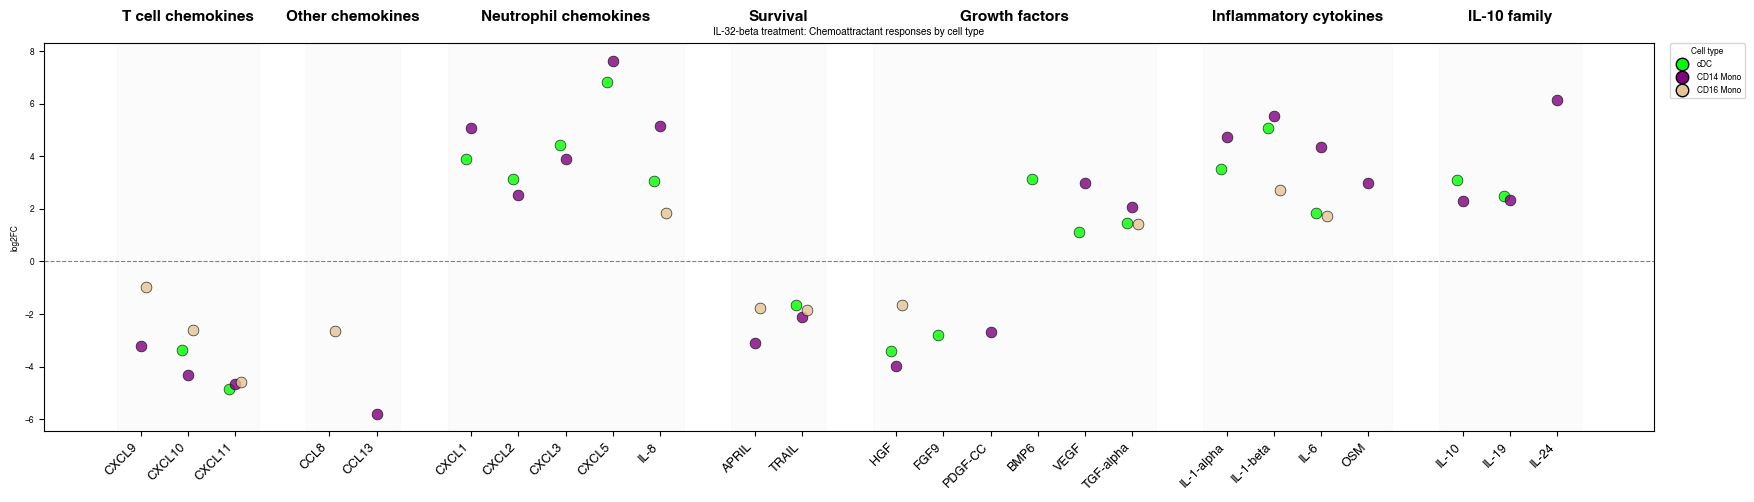

In [137]:
# shift from Th1-immunity to innate immunity/neutrophil recruitment

other_chemoattractants = ['CCL8', 'CCL13']
t_cell_chemoattractant = ['CXCL9', 'CXCL10', 'CXCL11']
survival = ['APRIL', 'TRAIL']
growth_factors = ['HGF', 'FGF9', "PDGF-CC", "BMP6", "VEGF", "TGF-alpha"]
inflammatory_cytokines = ["IL-1-alpha", "IL-1-beta", "IL-6", "OSM"]
neutrophil_chemokines = ["CXCL1", "CXCL2", "CXCL3", "CXCL5", "IL-8"]
il10_family = ["IL-10", "IL-19", "IL-24"]

# Define response categories
response_categories = {
    "T cell chemokines": t_cell_chemoattractant,
    "Other chemokines": other_chemoattractants,
    "Neutrophil chemokines": neutrophil_chemokines,   
    "Survival": survival,
    "Growth factors": growth_factors,
    "Inflammatory cytokines": inflammatory_cytokines,
    "IL-10 family": il10_family,
}

# Map each response to its category
response_to_category = {}
for cat, responses in response_categories.items():
    for resp in responses:
        response_to_category[resp] = cat

# Filter IL32b_treatment to only those responses in our categories
plot_df = IL32b_treatment[IL32b_treatment['response'].isin(response_to_category.keys())].copy()
plot_df['category'] = plot_df['response'].map(response_to_category)

# Get unique cell types and assign colors
cell_types = ['cDC', 'CD14 Mono', 'CD16 Mono'] #plot_df['cell_type'].unique()
colors = plt.cm.tab10.colors if len(cell_types) <= 10 else plt.cm.tab20.colors
cell_type_to_color = {ct: CELL_TYPE_COLORS[ct] for i, ct in enumerate(cell_types)}

# Prepare x axis: one for each response, grouped by category
category_order = list(response_categories.keys())
response_order = []
response_to_x = {}
x_tick_labels = []
x_tick_positions = []
x_pos = 0
for cat in category_order:
    responses = response_categories[cat]
    for resp in responses:
        response_order.append(resp)
        response_to_x[resp] = x_pos
        x_tick_labels.append(resp)
        x_tick_positions.append(x_pos)
        x_pos += 1
    # Add a gap between categories
    x_pos += 1

# Plot
plt.figure(figsize=(max(7, len(x_tick_labels)*0.7), 5))
offset_width = 0.12  # how much to offset each cell type

for i, ct in enumerate(cell_types):
    ct_df = plot_df[plot_df['cell_type'] == ct]
    for resp in ct_df['response'].unique():
        resp_df = ct_df[ct_df['response'] == resp]
        x = response_to_x[resp] + (i - (len(cell_types)-1)/2)*offset_width
        plt.scatter(
            np.full(len(resp_df), x),
            resp_df['single_fc'],
            color=cell_type_to_color[ct],
            label=ct if resp == ct_df['response'].unique()[0] else "",
            alpha=0.8,
            s=60,
            edgecolor='black',
            linewidth=0.5
        )

plt.axhline(0, color='gray', linestyle='--', linewidth=0.8, zorder=0)

# Draw category labels
category_centers = []
category_labels = []
last = 0
for cat in category_order:
    responses = response_categories[cat]
    if len(responses) == 0:
        continue
    first_x = response_to_x[responses[0]]
    last_x = response_to_x[responses[-1]]
    center = (first_x + last_x) / 2
    category_centers.append(center)
    category_labels.append(cat)
    # Optionally, shade background for each category
    plt.axvspan(first_x-0.5, last_x+0.5, color='lightgrey', alpha=0.08, zorder=-1)

plt.xticks(x_tick_positions, x_tick_labels, rotation=45, ha='right', fontsize=9)
plt.ylabel("log2FC")
plt.title("IL-32-beta treatment: Chemoattractant responses by cell type")

# Add category labels above the x-axis
for center, label in zip(category_centers, category_labels):
    plt.text(center, plt.ylim()[1] + 0.05*(plt.ylim()[1]-plt.ylim()[0]), label,
             ha='center', va='bottom', fontsize=11, fontweight='bold', color='black')

# Legend (one entry per cell type)
handles = [plt.Line2D([0], [0], marker='o', color='w', label=ct,
                      markerfacecolor=cell_type_to_color[ct], markersize=9, markeredgecolor='black')
           for ct in cell_types]
plt.legend(handles=handles, title="Cell type", bbox_to_anchor=(1.01, 1), loc='upper left', borderaxespad=0.)

plt.tight_layout()
plt.show()

#### Overview barplots

c:\Users\loesi\Dropbox\parse_pbmc data\HumanCytokineDict\code_lukas\unicode_utils.py:151: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

c:\Users\loesi\Dropbox\parse_pbmc data\HumanCytokineDict\code_lukas\unicode_utils.py:155: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

c:\Users\loesi\Dropbox\parse_pbmc data\HumanCytokineDict\code_lukas\unicode_utils.py:151: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

c:\Users\loesi\Dropbox\parse_pbmc data\HumanCytokineDict\code_lukas\unicode_utils.py:155: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.



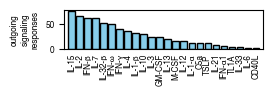

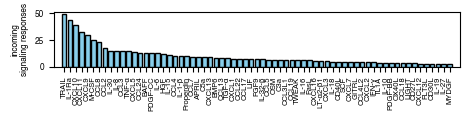

In [138]:
# Look at significant responses (positive and negative)
cytokine_response_df_all_current = cytokine_response_df_all[cytokine_response_df_all["direction"].isin(["upregulated", "downregulated"])]

# only plot those with at least 3 responses
treatment_counts = cytokine_response_df_all_current["treatment"].value_counts()
treatment_counts = treatment_counts[treatment_counts > 4]
response_counts = cytokine_response_df_all_current["response"].value_counts()
response_counts = response_counts[response_counts > 4]

plt.figure(figsize=cm_to_inches((7, 2.4)))
plt.bar(treatment_counts.index, treatment_counts.values, color='skyblue', edgecolor='black')
plt.xticks(rotation=90)
plt.ylabel('outgoing\nsignaling\nresponses')
apply_greek_labels_heatmap(plt.gca())

# Adjust margins to reduce whitespace
plt.margins(x=0.02)
plt.xticks(fontsize=5.9)
# Set ticklength to 0
plt.tick_params(axis='x', which='both', length=0)
#plt.tick_params(axis='y', which='both', length=0)


plt.tight_layout()
plt.savefig(os.path.join(plot_folder, "5.1_stimulation_counts.svg"), bbox_inches="tight")

plt.figure(figsize=cm_to_inches((12, 3)))
plt.bar(response_counts.index, response_counts.values, color='skyblue', edgecolor='black')
plt.xticks(rotation=90)
plt.ylabel('incoming\nsignaling responses')
apply_greek_labels_heatmap(plt.gca())

# Adjust margins to reduce whitespace
plt.margins(x=0.02)
plt.xticks(fontsize=5.5)

plt.tight_layout()
plt.savefig(os.path.join(plot_folder, "5.1_response_counts.svg"), bbox_inches="tight")

## 5.2 - Cell type - cell type communication

In [139]:
plot_folder = os.path.join(base_plot_folder, "5.2_cell_cell_communication")
os.makedirs(plot_folder, exist_ok=True)

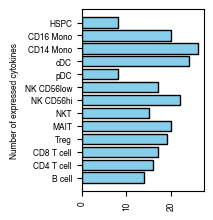

In [140]:
# Get number of expressed tested cytokines for each cell type
num_cytokines = {cell_type: len(cytokines) for cell_type, cytokines in expressed_cytokines_by_cell_type_parse.items()}
num_cytokines = pd.Series(num_cytokines)[ALL_CELL_TYPES]

plt.figure(figsize=cm_to_inches((4,6)))
plt.barh(num_cytokines.index, num_cytokines.values, color='skyblue', edgecolor='black')
plt.xticks(rotation=90)
plt.ylabel('Number of expressed cytokines')
plt.show()

In [141]:
cell_type_secretion_df = pd.DataFrame(columns=["origin_cell_type", "secretion"])
for origin_cell_type, expressed_cytokines in expressed_cytokines_by_cell_type_parse.items():
    for cytokine in expressed_cytokines:
        cell_type_secretion_df = pd.concat([cell_type_secretion_df,
                                            pd.DataFrame({"origin_cell_type": origin_cell_type, "secretion": cytokine}, index=[0])], axis=0)

In [142]:
# get strong impact cytokines by cell type
all_normalized_distances_high = strong_impact_by_cell_type.copy()
all_normalized_distances_high["cytokine"] = all_normalized_distances_high.index
all_normalized_distances_high = all_normalized_distances_high.melt(id_vars="cytokine", var_name="cell_type", value_name="significant")
all_normalized_distances_high = all_normalized_distances_high[all_normalized_distances_high["significant"]]

In [143]:
secretion_to_response_df = pd.DataFrame(columns=["origin_cell_type", "secretion", "response_cell_type"])
for index, row in cell_type_secretion_df.iterrows():
    secretion = row["secretion"]
    response_cell_types = all_normalized_distances_high[all_normalized_distances_high["cytokine"] == secretion]
    for index, response_row in response_cell_types.iterrows():
        secretion_to_response_df = pd.concat([secretion_to_response_df,
                                              pd.DataFrame({"origin_cell_type": row["origin_cell_type"], "secretion": secretion, "response_cell_type": response_row["cell_type"]}, index=[0])], axis=0)
secretion_to_response_df = secretion_to_response_df.reset_index(drop=True)

In [144]:
secretion_to_response_df['mean_expression'] = None
secretion_to_response_df['max_expression'] = None
secretion_to_response_df['maximal_treatment'] = None
secretion_to_response_df['response_magnitude'] = None

for index, row in secretion_to_response_df.iterrows():
    condition_for_max = cytokine_expression_df_all_details.loc[(row["origin_cell_type"], slice(None)), row["secretion"]]
    condition_for_max = condition_for_max[row["origin_cell_type"]].sort_values(ascending=False).index[0]
    secretion_to_response_df.loc[index, 'maximal_treatment'] = condition_for_max
    secretion_to_response_df.loc[index, 'mean_expression'] = cytokine_expression_df_mean.loc[row["origin_cell_type"], row["secretion"]]
    secretion_to_response_df.loc[index, 'max_expression'] = cytokine_expression_df_max.loc[row["origin_cell_type"], row["secretion"]]
    secretion_to_response_df.loc[index, 'response_magnitude'] = all_normalized_distances_mean.loc[row['secretion'], row['response_cell_type']]

In [145]:
# save the dataframe
secretion_to_response_df.to_csv(os.path.join(output_tables_folder, "Table_4.1_cell_cell_communication_df.csv"), index=False)

In [146]:
secretion_order = CYTOKINE_ORDER
secretion_order = [introduce_greek_letters(secretion) for secretion in secretion_order]

secretion_to_response_df["secretion"] = secretion_to_response_df["secretion"].apply(lambda x: introduce_greek_letters(x))
cell_type_order = ALL_CELL_TYPES

# now, do this separately for every cytokine
for cell_type in secretion_to_response_df["origin_cell_type"].unique():
    current_df = secretion_to_response_df[secretion_to_response_df["origin_cell_type"] == cell_type]
    column1_name = "origin_cell_type"
    column2_name = "secretion"
    column3_name = "response_cell_type"
    fig = create_sankey_diagram(
        df=current_df,
        column1_name=column1_name,
        column1_order=cell_type_order,
        column2_name=column2_name,
        column2_order=secretion_order,
        column3_name=column3_name,
        column3_order=cell_type_order,
        color1 = "rgba(31, 119, 180, 0.8)",
        color2 = "rgba(44, 160, 44, 0.8)", 
        color3 = "rgba(31, 119, 180, 0.8)",
        title=None
    )

    fig.write_image(os.path.join(plot_folder, f"5.2_cell_type_{unidecode(cell_type)}_secretes.svg"), engine="kaleido", scale=1)
    fig.write_image(os.path.join(plot_folder, f"5.2_cell_type_{unidecode(cell_type)}_secretes.png"), engine="kaleido", scale=4)

In [147]:
secretion_connection_counts = secretion_to_response_df.groupby(["origin_cell_type", "response_cell_type"]).size()
secretion_connection_counts = secretion_connection_counts.to_frame().reset_index().pivot(index="origin_cell_type", columns="response_cell_type", values=0)
secretion_connection_counts = secretion_connection_counts.loc[ALL_CELL_TYPES_EXCLUDE, ALL_CELL_TYPES_EXCLUDE]

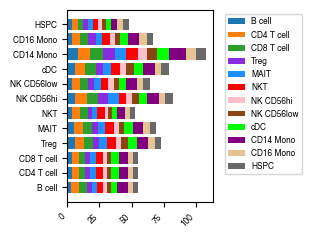

In [148]:
cell_cell_signaling_counts = secretion_to_response_df.groupby("origin_cell_type")["response_cell_type"].value_counts().unstack().fillna(0)
cell_cell_signaling_counts = cell_cell_signaling_counts.loc[ALL_CELL_TYPES_EXCLUDE, ALL_CELL_TYPES_EXCLUDE]

# Plot the stacked vertical bar graph using matplotlib
fig, ax = plt.subplots(figsize=cm_to_inches((8, 6)))

# Plot each cell type as a separate bar segment
bottom = np.zeros(len(cell_cell_signaling_counts.index))
for cell_type in cell_cell_signaling_counts.columns:
    ax.barh(cell_cell_signaling_counts.index, cell_cell_signaling_counts[cell_type], 
           left=bottom, label=cell_type, color=CELL_TYPE_COLORS.get(cell_type, 'gray'))
    bottom += cell_cell_signaling_counts[cell_type]

# Add labels and title
ax.set_xlabel('')
ax.set_ylabel('')
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45, ha='right')
# plt.xlim(0, 15)
plt.tight_layout()

# Show the plot
for format in ["png", "svg"]:
    plt.savefig(os.path.join(plot_folder, f"5.2_cell_cell_communication_counts.{format}"), dpi=300)

#### get a more granular look at response strengths

In [149]:
# get cytokines with at least one strong response
some_strong_effect = strong_impact_by_cell_type.apply(lambda row: any(row), axis=1)
some_strong_effect = some_strong_effect[some_strong_effect].index

# subset the cytokine expression to that
cytokine_expression_df_rel_reorganized = cytokine_expression_df_rel.T[ALL_CELL_TYPES_EXCLUDE]
cytokine_expression_df_rel_reorganized = cytokine_expression_df_rel_reorganized[cytokine_expression_df_rel_reorganized.index.isin(some_strong_effect)]
all_distances_mean_reorganized = all_normalized_distances_mean.loc[cytokine_expression_df_rel_reorganized.index, ALL_CELL_TYPES_EXCLUDE]

In [150]:
df1 = cytokine_expression_df_rel_reorganized.reset_index().melt(id_vars="index").rename(columns={"index": "gene", "value": "value_sender", "cell_type": "cell_type_sender"})
df2 = all_distances_mean_reorganized.reset_index().melt(id_vars="index").rename(columns={"index": "gene", "value": "value_receiver", "variable": "cell_type_receiver"})

merged_df = df1.merge(
    df2,
    on='gene',
    how='inner'
)

In [151]:
merged_df["score"] = merged_df["value_sender"] * merged_df["value_receiver"]

<Axes: >

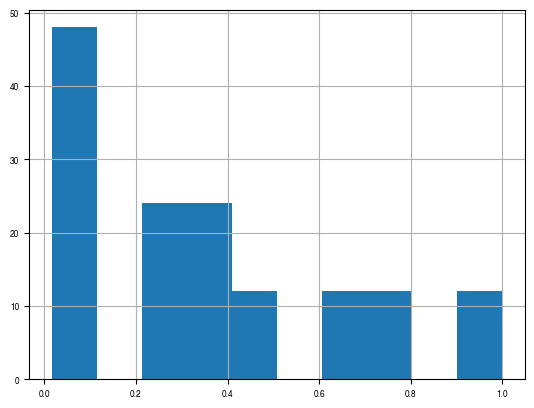

In [152]:
merged_df[merged_df["gene"] == "IL-32-beta"]["value_sender"].hist()

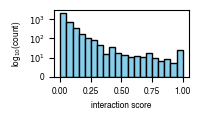

In [153]:
plt.figure(figsize=cm_to_inches((5,3)))
# Calculate histogram data manually
hist_data, bin_edges = np.histogram(merged_df["score"], bins=np.arange(0,1.05,0.05))
# Apply log transformation to counts (adding 1 to avoid log(0))
log_hist_data = np.log10(hist_data + 1)
# Plot as bar chart
plt.bar(bin_edges[:-1], log_hist_data, width=0.05, align='edge', color="skyblue", edgecolor="black")
# Create custom y-ticks for log scale
yticks = [0, 1, 2, 3]
plt.yticks(yticks, [f"$10^{i}$" if i > 0 else "0" for i in yticks])
plt.xlabel("interaction score")
plt.ylabel(r"log$_{10}$(count)")
plt.tight_layout()
for format in ["png", "svg"]:
    plt.savefig(os.path.join(plot_folder, f"5.2_interaction_strength_histogram.{format}"), dpi=400)

In [154]:
cell_type_communication_strength = merged_df.groupby(["cell_type_sender", "cell_type_receiver"])["score"].sum()
cell_type_communication_strength = cell_type_communication_strength.to_frame().reset_index().pivot(
    index="cell_type_sender",
    columns="cell_type_receiver",
    values="score")
cell_type_communication_strength = cell_type_communication_strength.loc[ALL_CELL_TYPES_EXCLUDE, ALL_CELL_TYPES_EXCLUDE]

Text(0.3285214348206438, 0.5, 'sender cell type')

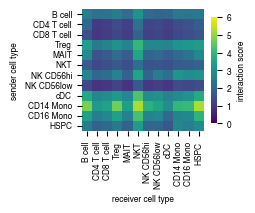

In [155]:
fig, ax = plt.subplots(figsize=cm_to_inches((5, 5)))
sns.heatmap(cell_type_communication_strength, vmin=0, vmax=6, cmap="viridis", ax=ax, square=True,
    cbar_kws={"label": "interaction score", "shrink": 0.7})
ax.set_xlabel("receiver cell type")
ax.set_ylabel("sender cell type")

In [156]:
merged_df["gene"] = merged_df["gene"].apply(introduce_greek_letters)

In [157]:
# Sort merged_df by score within each unique_pair
merged_df["unique_pair"] = merged_df["cell_type_sender"] + "-" + merged_df["cell_type_receiver"]
merged_df = merged_df.sort_values(by=["unique_pair", "score"], ascending=[True, False])

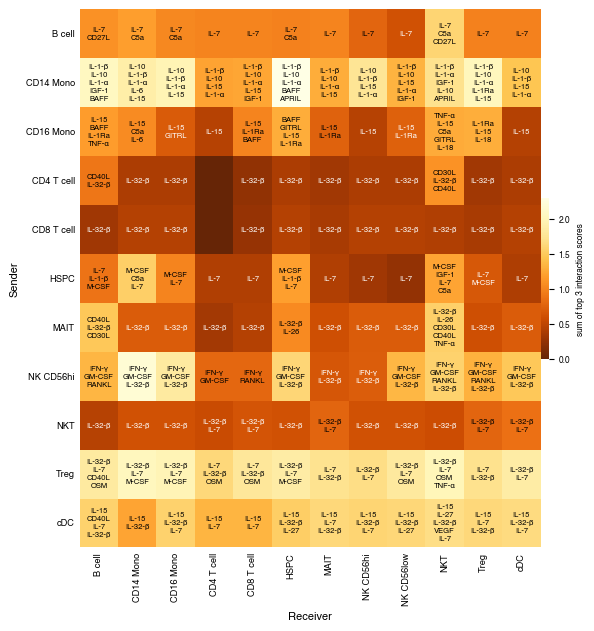

In [158]:
def smart_join(gene_series, max_list_length=5):
    # Convert pandas Series to list of genes
    genes = list(gene_series)
    
    if not len(genes):
        return ""
    
    max_line_length = 5  # adjust this threshold as needed
    current_line = []
    current_length = 0
    all_lines = []
    
    for gene in genes[:max_list_length]:
        # Calculate length if we add this gene (including comma and space)
        additional_length = len(gene) + (2 if current_line else 0)  # +2 for ", "
        
        # If adding this gene would exceed threshold
        if current_line and (current_length + additional_length > max_line_length):
            # Store current line and start new one
            all_lines.append(", ".join(current_line))
            current_line = [gene]
            current_length = len(gene)
        else:
            # Add to current line
            current_line.append(gene)
            current_length += additional_length
    
    # Don't forget the last line
    if current_line:
        all_lines.append(", ".join(current_line))
    
    return "\n".join(all_lines)

def top_3_sum(score_series):
    return score_series.iloc[:3].sum()

score_cutoff = 0.25

# First, get unique genes for each sender-receiver pair that pass the cutoff
interaction_genes = merged_df[merged_df["score"] > score_cutoff].groupby(
    ["cell_type_sender", "cell_type_receiver"]
)["gene"].agg(lambda x: smart_join(x)).reset_index()

# Create a pivot table for the scores (will be used for color intensity)
score_matrix = merged_df[merged_df["score"] > score_cutoff].groupby(
    ["cell_type_sender", "cell_type_receiver"]
)["score"].agg(lambda x: top_3_sum(x)).reset_index()
score_pivot = score_matrix.pivot(
    index="cell_type_sender", 
    columns="cell_type_receiver", 
    values="score"
)
score_pivot = score_pivot.fillna(0)

# Create the plot
plt.figure(figsize=cm_to_inches((16, 16)))
ax = plt.gca()

# Create a heatmap with empty cells (just for the grid)
sns.heatmap(score_pivot, cmap='YlOrBr_r', annot=False,
    cbar_kws={'label': 'sum of top 3 interaction scores', 'shrink': 0.3, 'pad': 0})

# Add text annotations with padding
for sender in score_pivot.index:
    for receiver in score_pivot.columns:
        genes = interaction_genes[
            (interaction_genes["cell_type_sender"] == sender) & 
            (interaction_genes["cell_type_receiver"] == receiver)
        ]["gene"].values
        
        if len(genes) > 0:
            text = genes[0] if len(genes) > 0 else ""
            score = score_pivot.loc[sender, receiver]
            alpha = min(score / score_cutoff, 1.0) if pd.notnull(score) else 0.3
            
            # Add text with adjusted position and smaller size
            plt.text(
                score_pivot.columns.get_loc(receiver) + 0.5,  # x position (center)
                score_pivot.index.get_loc(sender) + 0.5,      # y position (center)
                text,
                color='black' if score > 0.75 else "white",
                ha='center',
                va='center',
                alpha=alpha,
                fontsize=5.5,
                bbox=dict(
                    pad=3,          # Padding between text and bbox
                    facecolor='none',  # Transparent background
                    edgecolor='none',  # No edge
                    alpha=0          # Fully transparent
                ),
                wrap=True           # Enable text wrapping
            )

# Set all tick lengths to 0
plt.tick_params(axis='both', which='both', length=0)

# Also set tick lengths to 0 for the current axes
ax.tick_params(axis='both', which='both', length=0)

# Rotate x-axis labels for better readability
plt.xticks(rotation=90, fontsize=6.7)
plt.yticks(rotation=0, fontsize=6.7)

plt.xlabel("Receiver", fontsize=8)
plt.ylabel("Sender", fontsize=8)

plt.tight_layout()
for format in ["png", "svg"]:
    plt.savefig(os.path.join(plot_folder, f"5.2_detailed_cell_cell_interactions.{format}"), dpi=300)

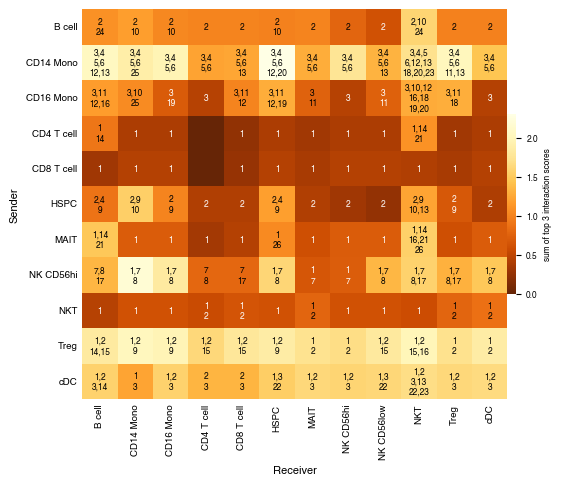

In [159]:
cytokine_to_number = {cytokine: i+1 for i, cytokine in enumerate(merged_df[merged_df["score"] > score_cutoff]["gene"].value_counts().index)}
number_to_cytokine = {str(val): key for key, val in cytokine_to_number.items()}
def smart_join(gene_series):
    # Convert pandas Series to list of genes
    genes = list(gene_series)
    if not genes:
        return ""
    
    # Map and sort the genes
    genes = [cytokine_to_number[gene] for gene in genes]
    genes = sorted(genes)
    genes = [str(gene) for gene in genes]
    
    n = len(genes)
    # For 1 gene, just return it.
    if n == 1:
        return genes[0]
    
    # Use 2 rows if there are 2-4 entries, otherwise 3 rows.
    rows = 2 if n <= 4 else 3
    
    # Determine how many items go in each row as evenly as possible.
    base = n // rows
    remainder = n % rows
    result_lines = []
    start = 0
    
    for i in range(rows):
        # Give the first 'remainder' rows one extra item.
        count = base + (1 if i < remainder else 0)
        if count == 0:
            continue
        line = ",".join(genes[start:start + count])
        result_lines.append(line)
        start += count
    
    return "\n".join(result_lines)

def top_3_sum(score_series):
    return score_series.iloc[:3].sum()

score_cutoff = 0.25

# First, get unique genes for each sender-receiver pair that pass the cutoff
interaction_genes = merged_df[merged_df["score"] > score_cutoff].groupby(
    ["cell_type_sender", "cell_type_receiver"]
)["gene"].agg(lambda x: smart_join(x)).reset_index()

# Create a pivot table for the scores (will be used for color intensity)
score_matrix = merged_df[merged_df["score"] > score_cutoff].groupby(
    ["cell_type_sender", "cell_type_receiver"]
)["score"].agg(lambda x: top_3_sum(x)).reset_index()
score_pivot = score_matrix.pivot(
    index="cell_type_sender", 
    columns="cell_type_receiver", 
    values="score"
)
score_pivot = score_pivot.fillna(0)

# Create the plot
plt.figure(figsize=cm_to_inches((15, 16)))
ax = plt.gca()

# Create a heatmap with empty cells (just for the grid)
sns.heatmap(score_pivot, cmap='YlOrBr_r', annot=False,  square=True,
    cbar_kws={'label': 'sum of top 3 interaction scores', 'shrink': 0.3, 'pad': 0})

# Add text annotations with padding
for sender in score_pivot.index:
    for receiver in score_pivot.columns:
        genes = interaction_genes[
            (interaction_genes["cell_type_sender"] == sender) & 
            (interaction_genes["cell_type_receiver"] == receiver)
        ]["gene"].values
        
        if len(genes) > 0:
            text = genes[0] if len(genes) > 0 else ""
            score = score_pivot.loc[sender, receiver]
            alpha = min(score / score_cutoff, 1.0) if pd.notnull(score) else 0.3
            
            # Add text with adjusted position and smaller size
            plt.text(
                score_pivot.columns.get_loc(receiver) + 0.5,  # x position (center)
                score_pivot.index.get_loc(sender) + 0.5,      # y position (center)
                text,
                color='black' if score > 0.75 else "white",
                ha='center',
                va='center',
                alpha=alpha,
                fontsize=6,
                bbox=dict(
                    pad=3,          # Padding between text and bbox
                    facecolor='none',  # Transparent background
                    edgecolor='none',  # No edge
                    alpha=0          # Fully transparent
                ),
                wrap=True           # Enable text wrapping
            )

# Set all tick lengths to 0
plt.tick_params(axis='both', which='both', length=0)

# Also set tick lengths to 0 for the current axes
ax.tick_params(axis='both', which='both', length=0)

# Rotate x-axis labels for better readability
plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=7)

plt.xlabel("Receiver", fontsize=8)
plt.ylabel("Sender", fontsize=8)

plt.tight_layout()
for format in ["png", "svg"]:
    plt.savefig(os.path.join(plot_folder, f"5.2_detailed_cell_cell_interactions_alt.{format}"), dpi=300)

In [160]:
import svgwrite

# Parameters for the SVG drawing
font_size = 7
line_height = 10
margin_top = 5
margin_left = 10
col_spacing = 25  # distance between the two columns

# Calculate SVG dimensions based on the number of items
num_items = len(number_to_cytokine)
width = (margin_left * 2 + col_spacing + 80)*0.5  # extra space for value text
height = (margin_top * 2 + num_items * line_height)*0.5

# Create an SVG drawing
dwg = svgwrite.Drawing(os.path.join(plot_folder, '5.2_number_cytokine_association.svg'), size=(width, height))

# Optional: Add a title
dwg.add(dwg.text("Cytokine Associations", insert=(margin_left, margin_top - 5),
                  font_size=font_size + 2, fill='black', font_weight="bold"))

# Draw each dictionary entry in two columns
for idx, (value, cytokine) in enumerate(number_to_cytokine.items()):
    y = margin_top + idx * line_height
    dwg.add(dwg.text(value + ": ",
                     insert=(margin_left, y),
                     font_size=font_size,
                     fill='black'))
    dwg.add(dwg.text(cytokine,
                     insert=(margin_left + col_spacing, y),
                     font_size=font_size,
                     fill='black',
                     text_anchor="start"))
    
# Save the SVG file
dwg.save()

In [161]:
# Create a pivot table for the scores (will be used for color intensity)
score_matrix = merged_df[merged_df["score"] > score_cutoff].groupby(
    ["cell_type_sender", "cell_type_receiver"]
)["score"].agg(lambda x: top_3_sum(x)).reset_index()
score_pivot = score_matrix.pivot(
    index="cell_type_sender", 
    columns="cell_type_receiver", 
    values="score"
)

score_matrix = score_matrix[score_matrix["score"] > 0.4]

In [162]:
# Calculate max and min connection strength for each sender cell type
max_values = score_matrix.groupby("cell_type_sender")["score"].max().reset_index()
min_values = score_matrix.groupby("cell_type_sender")["score"].min().reset_index()

# Merge the max and min values back to the original dataframe
score_matrix = score_matrix.merge(max_values, on="cell_type_sender", suffixes=("", "_max"))
score_matrix = score_matrix.merge(min_values, on="cell_type_sender", suffixes=("", "_min"))

In [163]:
score_matrix["connection_strength"] = score_matrix["score"] / score_matrix["score_max"]

In [164]:
import matplotlib.colors as mcolors


def to_int_rgb(rgb_tuple):
    return tuple(int(255 * comp) for comp in rgb_tuple)

int_rgb = {name: to_int_rgb(mcolors.to_rgb(val)) for name, val in CELL_TYPE_COLORS.items()}

print("\nInteger RGB values:")
print(int_rgb)


Integer RGB values:
{'B cell': (31, 119, 180), 'CD4 T cell': (255, 127, 14), 'CD8 T cell': (44, 160, 44), 'Treg': (138, 43, 226), 'MAIT': (30, 144, 255), 'NKT': (255, 0, 0), 'NK CD56hi': (255, 192, 203), 'NK CD56low': (139, 69, 19), 'pDC': (255, 20, 147), 'cDC': (0, 255, 0), 'CD14 Mono': (128, 0, 128), 'CD16 Mono': (229, 196, 148), 'HSPC': (105, 105, 105)}


In [165]:
def tuple_to_rgba_string(color):
    if isinstance(color, str):
        return color
    color = f"rgba({color[0]}, {color[1]}, {color[2]}, 0.8)"
    return color

def create_sankey_diagram_two_column(df, column1_name=None, column1_order=None, column2_name=None, column2_order=None,
                          strength_column=None, color1 = "rgba(31, 119, 180, 0.8)", color2 = "rgba(44, 160, 44, 0.8)", 
                          link_color_scheme = (31, 119, 180),
                          title="Cytokine crosstalk between treatments and responses"):
    """
    Create a Sankey diagram with two columns and connection strengths.
    
    Parameters:
    df: pandas DataFrame with three columns: two entity columns and one strength column
    column1_name: name of the first column
    column1_order: list of column1 names in desired order (optional)
    column2_name: name of the second column
    column2_order: list of column2 names in desired order (optional)
    color1: color for first column (can be string or dict mapping values to colors)
    color2: color for second column (can be string or dict mapping values to colors)
    title: title of the diagram
    """
    
    # Get order of values in the columns
    column1_values = pd.unique(df[column1_name]).tolist()
    column2_values = pd.unique(df[column2_name]).tolist()
    
    if column1_order is not None:
        # Ensure that all nodes in the DataFrame are included in the order;
        # otherwise, raise an error.
        extra = set(df[column1_name].unique()) - set(column1_order)
        if extra:
            raise ValueError(f"Column1 order missing values for: {extra}")
        column1_values = column1_order  # use the full provided order even if some nodes are absent from df
        
    if column2_order is not None:
        # Ensure that all nodes in the DataFrame are included in the order;
        # otherwise, raise an error.
        extra = set(df[column2_name].unique()) - set(column2_order)
        if extra:
            raise ValueError(f"Column1 order missing values for: {extra}")
        column2_values = column2_order  # use the full provided order even if some nodes are absent from df
        
    # Create mapping dictionaries with ordered indices
    column1_to_idx = {t: idx for idx, t in enumerate(column1_values)}
    column2_to_idx = {c: idx + len(column1_values) for idx, c in enumerate(column2_values)}
    
    # Calculate link values while preserving order
    links = []
    
    # Get all strength values for normalization
    all_strengths = df[strength_column].values
    min_strength = all_strengths.min()
    max_strength = all_strengths.max()

    for t in column1_values:
        for c in column2_values:
            strength = df[(df[column1_name] == t) & (df[column2_name] == c)][strength_column].values
            if len(strength) > 0:
                # Normalize strength to opacity range [0.1, 0.8]
                normalized_strength = (strength[0] - min_strength) / (max_strength - min_strength)
                opacity = 0.1 + (0.9 * normalized_strength)  # Scale to [0.2, 1.0]
                
                links.append({
                    'source_label': t,
                    'source': column1_to_idx[t],
                    'target': column2_to_idx[c],
                    'value': strength[0],
                    'opacity': opacity
                })

    # -------------------------------------- DUMMY -------------------------------------------
    # Define a minimum dummy value (adjust as needed)
    dummy_value = 1
    # Keep track of dummy links
    dummy_links = []
    # Find column1 nodes with no outgoing links (using the original links list)
    for t in column1_values:
        # If this node never appears as a source in any link, it is isolated.
        if not any(link['source_label'] == t for link in links):
            # Create a dummy target label that will serve as a hidden node.
            dummy_target_label = column2_values[3]
            # Append the dummy node to column2_values.
            #column2_values.append(dummy_target_label)
            # Update mapping for the new dummy node:
            #column2_to_idx[dummy_target_label] = len(column1_values) + len(column2_values) - 1
            # Add a dummy link with minimal value and invisible opacity.
            dummy_links.append({
                'source_label': t,
                'source': column1_to_idx[t],
                'target': column2_to_idx[dummy_target_label],
                'value': dummy_value,
                'opacity': 0.0  # this link will be invisible
            })
    # Add the dummy links to the main links list
    links.extend(dummy_links)
    # -------------------------------------- DUMMY -------------------------------------------

    # Extract sources, targets, values and opacities from links
    sources = [link['source'] for link in links]
    targets = [link['target'] for link in links]
    values = [link['value'] for link in links]
    opacities = [link['opacity'] for link in links]

    # Handle colors (either string or dictionary)
    if isinstance(color1, dict):
        colors_column1 = [tuple_to_rgba_string(color1.get(val, "rgba(31, 119, 180, 0.8)")) for val in column1_values]
    else:
        colors_column1 = [color1] * len(column1_values)
        
    if isinstance(color2, dict):
        colors_column2 = [tuple_to_rgba_string(color2.get(val, "rgba(44, 160, 44, 0.8)"))
                          for val in column2_values]
    else:
        colors_column2 = [color2] * len(column2_values)

    # Combine colors for all nodes
    colors = colors_column1 + colors_column2
    
    # Create node labels in the correct order # column1_values + [ # "" if lbl.startswith("dummy_") else lbl for lbl in column2_values
    display_labels = [
        "" for lbl in column1_values
    ] + [
        "" for lbl in column2_values
    ]
    
    # Calculate node positions
    x_positions = [0.05] * len(column1_values) + [0.95] * len(column2_values)
    
    # Create y positions that spread nodes evenly within their columns
    y_column1_values = np.linspace(0.05, 0.95, len(column1_values)) if len(column1_values) > 1 else [0.5]
    y_column2_values = np.linspace(0.05, 0.95, len(column2_values)) if len(column2_values) > 1 else [0.5]
    y_positions = list(y_column1_values) + list(y_column2_values)
    
    # Compute link colors using the computed opacity values
    if type(link_color_scheme) == tuple:
        link_colors_base = [link_color_scheme for link in links]
    else:
        link_colors_base = [link_color_scheme[link['source_label']] for link in links]
    
    link_colors = [f"rgba({base_link_color[0]}, {base_link_color[1]}, {base_link_color[2]}, {opac})" for base_link_color, opac in zip(link_colors_base, opacities)]

    # print(list(zip(x_positions, y_positions, display_labels)))
    
    # Create Sankey Diagram
    fig = go.Figure(data=[go.Sankey(
        node=dict(
            pad=5,
            thickness=10,
            line=dict(color='black', width=0.5),
            label=display_labels,
            color=colors,
            x=x_positions,
            y=y_positions,
        ),
            link=dict(
            source=sources,
            target=targets,
            value=values,
            hovertemplate='Source: %{source.label}<br>Target: %{target.label}<br>Strength: %{value}<extra></extra>',
            line=dict(color='rgba(0,0,0,0)', width=0),
            color=link_colors
        ),
        arrangement='fixed'
    )])
    
    # Dynamic height scaling and improved margins
    fig.update_layout(
        font_size=6,
        height=180,
        width=90,
        margin=dict(
            l=10,  # Left margin
            r=10,  # Right margin
            t=25,  # Top margin
            b=25   # Bottom margin to prevent cutoff
        ),
        showlegend=False,
        font=dict(color='black'),
        title=title
    )
    return fig

fig = create_sankey_diagram_two_column(
    score_matrix.copy(),
    column1_name="cell_type_sender",
    column1_order=ALL_CELL_TYPES_EXCLUDE.copy(),
    color1=int_rgb,
    column2_name="cell_type_receiver",
    column2_order=ALL_CELL_TYPES_EXCLUDE.copy(),
    color2=int_rgb, # color2 = "rgba(128, 128, 128, 0.8)",
    strength_column="connection_strength",
    link_color_scheme=int_rgb,
    title=None
)

fig.write_image(os.path.join(plot_folder, f"5.2_cell_cell_connection.svg"), engine="kaleido", scale=1)
fig.write_image(os.path.join(plot_folder, f"5.2_cell_cell_connection.png"), engine="kaleido", scale=4)

## 5.3 - Count regulation of cytokines from different families

In [166]:
plot_folder = os.path.join(base_plot_folder, "5.3_family_counts")
os.makedirs(plot_folder, exist_ok=True)

In [167]:
family_level = "level2"

if family_level == "level2":
    cytokine_response_df_all["family"] = cytokine_response_df_all["response"].map(cytokine_name_to_level_2_family)
elif family_level == "level1":
    cytokine_response_df_all["family"] = cytokine_response_df_all["response"].map(cytokine_name_to_level_1_family)
else:
    raise Exception("Invalid level choice!")

cytokine_response_df_all["response_plus_cell_type"] = cytokine_response_df_all["response"] + "_" + cytokine_response_df_all["cell_type"]

In [168]:
cytokine_response_df_all[cytokine_response_df_all['response'] == "CXCL9"]['treatment'].value_counts()

treatment
IL-2               6
IL-15              6
IFN-gamma          6
IL-7               6
IL-12              5
IL-1-beta          4
IFN-beta           4
IL-32-beta         3
IL-13              3
IL-10              3
IFN-omega          3
TL1A               2
Noggin             2
IL-3               2
IL-1-alpha         2
IFN-alpha1         2
IL-4               2
IL-33              2
EPO                1
LT-alpha2-beta1    1
GM-CSF             1
C5a                1
CD40L              1
IL-31              1
M-CSF              1
Name: count, dtype: int64

In [169]:
family_value_counts_positive = {}
for treatment in cytokine_response_df_all["treatment"].unique():
    response_df_filter = cytokine_response_df_all[cytokine_response_df_all["treatment"] == treatment]
    response_df_filter = response_df_filter[response_df_filter["fold_changes"].apply(lambda x: all(fc > 1 for fc in x))]

    # keep only one occurrence of each upregulated gene
    response_df_filter = response_df_filter.drop_duplicates(subset="response_plus_cell_type")
    # response_df_filter = response_df_filter.drop_duplicates(subset="response")
    family_value_counts_positive[treatment] = response_df_filter["family"].value_counts()
    
family_value_counts_positive = pd.DataFrame(family_value_counts_positive)
family_value_counts_positive.fillna(0, inplace=True)
# convert to int
family_value_counts_positive = family_value_counts_positive.astype(int)

family_value_counts_negative = {}
for treatment in cytokine_response_df_all["treatment"].unique():
    response_df_filter = cytokine_response_df_all[cytokine_response_df_all["treatment"] == treatment]
    response_df_filter = response_df_filter[response_df_filter["fold_changes"].apply(lambda x: all(fc < -1 for fc in x))]
    
    # keep only one occurrence of each downregulated gene
    response_df_filter = response_df_filter.drop_duplicates(subset="response_plus_cell_type")
    # response_df_filter = response_df_filter.drop_duplicates(subset="response")
    family_value_counts_negative[treatment] = response_df_filter["family"].value_counts()
    
family_value_counts_negative = pd.DataFrame(family_value_counts_negative)
family_value_counts_negative.fillna(0, inplace=True)
# convert to int
family_value_counts_negative = family_value_counts_negative.astype(int)

In [170]:
# inspect the results manually
subset = cytokine_response_df_all[cytokine_response_df_all["family"] == "IL-10"]
subset = subset[subset["direction"] == "upregulated"]
subset["treatment"].value_counts()

treatment
IL-32-beta    6
IL-4          1
IL-13         1
C5a           1
IL-21         1
Name: count, dtype: int64

In [171]:
# add 0 counts for all missing families
if family_level == "level2":
    family_value_counts_positive = family_value_counts_positive.reindex(cytokine_level_2_order, fill_value=0)
    family_value_counts_negative = family_value_counts_negative.reindex(cytokine_level_2_order, fill_value=0)
if family_level == "level1":
    family_value_counts_positive = family_value_counts_positive.reindex(cytokine_level_1_order, fill_value=0)
    family_value_counts_negative = family_value_counts_negative.reindex(cytokine_level_1_order, fill_value=0)

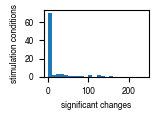

In [172]:
# total counts by cytokine treatment
total_significant_interactions_cytokine = family_value_counts_positive + family_value_counts_negative
total_significant_interactions_cytokine = total_significant_interactions_cytokine.sum(axis=0)

plt.figure(figsize=cm_to_inches((4, 3)))
plt.hist(total_significant_interactions_cytokine, bins=np.arange(0, 250, 10))
plt.xlabel("significant changes")
plt.ylabel("stimulation conditions")
plt.tight_layout()
plt.savefig(os.path.join(plot_folder, f"5.3_total_significant_interactions_cytokine.svg"), bbox_inches="tight")

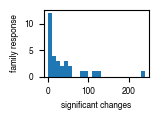

In [173]:
# total counts by cytokine response family
total_significant_interactions_family = family_value_counts_positive + family_value_counts_negative
total_significant_interactions_family = total_significant_interactions_family.sum(axis=1)

plt.figure(figsize=cm_to_inches((4, 3)))
plt.hist(total_significant_interactions_family, bins=np.arange(0, 250, 10))
plt.xlabel("significant changes")
plt.ylabel("family response")
plt.tight_layout()
plt.savefig(os.path.join(plot_folder, f"5.3_total_significant_interactions_family.svg"), bbox_inches="tight")

In [174]:
# load cytokine groupings and other things calculated later (run later parts of this notebook starting at "6-" first if necessary)
with open("output/6_highly_similar_groups.pkl", "rb") as f:
    highly_similar_groups = pickle.load(f)
with open("output/6_all_communities_cyto_cyto.pkl", "rb") as f:
    all_communities = pickle.load(f)
    all_communities_flat = [item for sublist in all_communities for item in sublist]

In [175]:
all_communities

[['IL-1-alpha',
  'IL-1-beta',
  'IL-2',
  'IL-7',
  'IL-15',
  'GM-CSF',
  'IL-27',
  'IL-12',
  'IFN-alpha1',
  'IFN-beta',
  'IFN-omega',
  'IFN-gamma'],
 ['OSM',
  'IL-17C',
  'IL-17A',
  'IFN-lambda1',
  'TNF-alpha',
  'CD27L',
  'RANKL',
  'G-CSF',
  'EGF',
  'IGF-1'],
 ['TSLP', 'IFN-lambda3', 'BAFF', 'TL1A', 'FGF-beta', 'Noggin'],
 ['IL-4', 'IL-13'],
 ['IL-1Ra'],
 ['IL-33'],
 ['IL-21'],
 ['IL-3'],
 ['IL-10'],
 ['IL-17D'],
 ['IFN-epsilon'],
 ['CD40L'],
 ['C5a'],
 ['IL-34'],
 ['M-CSF'],
 ['Leptin'],
 ['IL-32-beta']]

In [176]:
filter_cytokine_interactions = total_significant_interactions_cytokine[total_significant_interactions_cytokine > 3]
filter_family_interactions = total_significant_interactions_family[total_significant_interactions_family > 3]
family_value_counts_positive = family_value_counts_positive.loc[filter_family_interactions.index, filter_cytokine_interactions.index]
family_value_counts_negative = family_value_counts_negative.loc[filter_family_interactions.index, filter_cytokine_interactions.index]

# order columns by all_known_cytokine_and_chemokine_names
family_value_counts_positive = family_value_counts_positive.reindex(columns=[col for col in all_communities_flat if col in family_value_counts_positive.columns])
family_value_counts_negative = family_value_counts_negative.reindex(columns=[col for col in all_communities_flat if col in family_value_counts_negative.columns])
family_value_counts_both = family_value_counts_positive - family_value_counts_negative
family_value_counts_abs = family_value_counts_positive + family_value_counts_negative

family_value_counts_positive_rel = family_value_counts_positive.divide(family_value_counts_positive.max(axis=1), axis=0)
family_value_counts_negative_rel = family_value_counts_negative.divide(family_value_counts_negative.max(axis=1), axis=0)
family_value_counts_both_rel = family_value_counts_both.divide(abs(family_value_counts_both).max(axis=1), axis=0)

# subset the communities
all_communities_subset = []
for community in all_communities:
    all_communities_subset.append([c for c in community if c in family_value_counts_positive.columns])
highly_similar_groups_subset = []
for community in highly_similar_groups:
    highly_similar_groups_subset.append([c for c in community if c in family_value_counts_positive.columns])

In [177]:
# This is done to plot overview labels on the y-axis
counts_per_level1_family = {}
for level2_family in family_value_counts_positive_rel.index:
    level1_family = level2_to_level1.get(level2_family)
    if level1_family is not None:
        counts_per_level1_family[level1_family] = counts_per_level1_family.get(level1_family, 0) + 1
        
# invert the order of the dictionary
counts_per_level1_family = dict(reversed(counts_per_level1_family.items()))        

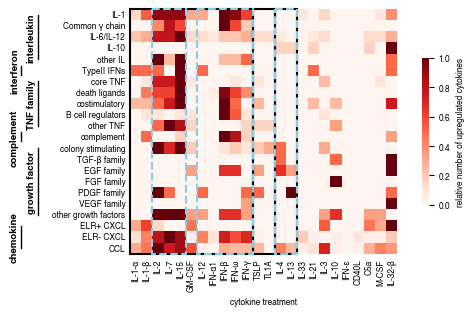

In [178]:
if family_level == "level2":
    fig = plt.figure(figsize=cm_to_inches((14, 8)))
else:
    fig = plt.figure(figsize=cm_to_inches((12, 10)))

ax = sns.heatmap(family_value_counts_positive_rel, vmin=0, vmax=1, cmap="Reds",
            cbar_kws={"label": "relative number of upregulated cytokines", "shrink": 0.6 if family_level == "level2" else 0.15}, square=True)

for community in all_communities_subset:
    if len(community) > 1:
        start = family_value_counts_positive_rel.columns.get_loc(community[0])
        end = family_value_counts_positive_rel.columns.get_loc(community[-1]) + 1
        ax.add_patch(plt.Rectangle((start, 0), end - start, len(family_value_counts_positive_rel.index), fill=False, edgecolor='black', linewidth=1.5, clip_on=False))

for group in highly_similar_groups_subset:
    if len(group) > 1:
        start = family_value_counts_positive_rel.columns.get_loc(group[0])
        end = family_value_counts_positive_rel.columns.get_loc(group[-1]) + 1
        ax.add_patch(plt.Rectangle((start, 0), end - start, len(family_value_counts_positive_rel.index), fill=False, edgecolor='skyblue', linewidth=1.5, ls="--", clip_on=False))

plot_overview_labels_along_y_axis(fig, ax, counts_per_level1_family.keys(),
                                  counts_per_level1_family, -10, len(family_value_counts_positive_rel.index), stagger=1.5)

plt.xlabel("cytokine treatment")
plt.ylabel("")
plt.gca().tick_params(axis='both', length=0)
apply_greek_labels_heatmap(plt.gca())
plt.tight_layout()
plt.savefig(os.path.join(plot_folder, f"5.3_family_value_counts_positive_{family_level}.svg"), bbox_inches="tight")

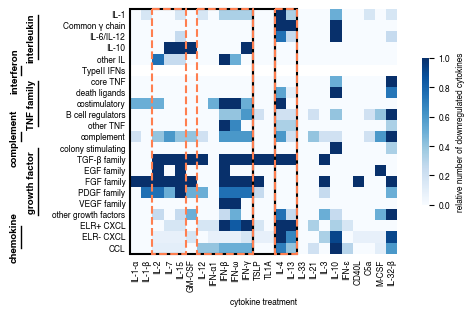

In [179]:
if family_level == "level2":
    fig = plt.figure(figsize=cm_to_inches((14, 8)))
else:
    fig = plt.figure(figsize=cm_to_inches((12, 10)))



ax = sns.heatmap(family_value_counts_negative_rel, vmin=0, vmax=1, cmap="Blues",
            cbar_kws={"label": "relative number of downregulated cytokines", "shrink": 0.6 if family_level == "level2" else 0.15}, square=True)


plot_overview_labels_along_y_axis(fig, ax, counts_per_level1_family.keys(),
                                  counts_per_level1_family, -10, len(family_value_counts_positive_rel.index), stagger=1.5)

for community in all_communities_subset:
    if len(community) > 1:
        start = family_value_counts_positive_rel.columns.get_loc(community[0])
        end = family_value_counts_positive_rel.columns.get_loc(community[-1]) + 1
        ax.add_patch(plt.Rectangle((start, 0), end - start, len(family_value_counts_positive_rel.index), fill=False, edgecolor='black', linewidth=1.5, clip_on=False))

for group in highly_similar_groups_subset:
    if len(group) > 1:
        start = family_value_counts_positive_rel.columns.get_loc(group[0])
        end = family_value_counts_positive_rel.columns.get_loc(group[-1]) + 1
        ax.add_patch(plt.Rectangle((start, 0), end - start, len(family_value_counts_positive_rel.index), fill=False, edgecolor='coral', linewidth=1.5, ls="--", clip_on=False))

plt.ylabel("")
apply_greek_labels_heatmap(plt.gca())

plt.xlabel("cytokine treatment")
plt.gca().tick_params(axis='both', length=0)

plt.tight_layout()
plt.savefig(os.path.join(plot_folder, f"5.3_family_value_counts_negative_{family_level}.svg"), bbox_inches="tight")


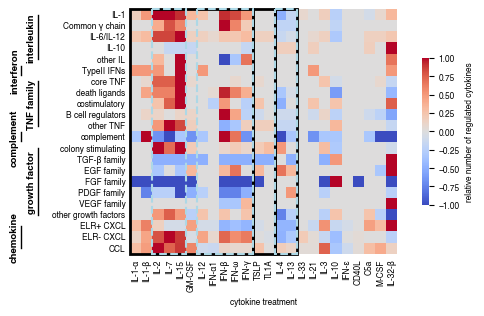

In [180]:
if family_level == "level2":
    fig = plt.figure(figsize=cm_to_inches((14, 8)))
else:
    fig = plt.figure(figsize=cm_to_inches((12, 10)))

df = family_value_counts_both_rel

ax = sns.heatmap(df, vmin=df.min().min(), vmax=df.max().max(), cmap="coolwarm",
            cbar_kws={"label": "relative number of regulated cytokines", "shrink": 0.6 if family_level == "level2" else 0.15}, square=True)


plot_overview_labels_along_y_axis(fig, ax, counts_per_level1_family.keys(),
                                  counts_per_level1_family, -10, len(family_value_counts_positive_rel.index), stagger=1.5)

for community in all_communities_subset:
    if len(community) > 1:
        start = family_value_counts_positive_rel.columns.get_loc(community[0])
        end = family_value_counts_positive_rel.columns.get_loc(community[-1]) + 1
        ax.add_patch(plt.Rectangle((start, 0), end - start, len(family_value_counts_positive_rel.index), fill=False, edgecolor='black', linewidth=2, clip_on=False))

for group in highly_similar_groups_subset:
    if len(group) > 1:
        start = family_value_counts_positive_rel.columns.get_loc(group[0])
        end = family_value_counts_positive_rel.columns.get_loc(group[-1]) + 1
        ax.add_patch(plt.Rectangle((start, 0), end - start, len(family_value_counts_positive_rel.index), fill=False, edgecolor='lightblue', linewidth=1.5, ls="--", clip_on=False))

plt.ylabel("")
apply_greek_labels_heatmap(plt.gca())

plt.xlabel("cytokine treatment")
plt.gca().tick_params(axis='both', length=0)

plt.tight_layout()
plt.savefig(os.path.join(plot_folder, f"5.3_family_value_counts_both_{family_level}.svg"), bbox_inches="tight")

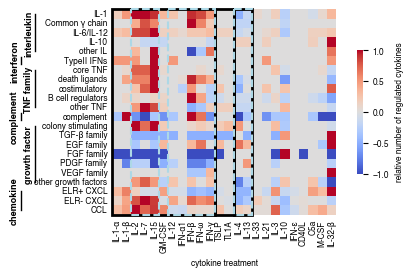

In [181]:
if family_level == "level2":
    fig = plt.figure(figsize=cm_to_inches((12, 7)))
else:
    fig = plt.figure(figsize=cm_to_inches((12, 10)))

df = family_value_counts_both_rel

ax = sns.heatmap(df, vmin=df.min().min(), vmax=df.max().max(), cmap="coolwarm",
            cbar_kws={"label": "relative number of regulated cytokines", "shrink": 0.6 if family_level == "level2" else 0.15}, square=True)


plot_overview_labels_along_y_axis(fig, ax, counts_per_level1_family.keys(),
                                  counts_per_level1_family, -10, len(family_value_counts_positive_rel.index), stagger=1.5, fontsize=6.5)

for community in all_communities_subset:
    if len(community) > 1:
        start = family_value_counts_positive_rel.columns.get_loc(community[0])
        end = family_value_counts_positive_rel.columns.get_loc(community[-1]) + 1
        ax.add_patch(plt.Rectangle((start, 0), end - start, len(family_value_counts_positive_rel.index), fill=False, edgecolor='black', linewidth=2, clip_on=False))

for group in highly_similar_groups_subset:
    if len(group) > 1:
        start = family_value_counts_positive_rel.columns.get_loc(group[0])
        end = family_value_counts_positive_rel.columns.get_loc(group[-1]) + 1
        ax.add_patch(plt.Rectangle((start, 0), end - start, len(family_value_counts_positive_rel.index), fill=False, edgecolor='lightblue', linewidth=1.5, ls="--", clip_on=False))

# Set x and y label size to 6
plt.xticks(fontsize=6)
plt.yticks(fontsize=6)


plt.ylabel("")
apply_greek_labels_heatmap(plt.gca())

plt.xlabel("cytokine treatment")
plt.gca().tick_params(axis='both', length=0)

plt.tight_layout()
plt.savefig(os.path.join(plot_folder, f"5.3_family_value_counts_both_{family_level}.svg"), bbox_inches="tight")

### 5.4 - Investigate literature responses

In [182]:
cytokine_response_df_all_filter = cytokine_response_df_all.copy()
cytokine_response_df_all_filter = cytokine_response_df_all_filter[cytokine_response_df_all_filter["direction"] == "upregulated"]

In [183]:
response_pairs = []
for index, row in cytokine_response_df_all_filter.iterrows():
    response_pairs.append((row["cell_type"], row["response"]))
response_pairs = set(response_pairs)

In [184]:
secretion_pairs = []
for index, row in alyssa_secretion_df.iterrows():
    if row["sumpapers"] > 2:
        secretion_pairs.append((row["cell_type"], row["cytokine"]))
secretion_pairs = set(secretion_pairs)

In [185]:
alyssa_secretion_df["in_expressed_genes"] = alyssa_secretion_df.apply(lambda row: row["cytokine"] in expressed_cytokines_by_cell_type_all[row["cell_type"]], axis=1)
alyssa_secretion_df["in_expressed_genes"].sum()

79

# 6 - Cytokine similarity

In [186]:
spatial_gene_set = pd.read_csv("../annotations/spatial_genes.csv")["gene_name"].tolist()
use_spatial_gene_set = False

## 6.1 - Within cell type correlations

In [187]:
plot_folder = os.path.join(base_plot_folder, "6.1_within_cell_similarity")
os.makedirs(plot_folder, exist_ok=True)

from scipy.spatial.distance import pdist, squareform

In [188]:
# FOR DEBUGGING/TESTING THE SIMILARITY CODE
cell_type = "CD14 Mono"
all_inclusive_filter = expressed_genes_by_cell_type_dict[cell_type]
existing_fold_change_vals = edger_df_log2FoldChange[cell_type].dropna(how='all').index
all_inclusive_filter = [gene for gene in all_inclusive_filter if gene in existing_fold_change_vals]
if use_spatial_gene_set:
    all_inclusive_filter = [gene for gene in all_inclusive_filter  if gene in spatial_gene_set]
cell_type_log2 = edger_df_log2FoldChange.loc[all_inclusive_filter, cell_type]

cytokine1 = "GM-CSF"
cytokine2 = "IL-3"

cell_data_1 = cell_type_log2[cytokine1].dropna()
cell_data_2 = cell_type_log2[cytokine2].dropna()

common_index = cell_data_1.index.intersection(cell_data_2.index)
cell_data_1 = cell_data_1[common_index]
cell_data_2 = cell_data_2[common_index]

r = np.corrcoef(cell_data_1, cell_data_2)[0, 1]
r

0.9282785453081165

In [189]:
f"6.1_r_vals_by_cell_type{'_spatial' if use_spatial_gene_set else ''}.pkl"

'6.1_r_vals_by_cell_type.pkl'

In [190]:
cytokine_combs = list(combinations_with_replacement(CYTOKINE_ORDER, 2))

if os.path.exists(os.path.join("output", f"6.1_r_vals_by_cell_type{'_spatial' if use_spatial_gene_set else ''}.pkl")):
    with open(os.path.join("output", f"6.1_r_vals_by_cell_type{'_spatial' if use_spatial_gene_set else ''}.pkl"), "rb") as f:
        r_vals_by_cell_type = pickle.load(f)
    with open(os.path.join("output", f"6.1_cosine_distances_by_cell_type{'_spatial' if use_spatial_gene_set else ''}.pkl"), "rb") as f:
        cosine_distances_by_cell_type = pickle.load(f)
    with open(os.path.join("output", f"6.1_euclidean_distances_by_cell_type{'_spatial' if use_spatial_gene_set else ''}.pkl"), "rb") as f:
        euclidean_distances_by_cell_type = pickle.load(f)
else:
    r_vals_by_cell_type = {}
    cosine_distances_by_cell_type = {}
    euclidean_distances_by_cell_type = {}
    
    for cell_type in ALL_CELL_TYPES:
        r_vals_by_cytokine = pd.DataFrame(index=[cytokine for cytokine in CYTOKINE_ORDER],
                                             columns=[cytokine for cytokine in CYTOKINE_ORDER])
        cosine_distance_by_cytokine = pd.DataFrame(index=[cytokine for cytokine in CYTOKINE_ORDER],
                                             columns=[cytokine for cytokine in CYTOKINE_ORDER])
        print(cell_type)
        i = 0
        
        # first, use the pre-calculated filter based on expression values
        all_inclusive_filter = expressed_genes_by_cell_type_dict[cell_type]
        
        # then, subset to those where we actually have fold change values for this cell type
        existing_fold_change_vals = edger_df_log2FoldChange[cell_type].dropna(how='all').index
        all_inclusive_filter = [gene for gene in all_inclusive_filter if gene in existing_fold_change_vals]

        if use_spatial_gene_set:
            all_inclusive_filter = [gene for gene in all_inclusive_filter  if gene in spatial_gene_set]
        
        print(len(all_inclusive_filter))
        cell_type_log2 = edger_df_log2FoldChange.loc[all_inclusive_filter, cell_type]
        
        # ------------------- review this ---------------------------
        # euclidean distance
        condensed_distances = pdist(cell_type_log2.T, metric="euclidean")
        euclidean_distance_matrix = squareform(condensed_distances)
        df = pd.DataFrame(euclidean_distance_matrix, index=cell_type_log2.columns, columns=cell_type_log2.columns)
        euclidean_distances_by_cell_type[cell_type] = df
        
        # cosine distance
        condensed_distances = pdist(cell_type_log2.T, metric="cosine")
        cosine_distance_matrix = squareform(condensed_distances)
        df = pd.DataFrame(cosine_distance_matrix, index=cell_type_log2.columns, columns=cell_type_log2.columns)
        cosine_distances_by_cell_type[cell_type] = df
        # -------------------------------------------------------------

        for cytokine1, cytokine2 in cytokine_combs:
            if cytokine1 == cytokine2:
                r_vals_by_cytokine.loc[cytokine1, cytokine2] = 1.0
                continue
            
            # get values for both cytokines and drop na
            cell_data_1 = cell_type_log2[cytokine1].dropna()
            cell_data_2 = cell_type_log2[cytokine2].dropna()

            if len(cell_data_1) == 0 or len(cell_data_2) == 0:
                r_vals_by_cytokine.loc[cytokine1, cytokine2] = np.nan
                continue
            
            # get the intersection of the two cytokines
            common_index = cell_data_1.index.intersection(cell_data_2.index)
            cell_data_1 = cell_data_1[common_index]
            cell_data_2 = cell_data_2[common_index]
            
            r = np.corrcoef(cell_data_1, cell_data_2)[0, 1]
            r_vals_by_cytokine.loc[cytokine1, cytokine2] = r
            
        # fill in the other half of the correlation matrix
        r_vals_by_cytokine = r_vals_by_cytokine.fillna(r_vals_by_cytokine.T).astype(float)
        r_vals_by_cell_type[cell_type] = r_vals_by_cytokine.copy()

    os.makedirs("output", exist_ok=True)
    with open(os.path.join("output", f"6.1_r_vals_by_cell_type{'_spatial' if use_spatial_gene_set else ''}.pkl"), "wb") as f:
        pickle.dump(r_vals_by_cell_type, f)
    with open(os.path.join("output", f"6.1_cosine_distances_by_cell_type{'_spatial' if use_spatial_gene_set else ''}.pkl"), "wb") as f:
        pickle.dump(cosine_distances_by_cell_type, f)
    with open(os.path.join("output", f"6.1_euclidean_distances_by_cell_type{'_spatial' if use_spatial_gene_set else ''}.pkl"), "wb") as f:
        pickle.dump(euclidean_distances_by_cell_type, f)

In [191]:
# Create multi-index DataFrame
index = pd.MultiIndex.from_product([CYTOKINE_ORDER, CYTOKINE_ORDER], names=['cytokine1', 'cytokine2'])
r_vals_by_cell_type_df = pd.DataFrame(index=index, columns=ALL_CELL_TYPES)
cosine_distances_by_cell_type_df = pd.DataFrame(index=index, columns=ALL_CELL_TYPES)
euclidean_distances_by_cell_type_df = pd.DataFrame(index=index, columns=ALL_CELL_TYPES)

# Fill the DataFrames
for cell_type in ALL_CELL_TYPES:
    r_matrix = r_vals_by_cell_type[cell_type]
    cos_matrix = cosine_distances_by_cell_type[cell_type]
    euc_matrix = euclidean_distances_by_cell_type[cell_type]
    
    for cyt1 in CYTOKINE_ORDER:
        for cyt2 in CYTOKINE_ORDER:
            r_vals_by_cell_type_df.loc[(cyt1, cyt2), cell_type] = r_matrix.loc[cyt1, cyt2]
            cosine_distances_by_cell_type_df.loc[(cyt1, cyt2), cell_type] = cos_matrix.loc[cyt1, cyt2]
            euclidean_distances_by_cell_type_df.loc[(cyt1, cyt2), cell_type] = euc_matrix.loc[cyt1, cyt2]

### Get correlations for spatial gene subset

In [192]:
# with open(os.path.join("output", f"6.1_r_vals_by_cell_type.pkl"), "rb") as f:
#     r_vals_by_cell_type_full = pickle.load(f)
# with open(os.path.join("output", f"6.1_r_vals_by_cell_type_spatial.pkl"), "rb") as f:
#     r_vals_by_cell_type_spatial = pickle.load(f)

In [193]:
# # Create figure with subplots
# fig, axes = plt.subplots(3, 5, figsize=cm_to_inches((16, 10)))
# axes = axes.flatten()

# for i, cell_type in enumerate(ALL_CELL_TYPES):
#     df_full = r_vals_by_cell_type_full[cell_type]
#     df_spatial = r_vals_by_cell_type_spatial[cell_type]

#     df_full = df_full.reset_index().melt(id_vars=["index"]).rename(columns={"index": "cytokine_1", "variable": "cytokine_2", "value": "r"})
#     df_spatial = df_spatial.reset_index().melt(id_vars=["index"]).rename(columns={"index": "cytokine_1", "variable": "cytokine_2", "value": "r"})

#     # drop diagonal
#     df_full = df_full[df_full["cytokine_1"] != df_full["cytokine_2"]]
#     df_spatial = df_spatial[df_spatial["cytokine_1"] != df_spatial["cytokine_2"]]

#     # make identifier
#     df_full["identifier"] = df_full["cytokine_1"] + "_" + df_full["cytokine_2"]
#     df_spatial["identifier"] = df_spatial["cytokine_1"] + "_" + df_spatial["cytokine_2"]

#     # set as index
#     df_full.set_index("identifier", inplace=True)
#     df_spatial.set_index("identifier", inplace=True)

#     # drop na
#     df_full = df_full.dropna()
#     df_spatial = df_spatial.dropna()

#     # harmonize index
#     df_spatial = df_spatial.loc[df_full.index]

#     r = np.corrcoef(df_full["r"], df_spatial["r"])[0, 1]
    
#     # Plot on appropriate subplot
#     axes[i].scatter(df_full["r"], df_spatial["r"], rasterized=True, color="skyblue", s=5, alpha=0.5)
#     axes[i].plot([-1,1], [-1,1], color="black")
#     axes[i].text(0.05, 0.95, f'r = {r:.2f}', transform=axes[i].transAxes, 
#                 verticalalignment='top')
#     axes[i].set_title(cell_type)
#     axes[i].set_xlabel("Pearson r\nall genes")
#     axes[i].set_ylabel("Pearson r\nspatial genes")
#     axes[i].label_outer()
#     axes[i].set_xlim(-1,1)
#     axes[i].set_ylim(-1,1)

# # Remove empty subplots
# for i in range(len(ALL_CELL_TYPES), len(axes)):
#     fig.delaxes(axes[i])

# plt.tight_layout()
# for format in ["png", "svg"]:
#     plt.savefig(os.path.join(plot_folder, f"6.1_full_vs_spatial_correlation.{format}"), dpi=400)

### explore how correlation values depend on the impact classification

Could add extra code here to quantify this more comprehensively

In [194]:
# Apply logical AND across the index to find cell types where both IL-3 and GM-CSF have significant impact
both_strong = strong_impact_by_cell_type.loc["IL-3"] & strong_impact_by_cell_type.loc["GM-CSF"]
both_strong_columns = both_strong[both_strong].index
not_both_columns = both_strong[~both_strong].index

In [195]:
r_vals_by_cell_type_df.loc[("IL-3", "GM-CSF"), both_strong_columns].mean()

0.625271062206278

In [196]:
r_vals_by_cell_type_df.loc[("IL-3", "GM-CSF"), not_both_columns].mean()

0.3993215425785904

### create scatter plots

In [197]:
def get_lower_triangle(df):
    """Get values from the lower triangle of a DataFrame (excluding the diagonal)."""
    return df.where(np.tril(np.ones(df.shape), k=-1).astype(bool))

def find_pairs_thresh(r_vals_by_cytokine, threshold):
    pairs = []
    for cytokine1, cytokine2 in cytokine_combs:
        if threshold > 0:
            if r_vals_by_cytokine.loc[cytokine1, cytokine2] > threshold:
                if cytokine1 != cytokine2:
                    pairs.append((cytokine1, cytokine2))
        if threshold < 0:
            if r_vals_by_cytokine.loc[cytokine1, cytokine2] < threshold:
                if cytokine1 != cytokine2:
                    pairs.append((cytokine1, cytokine2))
    return pairs

This takes 5 min to run

In [198]:
all_pairs_df_high = []
for cell_type in ALL_CELL_TYPES:
    r_vals = r_vals_by_cell_type[cell_type]
    pairs = find_pairs_thresh(r_vals, threshold=0.8)
    # sort the pairs by name
    pairs = sorted(pairs, key=lambda x: (x[0], x[1]))
    for cytokine1, cytokine2 in pairs:
        new_row = {"cell_type": cell_type, "cytokine1": cytokine1, "cytokine2": cytokine2, "r": r_vals.loc[cytokine1, cytokine2]}
        new_row = pd.DataFrame([new_row])
        if len(new_row) > 0:
            all_pairs_df_high.append(new_row)
all_pairs_df_high = pd.concat(all_pairs_df_high, ignore_index=True)

all_pairs_df_low = []
for cell_type in ALL_CELL_TYPES:
    r_vals = r_vals_by_cell_type[cell_type]
    pairs = find_pairs_thresh(r_vals, threshold=-0.4)
    # sort the pairs by name
    pairs = sorted(pairs, key=lambda x: (x[0], x[1]))
    for cytokine1, cytokine2 in pairs:
        new_row = {"cell_type": cell_type, "cytokine1": cytokine1, "cytokine2": cytokine2, "r": r_vals.loc[cytokine1, cytokine2]}
        new_row = pd.DataFrame([new_row])
        if len(new_row) > 0:
            all_pairs_df_low.append(new_row)
all_pairs_df_low = pd.concat(all_pairs_df_low, ignore_index=True)
    
all_pairs_df_high["cytokine_pair"] = all_pairs_df_high["cytokine1"] + "_" + all_pairs_df_high["cytokine2"]
all_pairs_df_low["cytokine_pair"] = all_pairs_df_low["cytokine1"] + "_" + all_pairs_df_low["cytokine2"]       

In [199]:
pairs_to_plot = [
    ("IL-15", "IL-2"),
    ("IL-4", "IL-13"),
    ("IL-15", "IL-10"),
    ("IL-3", "GM-CSF"),
    ("IL-15", "APRIL"),
    ("IL-15", "VEGF")
]

from scipy.stats import gaussian_kde
corr_plot_folder = os.path.join(plot_folder, "correlation_plots")
os.makedirs(corr_plot_folder, exist_ok=True)

density_plot_flag = False
        
# ------------------------- Large plot -------------------------
fig, axs = plt.subplots(nrows=4, ncols=6, figsize=cm_to_inches((14, 8)), sharex=True, sharey=True)
axs = axs.flatten()
counter = 0

for cell_type in ALL_CELL_TYPES:
    if not cell_type in ["B cell", "CD14 Mono", "cDC", "CD4 T cell"]:
        continue
    print(cell_type)
    
    r_vals = r_vals_by_cell_type[cell_type]
    #pairs = find_pairs_thresh(r_vals, threshold=-0.4)
    #print(cell_type, pairs)
    pairs = pairs_to_plot
    
    all_inclusive_filter = expressed_genes_by_cell_type_dict[cell_type]
    existing_fold_change_vals = edger_df_log2FoldChange[cell_type].dropna(how='all').index
    all_inclusive_filter = [gene for gene in all_inclusive_filter if gene in existing_fold_change_vals]
    print(len(all_inclusive_filter))
    cell_type_log2 = edger_df_log2FoldChange.loc[all_inclusive_filter, cell_type].dropna()
    
    if use_spatial_gene_set:
        all_inclusive_filter = [gene for gene in cell_type_log2.index if gene in spatial_gene_set]
        cell_type_log2_old = cell_type_log2.copy()
        cell_type_log2 = cell_type_log2.loc[all_inclusive_filter]
    
    for cytokine1, cytokine2 in pairs:
        x = cell_type_log2.loc[:, cytokine1]
        y = cell_type_log2.loc[:, cytokine2]
        r = np.corrcoef(x, y)[0, 1]
        if use_spatial_gene_set: 
            x_old = cell_type_log2_old.loc[:, cytokine1]
            y_old = cell_type_log2_old.loc[:, cytokine2]
            r_old = np.corrcoef(x_old, y_old)[0, 1]
        
        # ------------------------- Small plot -------------------------
        plt.figure(figsize=cm_to_inches((3, 3)))
        plt.scatter(x, y, s = 1, edgecolor="none", alpha=0.5, rasterized=True, zorder=2, label=f"r={r:.2f}")

        plt.ylim(-4, 4)
        plt.xticks([-4, 0, 4], fontsize=6)
        plt.yticks([-4, 0, 4], fontsize=6) 

        plt.xlabel(f"log$_{2}$FC", fontsize=6)
        plt.ylabel(f"log$_{2}$FC", fontsize=6)
        
        plt.title(f'{cytokine1} vs {cytokine2}', fontsize=6.5)
        plt.legend(loc="upper left", fontsize=6)
        
        plt.tight_layout()
        for format in ["png", "svg"]:
            plt.savefig(os.path.join(corr_plot_folder, f"6.1_small_corr_{cell_type}_{cytokine1}_vs_{cytokine2}{'_spatial' if use_spatial_gene_set else ''}.{format}"),
                            bbox_inches="tight", dpi=400)
        plt.close()
        
        # ---- subplots of large plot ----
        ax = axs[counter]
        
        # create a cross at the origin
        ax.plot([-5, 5], [0, 0], color="black", linewidth=1, zorder=0, alpha=0.5)
        ax.plot([0, 0], [-5, 5], color="black", linewidth=1, zorder=0, alpha=0.5)
        ax.scatter(x, y, s = 1, edgecolor="none", alpha=0.5, rasterized=True, zorder=2, color="red" if use_spatial_gene_set else "tab:blue")
        if use_spatial_gene_set:
            ax.scatter(x_old, y_old, s = 1, edgecolor="none", alpha=0.5, rasterized=True, zorder=1, color="gray")
        
        ax.set_xlim(-4, 4)
        ax.set_ylim(-4, 4)
        ax.set_xticks([-4, -2, 0, 2, 4])
        ax.set_yticks([-4, -2, 0, 2, 4]) 

        # ax.set_xlabel(f"log$_{2}$FC({introduce_greek_letters(cytokine1)})", fontsize=6)
        # ax.set_ylabel(f"log$_{2}$FC({introduce_greek_letters(cytokine2)})", fontsize=6)
        ax.set_xlabel(f"{introduce_greek_letters(cytokine1)}", fontsize=6)
        ax.set_ylabel(f"{introduce_greek_letters(cytokine2)}", fontsize=6)
        #ax.set_title(f'{cell_type}, r={r:.2f}', fontsize=6)
        
        if use_spatial_gene_set:
            correlation_text = f"r$_\\mathrm{{spatial}}$={r:.2f}\nr$_\\mathrm{{full}}$={r_old:.2f}"
        else:
            correlation_text = f"r={r:.2f}"
        ax.text(0.05 if "IL-10" not in [cytokine1, cytokine2] else 0.4, 0.95, correlation_text, transform=ax.transAxes, 
                fontsize=5, verticalalignment='top',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.7, edgecolor='none'))
        
        # Set tick length to 0
        ax.tick_params(axis='both', which='both', length=0)
        
        counter += 1
        
        # Hide x and y tick labels for inner subplots
        # Only show y tick labels for the first column
        # Only show x tick labels for the last row
        if not ax.get_subplotspec().is_first_col():
            #ax.set_ylabel('')
            plt.setp(ax.get_yticklabels(), visible=False)
        
        if not ax.get_subplotspec().is_last_row():
            #ax.set_xlabel('')
            plt.setp(ax.get_xticklabels(), visible=False)

plt.tight_layout(pad=0.5, h_pad=0.5, w_pad=0.5)
for format in ["png", "svg"]:
    plt.savefig(os.path.join(corr_plot_folder, f"6.1_large_corr_panel{'_spatial' if use_spatial_gene_set else ''}.{format}"),
                    bbox_inches="tight", dpi=400)
plt.close()


B cell
8150
CD4 T cell
7933
cDC
8581
CD14 Mono
8223


In [200]:
if use_spatial_gene_set:
    raise Exception("Deactivate spatial gene set to continue!")

In [201]:
r_vals_by_cell_type_df.to_excel(os.path.join(output_tables_folder, "6.1_r_vals_by_cell_type_df.xlsx"))

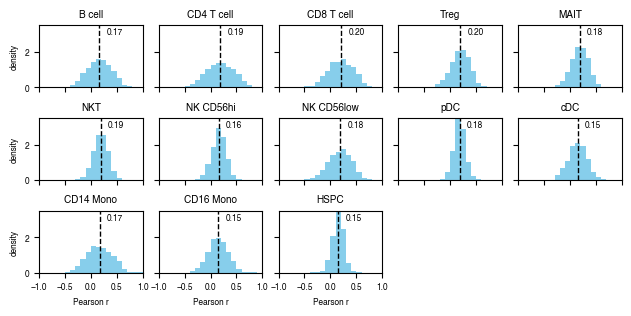

In [202]:
# Create a subplot grid based on number of cell types
n_cell_types = len(r_vals_by_cell_type.keys())
n_rows = 3
n_cols = 5

fig, axes = plt.subplots(n_rows, n_cols, figsize=cm_to_inches((16, 8)))
axes = axes.flatten()

# Plot histogram for each cell type
for idx, (cell_type, ax) in enumerate(zip(r_vals_by_cell_type.keys(), axes)):
    df_subset = r_vals_by_cell_type[cell_type].copy()
    # set all diagonals to NaN
    df_subset.values[np.diag_indices_from(df_subset)] = np.nan
    flattened = pd.Series(df_subset.values.flatten()).dropna()
    ax.hist(flattened, bins=np.arange(-1, 1.01, 0.1), density=True, color="skyblue")
    mean_val = flattened.mean()
    
    ax.axvline(mean_val, color='black', linestyle='dashed', linewidth=1)
    ax.text(mean_val+0.3, 3, f'{mean_val:.2f}', color='black', ha='center')
    ax.set_title(cell_type)
    ax.set_ylim(0, 3.5)
    ax.set_xlim(-1, 1)
    
    ax.set_ylabel("density")
    ax.set_xlabel("Pearson r")
    ax.label_outer()

for idx in range(len(r_vals_by_cell_type.keys()), len(axes)):
    fig.delaxes(axes[idx])

plt.tight_layout()
for format in ["png", "svg"]:
    plt.savefig(os.path.join(plot_folder, f"6.1_corr_histograms.{format}"), dpi=300, bbox_inches="tight")

## Dendrogram clustering

#### This isn't actually being used in the paper

In [203]:
def plot_heatmap_with_clustering(distance_matrix, cell_type, plot_name, heatmap_label, communities=None):
    """This plots a heatmap for the Supplementary Information."""
    if communities is not None:
        communities_flat = [item for sublist in communities for item in sublist]
        distance_matrix = distance_matrix.loc[communities_flat, communities_flat]

    plt.figure(figsize=(len(distance_matrix)*0.1+1, len(distance_matrix)*0.1+1))
    ax = sns.heatmap(distance_matrix, cmap="coolwarm", center=0, annot=False, fmt=".2f", vmin=-1, vmax=1, cbar=True, square=True,
                cbar_kws={'label': heatmap_label, 'shrink': 0.6})
    
    # plot black boxes around the communities
    if communities is not None:
        current_pos = 0
        for community in communities:
            num_entries = len(community)
            rect = plt.Rectangle((current_pos, current_pos), num_entries, num_entries, fill=False, color='black', linewidth=1.5, clip_on=False)
            plt.gca().add_patch(rect)
            current_pos += num_entries
    
    # set font sizes to 5.5
    ax.set_xticks(np.arange(0.5, len(distance_matrix)+0.5))
    ax.set_yticks(np.arange(0.5, len(distance_matrix)+0.5))
    ax.set_xticklabels(distance_matrix.index, fontsize=5.5, rotation=90)  # Rotate for better visibility
    ax.set_yticklabels(distance_matrix.index, fontsize=5.5)
    # set the tick length to 0
    ax.tick_params(length=0)
    
    apply_greek_labels_heatmap(ax)

    plt.title(f"{cell_type}", fontsize=7)
    plt.tight_layout()

    for format in ["png", "svg"]:
        plt.savefig(f"{plot_folder}/6_{plot_name}_{cell_type}.{format}", bbox_inches="tight")
        
        
def plot_heatmap_with_clustering_small(distance_matrix, cell_type, plot_name, heatmap_label, communities=None):
    """This plots a heatmap for the Main Text."""
    if communities is not None:
        communities_flat = [item for sublist in communities for item in sublist]
        distance_matrix = distance_matrix.loc[communities_flat, communities_flat]

    plt.figure(figsize=cm_to_inches((8.5,8.5)))
    ax = sns.heatmap(
        distance_matrix, cmap="coolwarm", center=0, annot=False, fmt=".2f",
        vmin=-1, vmax=1, cbar=True, square=True,
        cbar_kws={'label': heatmap_label, 'shrink': 0.45}
    )
    cbar = ax.collections[0].colorbar
    cbar.ax.tick_params(labelsize=5.5)  # Reduce the fontsize of the colorbar labels
    
    # plot black boxes around the communities
    if communities is not None:
        current_pos = 0
        for community in communities:
            num_entries = len(community)
            rect = plt.Rectangle((current_pos, current_pos), num_entries, num_entries,
                                 fill=False, color='black', linewidth=1.5, clip_on=False)
            plt.gca().add_patch(rect)
            current_pos += num_entries
    
    # Instead of the default y-axis labels, we will stagger them in 3 positions.
    # First, remove the default labels:
    ax.set_xticklabels([])
    ax.set_yticklabels([])

    # Define 3 staggered horizontal offsets (in axis coordinates: 0=left, 1=right).
    # Adjust these values as needed for your plot.
    stagger_offsets = [-0.01, -0.15, -0.19]
    
    # Manually add the y-axis labels at staggered positions.
    for i, label in enumerate(distance_matrix.index):
        offset = stagger_offsets[i % 2]
        ax.text(
            offset, i + 0.2, introduce_greek_letters(label),
            ha='right', va='center', fontsize=5.5,
            transform=ax.get_yaxis_transform()  # x in axis fraction, y in data coordinates
        )
    
    # remove tick marks
    ax.tick_params(length=0)
    
    apply_greek_labels_heatmap(ax)
    
    plt.title(f"{cell_type}", fontsize=7)
    plt.tight_layout()

    for format in ["png", "svg"]:
        plt.savefig(f"{plot_folder}/6_small_{plot_name}_{cell_type}.{format}", bbox_inches="tight")

In [204]:
%%capture output
import scipy.cluster.hierarchy as sch
from scipy.spatial.distance import squareform

def dendrogram_clustering(distance_matrix):
    columns = distance_matrix.columns
    distance_matrix_original = distance_matrix.copy()
    
    # I. distance matrix
    # replace NaN values with 0
    distance_matrix = np.nan_to_num(distance_matrix)

    # condense the distance matrix
    condensed_distance = squareform(distance_matrix)

    # II. hierarchical clustering 
    linkage = sch.linkage(condensed_distance, method='ward')

    # get the dendrogram and ordered indices
    dendro = sch.dendrogram(linkage, labels=columns, no_plot=True)
    ordered_indices = dendro['leaves']

    # compute cophenetic distances between leaves
    _, cophenetic_distances = sch.cophenet(linkage, condensed_distance)
    # convert to a square matrix
    cophenetic_matrix = squareform(cophenetic_distances)
    cophenetic_df = pd.DataFrame(cophenetic_matrix, index=columns, columns=columns)
    cophenetic_df = cophenetic_df.iloc[ordered_indices, ordered_indices]
    cophenetic_df = cophenetic_df/cophenetic_df.max().max()
    
    return distance_matrix_original.iloc[ordered_indices, ordered_indices], cophenetic_df, linkage

for cell_type in r_vals_by_cell_type.keys():
    cytokine_filter = strong_impact_by_cell_type[cell_type][strong_impact_by_cell_type[cell_type]].index
    distance_matrix = cosine_distances_by_cell_type[cell_type].loc[cytokine_filter, cytokine_filter].astype(float)
    # distance_matrix = 1 - r_vals_by_cytokine
    ordered_distance_vals, _, _ = dendrogram_clustering(distance_matrix)
    plot_heatmap_with_clustering(1-ordered_distance_vals, cell_type, plot_name="cosine_dendrogram", heatmap_label="cosine similarity") #, family_dict=cytokine_name_to_level_2_family)

## Group cytokines by highly similar correlation values

In [205]:
# get the correlation values in long format
all_r_vals_long = (
    r_vals_by_cell_type_df
    .stack()
    .reset_index()
    .rename(columns={
        "level_2": "cell_type",
        0: "r_val"
    })
)

In [206]:
# check if both cytokines have a strong impact in a given cell type
all_r_vals_long["strong_impact"] = False
for index, row in all_r_vals_long.iterrows():
    cytokine_1 = row["cytokine1"]
    cytokine_2 = row["cytokine2"]
    cell_type = row["cell_type"]
    strong_impact_1 = strong_impact_by_cell_type.loc[cytokine_1, cell_type]
    strong_impact_2 = strong_impact_by_cell_type.loc[cytokine_2, cell_type]
    if strong_impact_1 and strong_impact_2:
        all_r_vals_long.loc[index, "strong_impact"] = True

In [207]:
# subset to strong impact and exclude unwanted cell types
all_r_vals_long = all_r_vals_long[all_r_vals_long["strong_impact"]]
all_r_vals_long = all_r_vals_long[all_r_vals_long["cell_type"].isin(ALL_CELL_TYPES_EXCLUDE)]

In [208]:
# Create a unique identifier
all_r_vals_long["unique_identifier"] = all_r_vals_long.apply(
    lambda x: "_".join(sorted([str(x.get("cytokine1", "")), str(x.get("cytokine2", "")), str(x.get("cell_type", ""))])), 
    axis=1
)
# Drop duplicates based on the unique identifier
all_r_vals_long = all_r_vals_long.drop_duplicates(subset=["unique_identifier"])

In [209]:
# subset to those that have values in at least three cell types
all_r_vals_long["cyto1_cyto2"] = all_r_vals_long["cytokine1"] + "_" + all_r_vals_long["cytokine2"]
val_counts = all_r_vals_long["cyto1_cyto2"].value_counts()

# subset to those measured in at least three cell types
val_counts = val_counts[val_counts > 2]
all_r_vals_long = all_r_vals_long[all_r_vals_long["cyto1_cyto2"].isin(val_counts.index)]

In [210]:
# calculate the mean value
mean_r = all_r_vals_long.groupby(["cytokine1", "cytokine2"])["r_val"].mean()
mean_r = mean_r.unstack()

In [211]:
# threshold at mean values
group_by_cytokine = pd.DataFrame(columns=["cytokine1", "cytokine2"])
threshold = 0.7
for cytokine_1 in mean_r.index:
    cytokine_r = mean_r.loc[cytokine_1]
    cytokine_r = cytokine_r[cytokine_r > threshold]
    for cytokine_2 in cytokine_r.index:
        group_by_cytokine.loc[len(group_by_cytokine)] = [cytokine_1, cytokine_2]

group_by_cytokine = group_by_cytokine[group_by_cytokine["cytokine1"] != group_by_cytokine["cytokine2"]]

In [212]:
# Create pair column by sorting cytokine names alphabetically and joining with underscore
group_by_cytokine["pair"] = group_by_cytokine.apply(lambda x: f"{min(x['cytokine1'], x['cytokine2'])}_{max(x['cytokine1'], x['cytokine2'])}", axis=1)

# Remove duplicate pairs
group_by_cytokine = group_by_cytokine.drop_duplicates(subset=["pair"])

In [213]:
def sort_list_by_reference(input_list, reference):
    """
    Sort a list based on the order of elements in a reference list.
    
    Parameters:
    -----------
    input_list : list
        The list to be sorted. Should be a subset of the reference list.
    reference : list
        The reference list that defines the desired order.
        
    Returns:
    --------
    list
        A new list with elements from input_list sorted according to their order in reference.
    """
    # Create a dictionary mapping each element in reference to its position
    reference_positions = {element: i for i, element in enumerate(reference)}
    
    # Sort the input list based on the positions in the reference list
    sorted_list = sorted(input_list, key=lambda x: reference_positions.get(x, float('inf')))
    
    return sorted_list

In [214]:
import igraph as ig
import leidenalg

# Create an undirected graph
G = ig.Graph()

# Add vertices (unique cytokines)
unique_cytokines = set(group_by_cytokine['cytokine1'].unique()) | set(group_by_cytokine['cytokine2'].unique())
G.add_vertices(list(unique_cytokines))

# Add edges from the dataframe
edges = list(zip(group_by_cytokine['cytokine1'], group_by_cytokine['cytokine2']))
G.add_edges(edges)

# Find connected components
components = G.components()

# Print each group
all_close_groups = []
for i, component in enumerate(components, 1):
    # Get the vertex names for this component
    group = [G.vs[idx]['name'] for idx in component]
    sorted_group = sort_list_by_reference(group, list(cytokine_info.index))
    print(f"Group {i}: {sorted_group}")
    all_close_groups.append(sorted_group)

Group 1: ['IL-2', 'IL-7', 'IL-15']
Group 2: ['OSM', 'IL-17C']
Group 3: ['IL-27', 'IL-12', 'IFN-alpha1', 'IFN-beta', 'IFN-omega', 'IFN-gamma']
Group 4: ['IL-4', 'IL-13']


In [215]:
with open(os.path.join("output", "6_highly_similar_groups.pkl"), "wb") as f:
    pickle.dump(all_close_groups, f)

## Leiden clustering


#### Clustering in each cell type

In [216]:
def leiden_clustering(distance_matrix, resolution_parameter=0.5, print_communities=False, invert_distance=False):
    # Convert the DataFrame to a list-of-lists
    if invert_distance:
        adjacency = (1-distance_matrix.values).tolist()
    else:
        adjacency = (distance_matrix.values).tolist()

    # Create an undirected graph. Use loops=False to avoid self-loops.
    g = ig.Graph.Weighted_Adjacency(adjacency, mode=ig.ADJ_UNDIRECTED, attr="weight", loops=False)

    # Set vertex names for easier interpretation.
    g.vs["name"] = list(distance_matrix.index)

    # Apply the Leiden algorithm.
    partition = leidenalg.find_partition(
        g,
        leidenalg.CPMVertexPartition,
        weights='weight',
        resolution_parameter=resolution_parameter
    )

    all_communities = []
    for i, community in enumerate(partition):
        community_nodes = [g.vs[node]["name"] for node in community]
        if print_communities:
            print(f"Community {i+1}: {community_nodes}")
        all_communities.append(community_nodes)

    communities_flat = [item for sublist in all_communities for item in sublist]
    
    return all_communities, communities_flat

In [217]:
%%capture output
all_communities_by_cell_type = {}
for cell_type in ALL_CELL_TYPES_EXCLUDE:
    # subset to cytokines with strong impact in this cell type
    cytokine_filter = strong_impact_by_cell_type[cell_type][strong_impact_by_cell_type[cell_type]].index
    distance_matrix = r_vals_by_cell_type[cell_type].loc[cytokine_filter, cytokine_filter].astype(float)
    # Get the distance matrix.
    df = distance_matrix.copy()
    # Ensure that the diagonal is zero (i.e., no self-loops)
    np.fill_diagonal(df.values, 0)

    all_communities, _ = leiden_clustering(distance_matrix, 0.5, False, False)

    all_communities_by_cell_type[cell_type] = all_communities
    plot_heatmap_with_clustering(distance_matrix, cell_type, plot_name="pearson_leiden", heatmap_label="Pearson r", communities=all_communities)
    if cell_type == "CD14 Mono":
        plot_heatmap_with_clustering_small(distance_matrix, cell_type, plot_name="pearson_leiden", heatmap_label="Pearson r", communities=all_communities)

#### Clustering across cell types

In [218]:
# create a distance matrix by normalizing clustering counts
grouped_together_total = pd.DataFrame(0, index=CYTOKINE_ORDER, columns=CYTOKINE_ORDER)

for cell_type, communities in all_communities_by_cell_type.items():
    for community in communities:
        for cytokine_1 in community:
            for cytokine_2 in community:
                grouped_together_total.loc[cytokine_1, cytokine_2] += 1
                
# discard those with 0 in the diagonal
# Keep only cytokines that have at least 2 interactions
non_zero_diag = grouped_together_total.index[grouped_together_total.values.diagonal() > 1]
grouped_together_total = grouped_together_total.loc[non_zero_diag, non_zero_diag]

# Compute the row sums
row_sums = grouped_together_total.sum(axis=1)

# Compute the inverse square roots of the row sums
eps = 1e-10
inv_sqrt = 1 / np.sqrt(row_sums + eps)

# Get the normalization factors
norm_factors = pd.Series(inv_sqrt, index=grouped_together_total.index)

# Perform the symmetric normalization
# Multiply rows by the normalization factors, then columns.
normalized_matrix = grouped_together_total.mul(norm_factors, axis=0)\
                                          .mul(norm_factors, axis=1)

# round to 5 decimal places
normalized_matrix = normalized_matrix.round(5)
cosine_distances = squareform(pdist(normalized_matrix.values, metric='cosine'))
cosine_distances = pd.DataFrame(cosine_distances, index=normalized_matrix.index, columns=normalized_matrix.index)                

In [219]:
# perform Leiden clustering (so far: resolution 0.5)
all_communities, _ = leiden_clustering(cosine_distances, resolution_parameter=0.7, print_communities=False, invert_distance=True)

In [220]:
# reorder communities internally to group highly similar cytokines
reordered_communities = []

for community in all_communities:
    community_list = list(community)
    
    # track which elements were moved to maintain order of non-subgroup elements
    moved_elements = set()
    
    # process each group that's a subset of this community in all_close_groups
    for group in all_close_groups: # this was calculated above by grouping on correlation
        if set(group).issubset(set(community)):
            # find the earliest index of any group member in the community
            earliest_idx = min(community_list.index(member) for member in group)
            
            # remove group members from their current positions
            # (if they haven't been moved by a previously)
            for member in group:
                if member not in moved_elements:
                    community_list.remove(member)
                    moved_elements.add(member)
            
            # insert group members together at the earliest possible index
            for i, member in enumerate(group):
                if member not in community_list:  # avoid duplicates (do I need this?)
                    community_list.insert(earliest_idx + i, member)
    
    reordered_communities.append(community_list)

# replace all_communities with the reordered version
all_communities = reordered_communities
communities_flat = [item for sublist in all_communities for item in sublist]

In [221]:
all_communities

[['IL-1-alpha',
  'IL-1-beta',
  'IL-2',
  'IL-7',
  'IL-15',
  'GM-CSF',
  'IL-27',
  'IL-12',
  'IFN-alpha1',
  'IFN-beta',
  'IFN-omega',
  'IFN-gamma'],
 ['OSM',
  'IL-17C',
  'IL-17A',
  'IFN-lambda1',
  'TNF-alpha',
  'CD27L',
  'RANKL',
  'G-CSF',
  'EGF',
  'IGF-1'],
 ['TSLP', 'IFN-lambda3', 'BAFF', 'TL1A', 'FGF-beta', 'Noggin'],
 ['IL-4', 'IL-13'],
 ['IL-1Ra'],
 ['IL-33'],
 ['IL-21'],
 ['IL-3'],
 ['IL-10'],
 ['IL-17D'],
 ['IFN-epsilon'],
 ['CD40L'],
 ['C5a'],
 ['IL-34'],
 ['M-CSF'],
 ['Leptin'],
 ['IL-32-beta']]

In [222]:
strong_impact_by_cell_type.loc[["IFN-lambda3", "TSLP"]]

,B cell,CD4 T cell,CD8 T cell,Treg,MAIT,NKT,NK CD56hi,NK CD56low,pDC,cDC,CD14 Mono,CD16 Mono,HSPC
IFN-lambda3,True,True,True,True,True,True,True,True,False,True,True,True,False
TSLP,True,True,True,True,True,True,True,True,False,True,True,True,False


In [223]:
r_vals_by_cell_type_df.loc[("TSLP", "IFN-lambda3")]

B cell         0.68778
CD4 T cell    0.731313
CD8 T cell    0.736326
Treg          0.625552
MAIT          0.623575
NKT           0.640567
NK CD56hi     0.520317
NK CD56low    0.685931
pDC           0.316258
cDC           0.230705
CD14 Mono     0.461884
CD16 Mono     0.537031
HSPC          0.236255
Name: (TSLP, IFN-lambda3), dtype: object

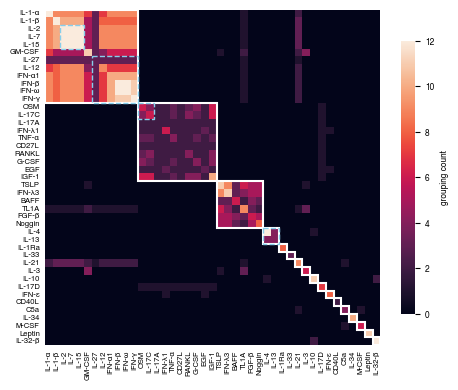

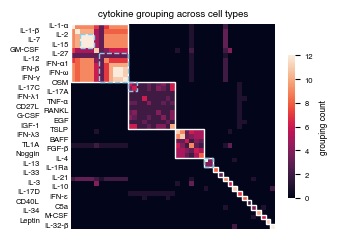

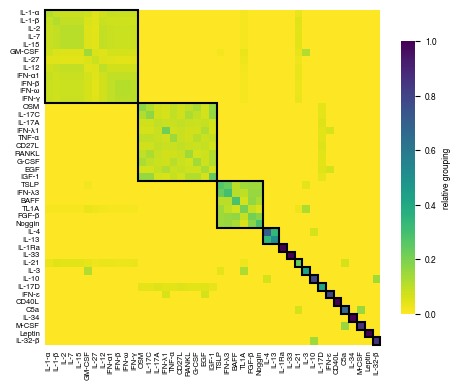

In [224]:
# -------------------- Plotting --------------------
df_to_plot = grouped_together_total.loc[communities_flat, communities_flat]
plt.figure(figsize=cm_to_inches((12, 12)))

ax = sns.heatmap(df_to_plot, square=True, vmin=0, vmax=12, cbar=True,
             cbar_kws={'label': 'grouping count', 'shrink': 0.6})

# plot white boxes around the communities
current_pos = 0
for community in all_communities:
    num_entries = len(community)
    rect = plt.Rectangle((current_pos, current_pos), num_entries, num_entries, fill=False, color='white', linewidth=1.5, clip_on=False)
    plt.gca().add_patch(rect)
    current_pos += num_entries

# Plot additional boxes around highly similar groups
for group in all_close_groups:
    group_indices = [communities_flat.index(member) for member in group if member in communities_flat]
    if group_indices:
        min_idx = min(group_indices)
        max_idx = max(group_indices)
        rect = plt.Rectangle((min_idx, min_idx), max_idx - min_idx + 1, max_idx - min_idx + 1, fill=False, color='skyblue', ls="--", linewidth=1, clip_on=False)
        plt.gca().add_patch(rect)

# set font sizes to 5.5
ax.set_xticks(np.arange(0.5, len(df_to_plot)+0.5))
ax.set_yticks(np.arange(0.5, len(df_to_plot)+0.5))
ax.set_xticklabels(df_to_plot.index, fontsize=5.5, rotation=90)  # Rotate for better visibility
ax.set_yticklabels(df_to_plot.index, fontsize=5.5)
# set the tick length to 0
ax.tick_params(length=0)

apply_greek_labels_heatmap(ax)

plt.tight_layout()
for format in ["png", "svg"]:
    plt.savefig(f"{plot_folder}/6_grouped_together_total.{format}", bbox_inches="tight")


# -------------------- Plotting ALT --------------------
df_to_plot = grouped_together_total.loc[communities_flat, communities_flat]
plt.figure(figsize=cm_to_inches((8.5, 8.5)))

ax = sns.heatmap(df_to_plot, square=True, vmin=0, vmax=12, cbar=True,
             cbar_kws={'label': 'grouping count', 'shrink': 0.45})

cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=5.5)  # Reduce the fontsize of the colorbar labels

# plot white boxes around the communities
current_pos = 0
for community in all_communities:
    num_entries = len(community)
    rect = plt.Rectangle((current_pos, current_pos), num_entries, num_entries, fill=False, color='white', linewidth=1, clip_on=False)
    plt.gca().add_patch(rect)
    current_pos += num_entries

# Plot additional boxes around highly similar groups
for group in all_close_groups:
    group_indices = [communities_flat.index(member) for member in group if member in communities_flat]
    if group_indices:
        min_idx = min(group_indices)
        max_idx = max(group_indices)
        rect = plt.Rectangle((min_idx, min_idx), max_idx - min_idx + 1, max_idx - min_idx + 1, fill=False, color='skyblue', ls="--", linewidth=1, clip_on=False)
        plt.gca().add_patch(rect)


# Instead of the default y-axis labels, we will stagger them in 3 positions.
# First, remove the default labels:
ax.set_xticklabels([])
ax.set_yticklabels([])

# Define 3 staggered horizontal offsets (in axis coordinates: 0=left, 1=right).
# Adjust these values as needed for your plot.
stagger_offsets = [-0.01, -0.15, -0.19]

# Manually add the y-axis labels at staggered positions.
# Here, the y coordinate is the same as the tick (i + 0.5) and the x position is determined by the stagger.
for i, label in enumerate(df_to_plot.index):
    offset = stagger_offsets[i % 2]
    ax.text(
        offset, i + 0.2, introduce_greek_letters(label),
        ha='right', va='center', fontsize=5.5,
        transform=ax.get_yaxis_transform()  # x in axis fraction, y in data coordinates
    )

# remove tick marks
ax.tick_params(length=0)
    
ax.set_title("cytokine grouping across cell types", fontsize=7)
apply_greek_labels_heatmap(ax)

plt.tight_layout()
for format in ["png", "svg"]:
    plt.savefig(f"{plot_folder}/6_grouped_together_total_alt.{format}", bbox_inches="tight")


# ------------------------------------------------------------------------
df_to_plot = normalized_matrix.loc[communities_flat, communities_flat]
plt.figure(figsize=cm_to_inches((12, 12)))
ax = sns.heatmap(df_to_plot, square=True, vmin=df_to_plot.min().min(), vmax=df_to_plot.max().max(), cbar=True, cmap="viridis_r",
             cbar_kws={'label': 'relative grouping', 'shrink': 0.6})

# plot black boxes around the communities
current_pos = 0
for community in all_communities:
    num_entries = len(community)
    rect = plt.Rectangle((current_pos, current_pos), num_entries, num_entries, fill=False, color='black', linewidth=1.5, clip_on=False)
    plt.gca().add_patch(rect)
    current_pos += num_entries

# set font sizes to 5.5
ax.set_xticks(np.arange(0.5, len(df_to_plot)+0.5))
ax.set_yticks(np.arange(0.5, len(df_to_plot)+0.5))
ax.set_xticklabels(df_to_plot.index, fontsize=5.5, rotation=90)  # Rotate for better visibility
ax.set_yticklabels(df_to_plot.index, fontsize=5.5)
# set the tick length to 0
ax.tick_params(length=0)

apply_greek_labels_heatmap(ax)

plt.tight_layout()
for format in ["png", "svg"]:
    plt.savefig(f"{plot_folder}/6_grouped_together_rel.{format}", bbox_inches="tight")

In [225]:
# save the results
with open(os.path.join("output", "6_all_communities_cyto_cyto.pkl"), "wb") as f:
    pickle.dump(all_communities, f)

In [226]:
all_communities_str = [", ".join(l) for l in all_communities]
all_communities_df = pd.DataFrame(all_communities_str).rename(columns={0: "communities_across_cells"})
all_communities_df["close_groups_across_cells"] = ""

for l in all_close_groups:
    mapping_index = [i for i, community in enumerate(all_communities) if all(cyto in community for cyto in l)]
    if mapping_index:
        if len(all_communities_df.loc[mapping_index[0], "close_groups_across_cells"]) == 0:
            all_communities_df.loc[mapping_index[0], "close_groups_across_cells"] = ", ".join(l)
        else:
            all_communities_df.loc[mapping_index[0], "close_groups_across_cells"] = \
                all_communities_df.loc[mapping_index[0], "close_groups_across_cells"] + "; " + ", ".join(l)
all_communities_df.to_csv(os.path.join(output_tables_folder, "6.1_across_cell_communities.csv"))

In [227]:
all_communities_by_cell_type_df = {}
for cell_type in ALL_CELL_TYPES_EXCLUDE:
    communities = all_communities_by_cell_type[cell_type]
    output_df = pd.DataFrame(index=CYTOKINE_ORDER, columns=CYTOKINE_ORDER, data=np.nan)
    
    # set everything with strong impact to 0
    strong_impact = strong_impact_by_cell_type[cell_type]
    strong_impact = strong_impact[strong_impact].index
    output_df.loc[strong_impact, strong_impact] = 0

    for community in communities:
        combinations = list(itertools.product(community, community))
        for c1, c2 in combinations:
            output_df.loc[c1, c2] = 1
    all_communities_by_cell_type_df[cell_type] = output_df
all_communities_by_cell_type_df = pd.concat(all_communities_by_cell_type_df, axis=1, keys=ALL_CELL_TYPES_EXCLUDE)
all_communities_by_cell_type_df.to_csv(os.path.join(output_tables_folder, "6.1_within_cell_communities.csv"))

## 6.1.2 - Second order responses

In [228]:
plot_folder = os.path.join(base_plot_folder, "6.1.2_second_order")
os.makedirs(plot_folder, exist_ok=True)

In [229]:
test = cytokine_response_df_all[cytokine_response_df_all["response"] == "IL-15"]
test = test[test['direction'] == "upregulated"]

In [230]:
r_vals_by_cell_type_df.loc["IL-15", "NK CD56low"].sort_values()

cytokine2
IL-10       -0.500732
IL-6        -0.373284
TNF-alpha   -0.362601
IL-13       -0.316826
IGF-1       -0.274099
               ...   
IFN-gamma    0.734862
IFN-beta      0.75103
IFN-omega    0.771036
IL-2          0.94851
IL-15             1.0
Name: NK CD56low, Length: 90, dtype: object

In [231]:
# inputs
# outliers_rec_by_cell_type_high_high: High receptor expression - strong response
# outliers_rec_by_cell_type_low_high: Low receptor expression - strong response (secondary response?)
receptor_expression_threshold = 2**4

all_secondary_responses_pre_filter = {}
all_secondary_responses = {}
if 'cytokine_response_df_all' in locals():
    expressed_receptors = max_receptor_expression[max_receptor_expression > receptor_expression_threshold].index # these are all receptors that are relevant in principle
    test_cytokines = CYTOKINE_ORDER
    
    for test_cytokine in test_cytokines: # secondary responses for a specific cytokine
        # all cell types that have a strong response to the primary cytokine and high receptor expression
        base_cell_types = list(outliers_rec_by_cell_type_high_high[outliers_rec_by_cell_type_high_high["index"] == test_cytokine]["cell_type"])
        # all cell types that have a strong response to the primary cytokine and low receptor expression
        additional_cell_types = list(outliers_rec_by_cell_type_low_high[outliers_rec_by_cell_type_low_high["index"] == test_cytokine]["cell_type"])
        
        # get upregulated cytokines in primary response cell types for response to test_cytokine
        df = cytokine_response_df_all[(cytokine_response_df_all["treatment"] == test_cytokine) & (cytokine_response_df_all["cell_type"].isin(base_cell_types))].sort_values(by="fold_changes")
        df = df[df['cell_type'].isin(ALL_CELL_TYPES_EXCLUDE)] # only look at the subset for which we have good data
        df["fold_changes"] = df["fold_changes"].apply(min) # this is to get the lowest fold-change for multi-subunit cytokines (only care about upregulation here so this works)
        df = df[df["fold_changes"] > 1] # subset on those that are substantially upregulated
        df = df[~(df["response"] == test_cytokine)] #  We don't care about self-interaction here
        df = df[df["response"].isin(expressed_receptors)] # Only look at cytokines where receptors are expressed somewhere
        secondary_cytokines = df["response"].unique()
        secondary_responses = {}
        all_secondary_responses_pre_filter[test_cytokine] = []
        for secondary_cytokine in secondary_cytokines:
            secreting_cell_types = df[df['response'] == secondary_cytokine]['cell_type'].unique()
            strong_responders = list(outliers_rec_by_cell_type_high_high[outliers_rec_by_cell_type_high_high["index"] == secondary_cytokine]["cell_type"]) # strong enough response to primary cytokine
            strong_responders = [c for c in strong_responders if c in additional_cell_types] # only look at those where we don't have a primary response
            if len(strong_responders) > 0:
                all_secondary_responses_pre_filter[test_cytokine].append(secondary_cytokine)
                responder_similarities = r_vals_by_cell_type_df.loc[test_cytokine]
                responder_similarities = responder_similarities.loc[secondary_cytokine, strong_responders]
                responder_similarities = responder_similarities[responder_similarities > 0.5]
                if len(responder_similarities) > 0:
                    secondary_responses[secondary_cytokine] = {}
                    secondary_responses[secondary_cytokine]['similarity'] = responder_similarities
                    secondary_responses[secondary_cytokine]['secreters'] = secreting_cell_types
        if len(secondary_responses) > 0:
            all_secondary_responses[test_cytokine] = secondary_responses

In [232]:
rows_list = []

# Check if all_secondary_responses exists and is a dictionary
if 'all_secondary_responses' in locals() and isinstance(all_secondary_responses, dict):
    for primary_cytokine, secondary_map in all_secondary_responses.items():
        for secondary_cytokine, details_dict in secondary_map.items():
            similarity_series = details_dict.get('similarity')
            secreters_array = details_dict.get('secreters')

            # Ensure that 'similarity' and 'secreters' keys exist and their values are not None
            if similarity_series is not None and secreters_array is not None:
                # Convert numpy array of secreting cell types to a list
                secreting_cell_types_list = list(secreters_array)
                
                # Iterate through the similarity Series (index=responding_cell_type, value=similarity_score)
                for responding_cell_type, similarity_score in similarity_series.items():
                    rows_list.append({
                        'primary_cytokine': primary_cytokine,
                        'secondary_cytokine': secondary_cytokine,
                        'responding_cell_type': responding_cell_type,
                        'similarity_score': similarity_score,
                        'secreting_cell_types': secreting_cell_types_list
                    })

# Define column names for the DataFrame
column_names = [
    'primary_cytokine', 
    'secondary_cytokine', 
    'responding_cell_type', 
    'similarity_score', 
    'secreting_cell_types'
]

# Create the DataFrame from the list of rows
df_all_secondary_responses = pd.DataFrame(rows_list, columns=column_names)
df_all_secondary_responses = df_all_secondary_responses.explode("secreting_cell_types")

# Display the resulting DataFrame
df_all_secondary_responses['secondary_cytokine'] = df_all_secondary_responses['secondary_cytokine'].apply(introduce_greek_letters)
df_all_secondary_responses['primary_cytokine'] = df_all_secondary_responses['primary_cytokine'].apply(introduce_greek_letters)

In [233]:
test1 = cytokine_response_df_all[cytokine_response_df_all["treatment"] == "IFN-gamma"]
test1 = test1[test1["direction"] == "upregulated"]

In [234]:
test2 = cytokine_response_df_all[cytokine_response_df_all["response"] == "IL-15"]
test2 = test2[test2['direction'] == "upregulated"]
test2["treatment"].unique()

array(['IL-7', 'IFN-beta', 'IL-2', 'IL-15', 'IFN-omega', 'IFN-gamma'],
      dtype=object)

In [235]:
def create_parcats_diagram(df,
                           column_names, # List of column names in order
                           column_orders=None, # List of order lists, or None
                           title=None,
                           color_column=None, # Optional: column name to use for coloring paths
                           colorscale=None,  # Optional: Plotly colorscale for path_color_column)
    ):
    """
    Create a Parallel Categories (Parcats) diagram.

    Parameters:
    df (pd.DataFrame): DataFrame containing the data. Each row is an observation/path.
    column_names (list): List of strings, names of the columns to include as dimensions.
    column_orders (list of lists, optional): List where each element is a list of unique values 
                                             for the corresponding column in column_names, in desired order.
                                             If None, order is inferred from data.
    title (str, optional): Title of the diagram.
    color_column (str, optional): Name of a column in df whose values will be used to color the paths.
                                  This column's values should ideally be numeric for continuous coloring,
                                  or can be categorical if a suitable categorical colorscale is provided
                                  or if Plotly handles it by default.
    colorscale (str or list, optional): Plotly colorscale name (e.g., 'Viridis') or custom scale.
    category_spacing (float, optional): Spacing between categories on an axis (normalized, 0 to 1).
                                        Default is 0.03. Smaller values reduce space.
    """
    if len(column_names) < 2:
        raise ValueError("At least two columns must be specified for a Parcats diagram.")
    if column_orders and len(column_names) != len(column_orders):
        raise ValueError("Length of column_names and column_orders must match.")
    
    def _adaptive_spacing(df, cols, gap_total=0.25):
        n_cats  = {c: df[c].nunique() for c in cols}
        return {c: 0 if n_cats[c] == 1
                else gap_total/(n_cats[c]-1)
                for c in cols}
    spacings = _adaptive_spacing(df, column_names, gap_total=5)    
    print(spacings)
    
    dimensions = []
    for i, col_name in enumerate(column_names):
        if col_name not in df.columns:
            raise ValueError(f"Column '{col_name}' not found in DataFrame.")
        
        dim = dict(
            label=None,  # No explicit label for the dimension axis itself
            values=df[col_name],
            categoryspacing=spacings[col_name]  # Reduce vertical distance between categories
        )
        if column_orders and column_orders[i] is not None:
            unique_vals_in_df = df[col_name].unique()
            ordered_categories = [val for val in column_orders[i] if val in unique_vals_in_df]
            for val in unique_vals_in_df:
                if val not in ordered_categories:
                    ordered_categories.append(val)
            dim['categoryarray'] = ordered_categories
        dimensions.append(dim)
    
    if 'count' not in df.columns: 
        grouped_df = df.groupby(column_names, observed=True).size().reset_index(name='_parcats_count_')
        # Rebuild dimensions based on grouped_df
        dimensions = []
        for i, col_name in enumerate(column_names):
            dim = dict(
                label=None, 
                values=grouped_df[col_name],
            )
            if column_orders and column_orders[i] is not None:
                unique_vals_in_grouped_df = grouped_df[col_name].unique()
                ordered_categories = [val for val in column_orders[i] if val in unique_vals_in_grouped_df]
                for val in unique_vals_in_grouped_df:
                    if val not in ordered_categories:
                        ordered_categories.append(val)
                dim['categoryarray'] = ordered_categories
            dimensions.append(dim)
        counts_values = grouped_df['_parcats_count_']
    else: 
        counts_values = df['count']
        
    parcats_data = dict(
        dimensions=dimensions,
        counts=counts_values, 
        line=dict(shape='hspline') 
    )

    if color_column:
        # Determine which DataFrame to use for color data
        color_data_source_df = grouped_df if 'grouped_df' in locals() else df
        
        if color_column not in color_data_source_df.columns:
             raise ValueError(f"Color column '{color_column}' not found in the relevant DataFrame.")
        
        color_data_values = color_data_source_df[color_column]

        if pd.api.types.is_numeric_dtype(color_data_values):
            parcats_data['line']['color'] = color_data_values
            parcats_data['line']['edgecolor'] = "none"
            parcats_data['line']['showscale'] = True 
            if colorscale:
                parcats_data['line']['colorscale'] = colorscale
        else: 
            unique_color_categories = color_data_values.astype('category')
            parcats_data['line']['color'] = unique_color_categories.cat.codes
            if colorscale: 
                 parcats_data['line']['colorscale'] = colorscale


    fig = go.Figure(data=[go.Parcats(parcats_data)])
    
    fig.update_layout(
        title=title,
        margin=dict(l=2.5, r=2.5, t=20 if title else 2.5, b=2.5),
        width=400,
        height=160,
        font=dict(size=18, family="Helvetica", color='black') # Global font color
    )
    return fig

# Define the full list of orderings for Parcats
column_order = ["primary_cytokine", "secreting_cell_types", "secondary_cytokine", "responding_cell_type"]
all_column_orders = [
    ["IL-12", "IL-2", "IL-15", "TSLP", "IFN-γ"], 
    ['NK CD56hi', 'NK CD56low', "cDC", "HSPC"],
    #["IFN-γ", "TL1A", "IL-15"], 
    ["IFN-γ"], 
    ['CD14 Mono', 'CD16 Mono','B cell', 'CD8 T cell', 'Treg', 'NKT', 'ILC', 'pDC', 'cDC', 'HSPC', 'CD4 T cell', 'MAIT', 'NK CD56hi', 'NK CD56low'],
]

# Pre-order the DataFrame based on the column orders
df_all_secondary_responses_filter = df_all_secondary_responses.copy()
# Create ordered categorical columns for each dimension
for col, order in zip(column_order, all_column_orders):
    df_all_secondary_responses_filter[col] = pd.Categorical(
        df_all_secondary_responses_filter[col],
        categories=order,
        ordered=True
    )
# Sort the DataFrame based on the ordered columns
df_all_secondary_responses_filter = df_all_secondary_responses_filter.sort_values(by=column_order)


fig_parcats = create_parcats_diagram(
    df=df_all_secondary_responses_filter,
    column_names=column_order,
    column_orders=all_column_orders,
    color_column=column_order[0],
    colorscale=[ [0.0, "#440154"], [0.7, "#21918c"], [0.92, "#fde725"], [1.0, "#b5bd00"] ],  # Custom Viridis: last color is darker yellow-green
)
fig_parcats.show()
fig_parcats.write_image(os.path.join(plot_folder, f"6.1.5_secondary_response_parcats.svg"), engine="kaleido")
fig_parcats.write_image(os.path.join(plot_folder, f"6.1.5_secondary_response_parcats.png"), engine="kaleido")

{'primary_cytokine': 1.25, 'secreting_cell_types': 1.6666666666666667, 'secondary_cytokine': 0, 'responding_cell_type': 0.7142857142857143}


# UPDATE THIS!

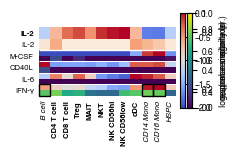

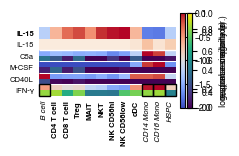

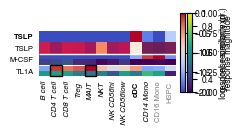

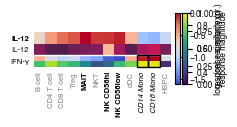

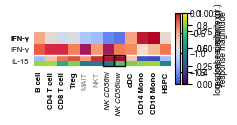

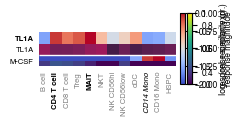

In [236]:
if 'cytokine_response_df_all' in locals():
    expressed_receptors = max_receptor_expression[max_receptor_expression > 2**4].index
    test_cytokines = CYTOKINE_ORDER
    #test_cytokines = ["IL-12"]
    for test_cytokine in test_cytokines:
        base_cell_types = list(outliers_rec_by_cell_type_high_high[outliers_rec_by_cell_type_high_high["index"] == test_cytokine]["cell_type"])
        additional_cell_types = list(outliers_rec_by_cell_type_low_high[outliers_rec_by_cell_type_low_high["index"] == test_cytokine]["cell_type"])
        
        if len(additional_cell_types) == 0:
            continue
        
        if len(all_secondary_responses_pre_filter[test_cytokine]) == 0:
            continue
        
        # receptor expression
        receptor_cytokines = [test_cytokine] + list(all_secondary_responses_pre_filter[test_cytokine])
        receptor_subset = receptor_expression_by_cytokine_relative.loc[receptor_cytokines, ALL_CELL_TYPES_EXCLUDE]
                
        # similarities
        r_val_df_subset = r_vals_by_cell_type_df.loc[test_cytokine]
        if len(receptor_cytokines) > 1:
            r_val_df_subset = r_val_df_subset.loc[receptor_cytokines[1:], ALL_CELL_TYPES_EXCLUDE]
    
        # plotting
        expr = np.log10(receptor_subset.clip(0.01,1)).values
        rv   = r_val_df_subset.values        # shape (expr.shape[0]-1, expr.shape[1])
        response_magnitude_cytokine = all_normalized_distances_mean.loc[test_cytokine, ALL_CELL_TYPES_EXCLUDE].values

        M, N = expr.shape
        M += 1
        
        # choose your colormaps & normalization
        cmap_expr = matplotlib.colormaps.get_cmap("coolwarm")
        norm_expr = matplotlib.colors.Normalize(vmin=np.nanmin(expr), vmax=np.nanmax(expr))

        cmap_r    = matplotlib.colormaps.get_cmap("viridis")
        r_min = 0.3
        r_max = 0.9
        norm_r    = matplotlib.colors.Normalize(vmin=r_min, vmax=r_max)

        cmap_response_magnitude = matplotlib.colormaps.get_cmap("rocket")
        response_magnitude_min = 0
        response_magnitude_max = 1
        norm_response_magnitude = matplotlib.colors.Normalize(vmin=response_magnitude_min, vmax=response_magnitude_max)

        fig, ax = plt.subplots(figsize=(cm_to_inches((4.5, 3+0.5*M))))
        ax.set_xlim(0, N)
        ax.set_ylim(0, M)
        ax.invert_yaxis()
        ax.set_aspect("equal")

        for i in range(M):
            for j in range(N):
                x0, y0 = j, i

                if i == 0:
                    # full square for row 0
                    color = cmap_expr(norm_expr(expr[i, j]))
                    rect = plt.Rectangle(
                        (x0, y0), 1, 1,
                        facecolor=color,
                        edgecolor=None,      # no border
                        linewidth=0,
                        antialiased=False
                    )
                    ax.add_patch(rect)
                elif i == 1:
                    # full square for row 1
                    color = cmap_response_magnitude(norm_response_magnitude(response_magnitude_cytokine[j]))
                    rect = plt.Rectangle(
                        (x0, y0), 1, 1,
                        facecolor=color,
                        edgecolor=None,
                        linewidth=0,
                        antialiased=False
                    )
                    ax.add_patch(rect)
                else:
                    # top half (expr)
                    c1 = cmap_expr(norm_expr(expr[i-1, j]))
                    top_rect = plt.Rectangle(
                        (x0, y0), 1, 0.5,
                        facecolor=c1,
                        edgecolor=None,
                        linewidth=0,
                        antialiased=False
                    )
                    ax.add_patch(top_rect)

                    # bottom half (r‐value)
                    c2 = cmap_r(norm_r(rv[i-2, j]))
                    bot_rect = plt.Rectangle(
                        (x0, y0+0.5), 1, 0.5,
                        facecolor=c2,
                        edgecolor=None,
                        linewidth=0,
                        antialiased=False
                    )
                    ax.add_patch(bot_rect)
    
        # ticks & labels
        ax.set_xticks(np.arange(N)+0.5)
        ax.set_xticklabels(receptor_subset.columns, rotation=90, fontsize=5.5)
        
        # Explicitly set all y-ticks and labels
        y_labels = list(receptor_subset.index)
        y_labels = [y_labels[0]] + y_labels 
        
        ax.set_yticks(np.arange(len(y_labels)) + 0.5)
        ax.set_yticklabels(y_labels, fontsize=5.5)
        
        # horizontal separators
        ax.axhline(2, color="white", linewidth=1, solid_capstyle="butt")
        for i in range(len(receptor_subset) - 2):
            ax.axhline(i+3, color="white", linewidth=0.75, solid_capstyle="butt")
            
        # colorbars
        sm1 = matplotlib.cm.ScalarMappable(norm=norm_expr, cmap=cmap_expr)
        sm1.set_array([])
        cax1 = fig.add_axes([0.92, 0.3, 0.03, 0.4])
        fig.colorbar(sm1, cax=cax1, label=r"$\log_{10}$(rel. receptor expr.)")

        sm2 = matplotlib.cm.ScalarMappable(norm=norm_response_magnitude, cmap=cmap_response_magnitude)
        sm2.set_array([])
        cax2 = fig.add_axes([0.96, 0.3, 0.03, 0.4])
        fig.colorbar(sm2, cax=cax2, label="response magnitude")

        sm3 = matplotlib.cm.ScalarMappable(norm=norm_r, cmap=cmap_r)
        sm3.set_array([])
        cax3 = fig.add_axes([0.96, 0.3, 0.03, 0.4])
        fig.colorbar(sm3, cax=cax3, label="response similarity (r)")
        
        # ----------------------------------------------------------------------------------------
        def style_heatmap_labels(ax, base_cell_types, additional_cell_types):
            """
            Style the heatmap labels with different formatting based on cell type categories.
            
            Parameters:
            -----------
            ax : matplotlib.axes.Axes
                The axes object containing the heatmap
            base_cell_types : list
                List of primary target cell types to be displayed in bold
            additional_cell_types : list
                List of secondary target cell types to be displayed in italic
                
            Returns:
            --------
            None
            """
            # Get the column indices for base_cell_types and additional_cell_types
            all_cell_types = ax.get_xticklabels()
            all_cell_type_texts = [label.get_text() for label in all_cell_types]
            
            # Create a list to store the font properties for each x-tick label
            fontprops = []
            for cell_type in all_cell_type_texts:
                if cell_type in base_cell_types:
                    # Bold font for base_cell_types
                    fontprops.append({'weight': 'heavy', 'color': 'black'})
                elif cell_type in additional_cell_types:
                    # Italic font for additional_cell_types
                    fontprops.append({'style': 'italic', 'color': 'black'})
                else:
                    # Grey color for other cell types
                    fontprops.append({'color': 'grey'})

            # Apply the font properties to x-tick labels
            plt.setp(ax.get_xticklabels(), **{'fontsize': 5.5, 'rotation': 90})
            for i, label in enumerate(ax.get_xticklabels()):
                if i < len(fontprops):
                    label.set_fontweight(fontprops[i].get('weight', 'normal'))
                    label.set_fontstyle(fontprops[i].get('style', 'normal'))
                    label.set_color(fontprops[i].get('color', 'black'))

            # Make the first y-tick label bold
            y_labels = ax.get_yticklabels()
            if len(y_labels) > 0:
                y_labels[0].set_fontweight('bold')
                
        # Call the function with current parameters
        style_heatmap_labels(ax, base_cell_types, additional_cell_types)
        
        # ----------------------------------------------------------------------------------------
        # Create a legend to explain the font styles
        # legend_elements = [
        #     matplotlib.lines.Line2D([0], [0], marker='o', color='w', markerfacecolor='black', markersize=0, 
        #         label='Primary targets', markeredgecolor='black'),
        #     matplotlib.lines.Line2D([0], [0], marker='o', color='w', markerfacecolor='black', markersize=0, 
        #         label='Secondary targets', markeredgecolor='black', linestyle='None'),
        #     matplotlib.lines.Line2D([0], [0], marker='o', color='w', markerfacecolor='grey', markersize=0, 
        #         label='Non-targeted', markeredgecolor='grey')
        # ]

        # Create a separate legend axis
        # legend_ax = fig.add_axes([0.2, 0.2, 0.0, 0.1])  # Moved up by increasing y position from 0.02 to 0.7
        # legend_ax.axis('off')

        # # Add the legend to this axis
        # legend = legend_ax.legend(handles=legend_elements, loc='center', 
        #                         fontsize=6, frameon=False)

        # # Style the legend text to match the actual formatting
        # legend_texts = legend.get_texts()
        # legend_texts[0].set_fontweight('heavy')
        # legend_texts[1].set_fontstyle('italic')
        # legend_texts[2].set_color('grey')
        
        # # Add a legend for the black rectangle (r > 0.5)
        # r_value_legend = [
        #     matplotlib.patches.Patch(
        #         edgecolor='black',
        #         facecolor='none',
        #         linewidth=1,
        #         label='(r > 0.5)&(strong impact)&(FC>2)\n&(receptor expressed)'
        #     )
        # ]
        
        # # Create a separate legend axis for r-value
        # r_value_legend_ax = fig.add_axes([0.2, 0.1, 0.0, 0.1])  # Position below the other legend
        # r_value_legend_ax.axis('off')
        
        # # Add the legend to this axis
        # r_value_legend = r_value_legend_ax.legend(
        #     handles=r_value_legend,
        #     loc='center',
        #     fontsize=6,
        #     frameon=False
        # )
        
        # ----------------------------------------------------------------------------------------
        for cell_idx, cell_type in enumerate(ALL_CELL_TYPES_EXCLUDE):
            r_vals = r_vals_by_cell_type[cell_type]
            for cytokine in receptor_cytokines[1:]:
                potential_cell_types = df_all_secondary_responses[df_all_secondary_responses["primary_cytokine"] == introduce_greek_letters(test_cytokine)]
                potential_cell_types = potential_cell_types[potential_cell_types["secondary_cytokine"] == introduce_greek_letters(cytokine)]['responding_cell_type'].unique()
                if cell_type in potential_cell_types:
                    # Get the exact position of the cell in the heatmap
                    cytokine_idx = receptor_cytokines.index(cytokine)
                        
                    # Create a rectangle patch properly centered on the cell
                    rect = plt.Rectangle(
                        (cell_idx, cytokine_idx+1),                # (x, y) - bottom left corner
                        1, 1,                                    # width, height
                        fill=False,                              # no fill, just outline
                        edgecolor='black',                       # black border
                        linewidth=1,                          # thin line
                        linestyle='-',                           # solid line
                        clip_on=False,                           # don't clip to axes boundary
                        zorder=100                               # much higher zorder to ensure it's drawn on top
                    )
                    # Add the patch to the axes and force a redraw to ensure it's at the front
                    ax.add_patch(rect)
                    rect.set_visible(True)  # Explicitly make visible
        
        # ----------------------------------------------------------------------------------------

        # Apply Greek letter substitutions
        apply_greek_labels_heatmap(ax)

        # Adjust other plot parameters
        ax.set_xlabel("")
        ax.set_ylabel("")
        ax.tick_params(axis='y', length=0)
        ax.tick_params(axis='x', rotation=90, labelsize=5.5, length=0)

        # Remove the border of the plot
        for spine in ax.spines.values():
            spine.set_visible(False)
        
        #plt.tight_layout()
        for format in ["png", "svg"]:
            plt.savefig(os.path.join(plot_folder, f"6.1.2_receptor_expression_{test_cytokine}.{format}"), 
                        bbox_inches="tight", 
                        dpi=300)

In [237]:
# if 'cytokine_response_df_all' in locals():
#     expressed_receptors = max_receptor_expression[max_receptor_expression > 2**4].index
#     test_cytokines = CYTOKINE_ORDER
#     #test_cytokines = ["IL-12"]
#     for test_cytokine in test_cytokines:
#         base_cell_types = list(outliers_rec_by_cell_type_high_high[outliers_rec_by_cell_type_high_high["index"] == test_cytokine]["cell_type"])
#         additional_cell_types = list(outliers_rec_by_cell_type_low_high[outliers_rec_by_cell_type_low_high["index"] == test_cytokine]["cell_type"])
        
#         if len(all_secondary_responses_pre_filter[test_cytokine]) == 0:
#             continue
        
#         # receptor expression
#         receptor_cytokines = [test_cytokine] + list(all_secondary_responses_pre_filter[test_cytokine])
#         receptor_subset = receptor_expression_by_cytokine_relative.loc[receptor_cytokines, ALL_CELL_TYPES_EXCLUDE]
                
#         # similarities
#         r_val_df_subset = r_vals_by_cell_type_df.loc[test_cytokine]
#         if len(receptor_cytokines) > 1:
#             r_val_df_subset = r_val_df_subset.loc[receptor_cytokines[1:], ALL_CELL_TYPES_EXCLUDE]
    
#         # plotting
#         expr = np.log10(receptor_subset.clip(0.01,1)).values
#         rv   = r_val_df_subset.values        # shape (expr.shape[0]-1, expr.shape[1])
#         response_magnitude_cytokine = all_normalized_distances_mean.loc[test_cytokine, ALL_CELL_TYPES_EXCLUDE].values

#         M, N = expr.shape

#         # choose your colormaps & normalization
#         cmap_expr = matplotlib.colormaps.get_cmap("coolwarm")
#         norm_expr = matplotlib.colors.Normalize(vmin=np.nanmin(expr), vmax=np.nanmax(expr))

#         cmap_r    = matplotlib.colormaps.get_cmap("viridis")
#         r_min = 0.3
#         r_max = 0.9
#         norm_r    = matplotlib.colors.Normalize(vmin=r_min, vmax=r_max)

#         cmap_response_magnitude = matplotlib.colormaps.get_cmap("rocket")
#         response_magnitude_min = 0
#         response_magnitude_max = 1
#         norm_response_magnitude = matplotlib.colors.Normalize(vmin=response_magnitude_min, vmax=response_magnitude_max)

#         fig, ax = plt.subplots(figsize=(cm_to_inches((4.5, 3+0.5*M))))
#         ax.set_xlim(0, N)
#         ax.set_ylim(0, M)
#         ax.invert_yaxis()
#         ax.set_aspect("equal")

#         for i in range(M):
#             for j in range(N):
#                 x0, y0 = j, i

#                 if i == 0:
#                     # full square for row 0
#                     color = cmap_expr(norm_expr(expr[i, j]))
#                     rect = plt.Rectangle(
#                         (x0, y0), 1, 1,
#                         facecolor=color,
#                         edgecolor=None,      # no border
#                         linewidth=0,
#                         antialiased=False
#                     )
#                     ax.add_patch(rect)
#                 else:
#                     # top half (expr)
#                     c1 = cmap_expr(norm_expr(expr[i, j]))
#                     top_rect = plt.Rectangle(
#                         (x0, y0), 1, 0.5,
#                         facecolor=c1,
#                         edgecolor=None,
#                         linewidth=0,
#                         antialiased=False
#                     )
#                     ax.add_patch(top_rect)

#                     # bottom half (r‐value)
#                     c2 = cmap_r(norm_r(rv[i-1, j]))
#                     bot_rect = plt.Rectangle(
#                         (x0, y0+0.5), 1, 0.5,
#                         facecolor=c2,
#                         edgecolor=None,
#                         linewidth=0,
#                         antialiased=False
#                     )
#                     ax.add_patch(bot_rect)

#         # now draw just the one horizontal separator
#         ax.axhline(1, color="white", linewidth=1, solid_capstyle="butt")
#         for i in range(len(receptor_subset) - 1):
#             ax.axhline(i+2, color="white", linewidth=0.75, solid_capstyle="butt")
        
        
#         # ticks & labels
#         ax.set_xticks(np.arange(N)+0.5)
#         ax.set_xticklabels(receptor_subset.columns, rotation=90, fontsize=5.5)
#         ax.set_yticks(np.arange(M)+0.5)
#         ax.set_yticklabels(receptor_subset.index, fontsize=5.5)
#         ax.axhline(1, color="white", linewidth=1)  # line under row 0

#         # colorbars
#         sm1 = matplotlib.cm.ScalarMappable(norm=norm_expr, cmap=cmap_expr)
#         sm1.set_array([])
#         cax1 = fig.add_axes([0.92, 0.3, 0.03, 0.4])
#         fig.colorbar(sm1, cax=cax1, label=r"$\log_{10}$(rel. receptor expr.)")

#         sm2 = matplotlib.cm.ScalarMappable(norm=norm_r, cmap=cmap_r)
#         sm2.set_array([])
#         cax2 = fig.add_axes([0.96, 0.3, 0.03, 0.4])
#         fig.colorbar(sm2, cax=cax2, label="response similarity (r)")
        
#         # ----------------------------------------------------------------------------------------
#         def style_heatmap_labels(ax, base_cell_types, additional_cell_types):
#             """
#             Style the heatmap labels with different formatting based on cell type categories.
            
#             Parameters:
#             -----------
#             ax : matplotlib.axes.Axes
#                 The axes object containing the heatmap
#             base_cell_types : list
#                 List of primary target cell types to be displayed in bold
#             additional_cell_types : list
#                 List of secondary target cell types to be displayed in italic
                
#             Returns:
#             --------
#             None
#             """
#             # Get the column indices for base_cell_types and additional_cell_types
#             all_cell_types = ax.get_xticklabels()
#             all_cell_type_texts = [label.get_text() for label in all_cell_types]
            
#             # Create a list to store the font properties for each x-tick label
#             fontprops = []
#             for cell_type in all_cell_type_texts:
#                 if cell_type in base_cell_types:
#                     # Bold font for base_cell_types
#                     fontprops.append({'weight': 'heavy', 'color': 'black'})
#                 elif cell_type in additional_cell_types:
#                     # Italic font for additional_cell_types
#                     fontprops.append({'style': 'italic', 'color': 'black'})
#                 else:
#                     # Grey color for other cell types
#                     fontprops.append({'color': 'grey'})

#             # Apply the font properties to x-tick labels
#             plt.setp(ax.get_xticklabels(), **{'fontsize': 5.5, 'rotation': 90})
#             for i, label in enumerate(ax.get_xticklabels()):
#                 if i < len(fontprops):
#                     label.set_fontweight(fontprops[i].get('weight', 'normal'))
#                     label.set_fontstyle(fontprops[i].get('style', 'normal'))
#                     label.set_color(fontprops[i].get('color', 'black'))

#             # Make the first y-tick label bold
#             y_labels = ax.get_yticklabels()
#             if len(y_labels) > 0:
#                 y_labels[0].set_fontweight('bold')
                
#         # Call the function with current parameters
#         style_heatmap_labels(ax, base_cell_types, additional_cell_types)
        
#         # ----------------------------------------------------------------------------------------
#         # Create a legend to explain the font styles
#         legend_elements = [
#             matplotlib.lines.Line2D([0], [0], marker='o', color='w', markerfacecolor='black', markersize=0, 
#                 label='Primary targets', markeredgecolor='black'),
#             matplotlib.lines.Line2D([0], [0], marker='o', color='w', markerfacecolor='black', markersize=0, 
#                 label='Secondary targets', markeredgecolor='black', linestyle='None'),
#             matplotlib.lines.Line2D([0], [0], marker='o', color='w', markerfacecolor='grey', markersize=0, 
#                 label='Non-targeted', markeredgecolor='grey')
#         ]

#         # Create a separate legend axis
#         # legend_ax = fig.add_axes([0.2, 0.2, 0.0, 0.1])  # Moved up by increasing y position from 0.02 to 0.7
#         # legend_ax.axis('off')

#         # # Add the legend to this axis
#         # legend = legend_ax.legend(handles=legend_elements, loc='center', 
#         #                         fontsize=6, frameon=False)

#         # # Style the legend text to match the actual formatting
#         # legend_texts = legend.get_texts()
#         # legend_texts[0].set_fontweight('heavy')
#         # legend_texts[1].set_fontstyle('italic')
#         # legend_texts[2].set_color('grey')
        
#         # # Add a legend for the black rectangle (r > 0.5)
#         # r_value_legend = [
#         #     matplotlib.patches.Patch(
#         #         edgecolor='black',
#         #         facecolor='none',
#         #         linewidth=1,
#         #         label='(r > 0.5)&(strong impact)&(FC>2)\n&(receptor expressed)'
#         #     )
#         # ]
        
#         # # Create a separate legend axis for r-value
#         # r_value_legend_ax = fig.add_axes([0.2, 0.1, 0.0, 0.1])  # Position below the other legend
#         # r_value_legend_ax.axis('off')
        
#         # # Add the legend to this axis
#         # r_value_legend = r_value_legend_ax.legend(
#         #     handles=r_value_legend,
#         #     loc='center',
#         #     fontsize=6,
#         #     frameon=False
#         # )
        
#         # ----------------------------------------------------------------------------------------
#         for cell_idx, cell_type in enumerate(ALL_CELL_TYPES_EXCLUDE):
#             r_vals = r_vals_by_cell_type[cell_type]
#             for cytokine in receptor_cytokines[1:]:
#                 potential_cell_types = df_all_secondary_responses[df_all_secondary_responses["primary_cytokine"] == introduce_greek_letters(test_cytokine)]
#                 potential_cell_types = potential_cell_types[potential_cell_types["secondary_cytokine"] == introduce_greek_letters(cytokine)]['responding_cell_type'].unique()
#                 if cell_type in potential_cell_types:
#                     # Get the exact position of the cell in the heatmap
#                     cytokine_idx = receptor_cytokines.index(cytokine)
                        
#                     # Create a rectangle patch properly centered on the cell
#                     rect = plt.Rectangle(
#                         (cell_idx, cytokine_idx),                # (x, y) - bottom left corner
#                         1, 1,                                    # width, height
#                         fill=False,                              # no fill, just outline
#                         edgecolor='black',                       # black border
#                         linewidth=1,                          # thin line
#                         linestyle='-',                           # solid line
#                         clip_on=False,                           # don't clip to axes boundary
#                         zorder=100                               # much higher zorder to ensure it's drawn on top
#                     )
#                     # Add the patch to the axes and force a redraw to ensure it's at the front
#                     ax.add_patch(rect)
#                     rect.set_visible(True)  # Explicitly make visible
        
#         # ----------------------------------------------------------------------------------------
#         # Explicitly set all y-ticks and labels
#         ax.set_yticks(np.arange(len(receptor_subset.index)) + 0.5)
#         ax.set_yticklabels([cytokine for cytokine in receptor_subset.index], fontsize=5.5)

#         # Apply Greek letter substitutions
#         apply_greek_labels_heatmap(ax)

#         # Adjust other plot parameters
#         ax.set_xlabel("")
#         ax.set_ylabel("")
#         ax.tick_params(axis='y', length=0)
#         ax.tick_params(axis='x', rotation=90, labelsize=5.5, length=0)

#         # Remove the border of the plot
#         for spine in ax.spines.values():
#             spine.set_visible(False)
        
#         #plt.tight_layout()
#         for format in ["png", "svg"]:
#             plt.savefig(os.path.join(plot_folder, f"6.1.2_receptor_expression_{test_cytokine}.{format}"), 
#                         bbox_inches="tight", 
#                         dpi=300)

In [238]:
outliers_rec_by_cell_type_high_low_filter = outliers_rec_by_cell_type_high_low[~outliers_rec_by_cell_type_high_low["cell_type"].isin(["ILC", "pDC", "HSPC"])]
outliers_rec_by_cell_type_high_low_filter = outliers_rec_by_cell_type_high_low_filter.sort_values(by="raw_expression", ascending=False)

outliers_rec_by_cell_type_high_high_filter = outliers_rec_by_cell_type_high_high[~outliers_rec_by_cell_type_high_high["cell_type"].isin(["ILC", "pDC", "HSPC"])]
outliers_rec_by_cell_type_high_high_filter = outliers_rec_by_cell_type_high_high_filter.sort_values(by="raw_expression", ascending=False)

outliers_rec_by_cell_type_low_high_filter = outliers_rec_by_cell_type_low_high[~outliers_rec_by_cell_type_low_high["cell_type"].isin(["ILC", "pDC", "HSPC"])]
outliers_rec_by_cell_type_low_high_filter = outliers_rec_by_cell_type_low_high_filter.sort_values(by="raw_expression", ascending=False)

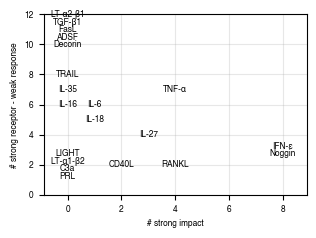

In [239]:
strong_sum = strong_impact_by_cell_type.loc[:, ~strong_impact_by_cell_type.columns.isin(["ILC", "pDC", "HSPC"])].sum(axis=1)
potential_failures = outliers_rec_by_cell_type_high_low_filter["index"].value_counts().to_frame()
potential_failures["strong_impact"] = strong_sum.loc[potential_failures.index]

potential_failures = potential_failures[potential_failures['count'] > 1]

plt.figure(figsize=cm_to_inches((8, 6)))
plt.scatter(potential_failures['strong_impact'], potential_failures['count'], alpha=0)  # invisible points as placeholders

# Create a dictionary to track points at the same coordinates
point_dict = {}
for idx, row in potential_failures.iterrows():
    key = (row['strong_impact'], row['count'])
    if key not in point_dict:
        point_dict[key] = []
    point_dict[key].append(idx)

# Add text labels at each point with vertical spacing for duplicates
for coords, labels in point_dict.items():
    x, y = coords
    if len(labels) == 1:
        # Single label - center it
        plt.text(x, y, introduce_greek_letters(labels[0]), fontsize=6, 
                 ha='center', va='center')
    else:
        # Multiple labels at same point - space them vertically
        offset = 0.5  # Vertical spacing between labels
        total_height = offset * (len(labels) - 1)
        start_y = y - total_height/2
        
        for i, label in enumerate(labels):
            plt.text(x, start_y + i*offset, introduce_greek_letters(label), 
                     fontsize=6, ha='center', va='center')

plt.xlim(-0.9, 8.9)
plt.ylim(0, 12)
plt.xlabel('# strong impact')
plt.ylabel('# strong receptor - weak response')
plt.grid(True, alpha=0.3)
plt.tight_layout()
for format in ["png", "svg"]:
    plt.savefig(os.path.join(plot_folder, f"6.1.2-failed-responses.{format}"), dpi=300)

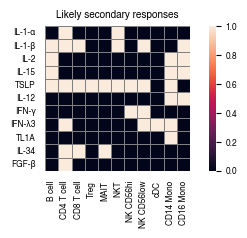

In [240]:
# Reformat as index x cell_type with 0/1
outlier_matrix = pd.crosstab(
    outliers_rec_by_cell_type_low_high_filter["index"],
    outliers_rec_by_cell_type_low_high_filter["cell_type"]
)
outlier_matrix = (outlier_matrix > 0).astype(int)
# Reorder the outlier_matrix according to CYTOKINE_ORDER (rows) and CELL_TYPE_ORDER (columns)
# Only keep those in the intersection of outlier_matrix and the order lists

# Get intersection for rows and columns
row_order = [cyt for cyt in CYTOKINE_ORDER if cyt in outlier_matrix.index]
col_order = [ct for ct in ALL_CELL_TYPES if ct in outlier_matrix.columns]

outlier_matrix = outlier_matrix.loc[row_order, col_order]


plt.figure(figsize=cm_to_inches((10, 6)))
ax = sns.heatmap(outlier_matrix, cmap="rocket", cbar=True, linewidths=0.5, linecolor='gray', square=True)
plt.xlabel("")
plt.ylabel("")
plt.title("Likely secondary responses")
# Remove the ticks but keep the labels
ax.tick_params(axis='x', which='both', bottom=False, top=False)
ax.tick_params(axis='y', which='both', left=False, right=False)
ax = apply_greek_labels_heatmap(ax)
plt.tight_layout()
for format in ["png", "svg"]:
    plt.savefig(os.path.join(plot_folder, f"6.1.2_likely_secondary_responses.{format}"), dpi=300)

## 6.2 - Correlations between responses in different cell types

In [241]:
# # raise Exception("Stop!")
# plot_folder = os.path.join(base_plot_folder, "6.2_between_cell_similarity")
# os.makedirs(plot_folder, exist_ok=True)
# cell_type_combs = list(combinations_with_replacement(ALL_CELL_TYPES, 2))

In [242]:
# # calculate novel filters that define genes present in both cell types (takes ~45s)


# common_filter_by_cell_type_comb = {}
# for cell_type_1, cell_type_2 in cell_type_combs:
#     # get first filter (as for within cell calculations)
#     all_inclusive_filter_1 = expressed_genes_by_cell_type_dict[cell_type_1]
#     existing_fold_change_vals_1 = edger_df_log2FoldChange[cell_type_1].dropna(how='all').index
#     all_inclusive_filter_1 = [gene for gene in all_inclusive_filter_1 if gene in existing_fold_change_vals_1]

#     # get second filter(as for within cell calculations)
#     all_inclusive_filter_2 = expressed_genes_by_cell_type_dict[cell_type_2]
#     existing_fold_change_vals_2 = edger_df_log2FoldChange[cell_type_2].dropna(how='all').index
#     all_inclusive_filter_2 = [gene for gene in all_inclusive_filter_2 if gene in existing_fold_change_vals_2]

#     # get the intersection of the two filters
#     all_inclusive_filter = [gene for gene in all_inclusive_filter_1 if gene in all_inclusive_filter_2]
#     common_filter_by_cell_type_comb[f"{cell_type_1}_{cell_type_2}"] = all_inclusive_filter
    
#     # print results
#     # print(f"Common filter for {cell_type_1} and {cell_type_2}: {len(all_inclusive_filter)} genes")

In [243]:
# %%capture output
# def scatter_plot(x, y, cytokine, cell1, cell2):
#     """Larger scatter plot for the SI."""
#     plt.figure(figsize=cm_to_inches((3.8, 3.5)))
    
#     # create a cross at the origin
#     plt.plot([-5, 5], [0, 0], color="black", linewidth=1, zorder=0, alpha=0.5)
#     plt.plot([0, 0], [-5, 5], color="black", linewidth=1, zorder=0, alpha=0.5)
#     plt.scatter(x, y, s=1, edgecolors="none", rasterized=True, zorder=1)
#     r = np.corrcoef(x, y)[0, 1]
#     plt.xlim(-4, 4)
#     plt.ylim(-4, 4)
#     plt.xticks([-4, -2, 0, 2, 4])
#     plt.yticks([-4, -2, 0, 2, 4]) 
#     plt.title(f"{cytokine}", fontsize=6.5)
#     # add r on the top left
#     plt.text(-3.5, 2.65, f"r = {r:.2f}", fontsize=6.5)
#     plt.xlabel(f"log$_{2}$FC({cell1})", fontsize=6.5)
#     plt.ylabel(f"log$_{2}$FC({cell2})", fontsize=6.5)
#     plt.tight_layout()
#     for format in ["png", "svg"]:
#         plt.savefig(os.path.join(plot_folder, f"6.2_scatter_{cell1}_{cell2}_{cytokine}.{format}"), dpi=400)
#     plt.close()

# def scatter_plot_small(x, y, cytokine, cell1, cell2):
#     """Smaller scatter plot for the Main Text."""
#     plt.figure(figsize=cm_to_inches((3.2, 3)))

#     plt.scatter(x, y, s=1, edgecolors="none", rasterized=True, zorder=1)
#     r = np.corrcoef(x, y)[0, 1]
#     plt.xlim(-4, 4)
#     plt.ylim(-4, 4)
#     plt.xticks([-4, 0, 4], fontsize=6)
#     plt.yticks([-4, 0, 4], fontsize=6) 

#     plt.xlabel(f"log$_{2}$FC", fontsize=6)
#     plt.ylabel(f"log$_{2}$FC", fontsize=6)
#     plt.title(f"{cell1} vs {cell2}", fontsize=6)
    
#     # add r on the top left
#     plt.text(-3.5, 2.5, f"r = {r:.2f}", fontsize=6)
    
#     plt.tight_layout()
#     for format in ["png", "svg"]:
#         plt.savefig(os.path.join(plot_folder, f"6.2_scatter_small_{cell1}_{cell2}_{cytokine}.{format}"), dpi=400)
#     plt.close()

# pairs_to_plot = [
#     # ("B cell", "CD4 T cell", "4-1BBL"),
#     # ("B cell", "CD4 T cell", "APRIL"),
#     # ("B cell", "CD4 T cell", "IL-4"),
#     # ("B cell", "CD4 T cell", "IL-13"),
#     # ("B cell", "CD4 T cell", "IL-15"),
#     # ("B cell", "CD4 T cell", "TSLP"),
#     # ("B cell", "CD4 T cell", "TPO"),
#     # ("B cell", "CD14 Mono", "4-1BBL"),
#     # ("B cell", "CD14 Mono", "APRIL"),
#     # ("B cell", "CD14 Mono", "IL-4"),
#     # ("B cell", "CD14 Mono", "IL-13"),
#     # ("B cell", "CD14 Mono", "IL-15"),
#     # ("B cell", "CD14 Mono", "TSLP"),
#     # ("B cell", "CD14 Mono", "TPO"),
#     ("CD14 Mono", "CD16 Mono", "GM-CSF"),
#     ("CD14 Mono", "cDC", "GM-CSF"),
#     ("CD14 Mono", "B cell", "GM-CSF"),
# ]

# for cell_type_1, cell_type_2, cytokine in pairs_to_plot:
#     try:
#         all_inclusive_filter = common_filter_by_cell_type_comb[f"{cell_type_1}_{cell_type_2}"]
#     except KeyError:
#         all_inclusive_filter = common_filter_by_cell_type_comb[f"{cell_type_2}_{cell_type_1}"]
#     cell_types_log2 = edger_df_log2FoldChange.loc[all_inclusive_filter, :]
    
#     # get the values
#     vals_1 = cell_types_log2[cell_type_1][cytokine].dropna()
#     vals_2 = cell_types_log2[cell_type_2][cytokine].dropna()
    
#     # use the intersection of common genes
#     common_index = vals_1.index.intersection(vals_2.index)
#     vals_1 = vals_1.loc[common_index]
#     vals_2 = vals_2.loc[common_index]
    
#     scatter_plot(vals_1, vals_2, cytokine, cell_type_1, cell_type_2)
#     scatter_plot_small(vals_1, vals_2, cytokine, cell_type_1, cell_type_2)

### calculate correlation vals

In [244]:
# if os.path.exists(os.path.join("output", f"6.2_r_vals_cell_cell_df.pkl")):
#     with open(os.path.join("output", f"6.2_r_vals_cell_cell_df.pkl"), "rb") as f:
#         r_vals_cell_cell_df = pickle.load(f)
# else:
#     r_vals_cell_cell = []
#     for cell_type_1, cell_type_2 in cell_type_combs:
#         # print(f"Calculating r_vals_cell_cell for {cell_type_1} and {cell_type_2}")
        
#         # get the filter
#         all_inclusive_filter = common_filter_by_cell_type_comb[f"{cell_type_1}_{cell_type_2}"]
#         cell_types_log2 = edger_df_log2FoldChange.loc[all_inclusive_filter, :]

#         for cytokine in CYTOKINE_ORDER:
#             if cell_type_1 == cell_type_2:
#                 r_vals_cell_cell.append({
#                     "cytokine": cytokine,
#                     "cell_type_1": cell_type_1,
#                     "cell_type_2": cell_type_2,
#                     "r": 1.0
#                 })
#                 continue
            
#             # get the values
#             vals_1 = cell_types_log2[cell_type_1][cytokine].dropna()
#             vals_2 = cell_types_log2[cell_type_2][cytokine].dropna()
            
#             # use the intersection of common genes
#             common_index = vals_1.index.intersection(vals_2.index)
#             vals_1 = vals_1.loc[common_index]
#             vals_2 = vals_2.loc[common_index]

#             if len(vals_1) == 0 or len(vals_2) == 0:
#                 r_vals_cell_cell.append({
#                     "cytokine": cytokine,
#                     "cell_type_1": cell_type_1,
#                     "cell_type_2": cell_type_2,
#                     "r": np.nan
#                 })
#                 continue

#             r_vals_cell_cell.append({
#                 "cytokine": cytokine,
#                 "cell_type_1": cell_type_1,
#                 "cell_type_2": cell_type_2,
#                 "r": np.corrcoef(vals_1, vals_2)[0, 1]
#                 })
            
#     r_vals_cell_cell_df = pd.DataFrame(r_vals_cell_cell)
#     r_vals_cell_cell_df = r_vals_cell_cell_df.pivot(index="cell_type_1", columns=["cytokine", "cell_type_2"], values="r")
    
#     # symmetrize values
#     filled_dfs = {}
#     for cytokine in r_vals_cell_cell_df.columns.levels[0]:
#         # Extract the matrix corresponding to the current cytokine.
#         matrix = r_vals_cell_cell_df.xs(cytokine, axis=1, level=0)
        
#         # Fill in the missing values using the symmetric (transposed) value.
#         matrix_filled = matrix.combine_first(matrix.T)
        
#         # Save the filled matrix to a dictionary
#         filled_dfs[cytokine] = matrix_filled

#     # Concatenate the filled matrices back into a single DataFrame
#     r_vals_cell_cell_df = pd.concat(filled_dfs, axis=1)

#     # rename columns and the index
#     r_vals_cell_cell_df.columns.names = ['cytokine', 'cell_type_2']
#     r_vals_cell_cell_df.index.name = "cell_type_1"
    
#     # order by ALL_CELL_TYPES
#     r_vals_cell_cell_df = r_vals_cell_cell_df.reindex(index=ALL_CELL_TYPES, columns=pd.MultiIndex.from_product([r_vals_cell_cell_df.columns.levels[0], ALL_CELL_TYPES]))
    
#     with open(os.path.join("output", f"6.2_r_vals_cell_cell_df.pkl"), "wb") as f:
#         pickle.dump(r_vals_cell_cell_df, f)

### make various scatter plots and heatmaps

In [245]:
# reference_cell_type = "CD14 Mono"
# other_cell_types_to_plot = ["B cell", "CD4 T cell", "NK CD56low", "cDC", "CD16 Mono", "HSPC"]
# cytokines = ["GM-CSF", "IL-3", "IL-4", "4-1BBL", "APRIL"]

# triplexes = [(reference_cell_type, other_cell_type, cytokine) 
#              for cytokine in cytokines
#              for other_cell_type in other_cell_types_to_plot
#              ]

# # ------------------------- Large plot -------------------------
# fig, axs = plt.subplots(nrows=5, ncols=6, figsize=cm_to_inches((16, 12)), sharex=True, sharey=True)
# axs = axs.flatten()
# counter = 0

# for cell_type_1, cell_type_2, cytokine in triplexes:
#     try:
#         all_inclusive_filter = common_filter_by_cell_type_comb[f"{cell_type_1}_{cell_type_2}"]
#     except KeyError:
#         all_inclusive_filter = common_filter_by_cell_type_comb[f"{cell_type_2}_{cell_type_1}"]
#     cell_types_log2 = edger_df_log2FoldChange.loc[all_inclusive_filter, :]
        
#     # get the values
#     vals_1 = cell_types_log2[cell_type_1][cytokine].dropna()
#     vals_2 = cell_types_log2[cell_type_2][cytokine].dropna()
    
#     # use the intersection
#     common_index = vals_1.index.intersection(vals_2.index)
#     vals_1 = vals_1.loc[common_index]
#     vals_2 = vals_2.loc[common_index]
    
#     r = np.corrcoef(vals_1, vals_2)[0, 1]
    
#     # ---- subplots ----
#     ax = axs[counter]
    
#     # create a cross at the origin
#     ax.plot([-5, 5], [0, 0], color="black", linewidth=1, zorder=0, alpha=0.5)
#     ax.plot([0, 0], [-5, 5], color="black", linewidth=1, zorder=0, alpha=0.5)
#     ax.scatter(vals_1, vals_2, s = 1, edgecolor="none", alpha=0.5, rasterized=True, zorder=1)
    
#     ax.set_xlim(-4, 4)
#     ax.set_ylim(-4, 4)
#     ax.set_xticks([-4, -2, 0, 2, 4])
#     ax.set_yticks([-4, -2, 0, 2, 4]) 

#     ax.set_xlabel(f"{cell_type_1}", fontsize=6)
#     ax.set_ylabel(f"{cell_type_2}", fontsize=6)
#     # ax.set_xlabel(f"{introduce_greek_letters(cytokine1)}", fontsize=6)
#     # ax.set_ylabel(f"{introduce_greek_letters(cytokine2)}", fontsize=6)
#     #ax.set_title(f'{cytokine}, r={r:.2f}', fontsize=6)
#     ax.text(0.05, 0.95, f"r={r:.2f}", transform=ax.transAxes, 
#             fontsize=6, verticalalignment='top',
#             bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.7, edgecolor='none'))
    
#     # Set tick length to 0
#     ax.tick_params(axis='both', which='both', length=0)
    
#     counter += 1
#     if not ax.get_subplotspec().is_first_col():
#         plt.setp(ax.get_yticklabels(), visible=False)
    
#     if not ax.get_subplotspec().is_last_row():
#         plt.setp(ax.get_xticklabels(), visible=False)

# plt.tight_layout(pad=0.5, h_pad=0.5, w_pad=1)
# for format in ["png", "svg"]:
#     plt.savefig(os.path.join(plot_folder, f"6.2_corr_panel.{format}"),
#                     bbox_inches="tight", dpi=400)

In [246]:
# # remove unwanted cell types
# cell_types_to_exclude = ["HSPC", "pDC", "ILC"]
# r_vals_cell_cell_df_filter = r_vals_cell_cell_df[~r_vals_cell_cell_df.index.isin(cell_types_to_exclude)]
# r_vals_cell_cell_df_filter = r_vals_cell_cell_df_filter.loc[:, (slice(None), ~r_vals_cell_cell_df_filter.columns.get_level_values(1).isin(cell_types_to_exclude))]

In [247]:
# %%capture output
# for cytokine in CYTOKINE_ORDER:
#     if cytokine not in ["GM-CSF", "IL-4", "TSLP"]:
#         continue
#     plt.figure(figsize=cm_to_inches((6, 5)))
#     sns.heatmap(r_vals_cell_cell_df_filter.xs(cytokine, axis=1, level=0), cmap="rocket", vmin=0, vmax=1,
#                 cbar_kws={"label": "Pearson r"})
#     plt.tick_params(length=0)
#     plt.title(f"{cytokine}", fontsize=7)
#     plt.tight_layout()
#     for format in ["png", "svg"]:
#         plt.savefig(os.path.join(plot_folder, f"6.2_cell_cell_similarity_{cytokine}.{format}"), dpi=300)
#     plt.close()

In [248]:
# cytokines_to_plot = [
#     "4-1BBL", "APRIL", "IL-2", "IL-15",
#     "IL-4", "IL-13", "IL-21", "CD40L",
#     "M-CSF", "GM-CSF", "IL-3", "C5a",
#     "TSLP", "IL-32-beta", "IFN-omega", "IFN-gamma",
# ]

# # Determine grid dimensions; here we force a 4×4 grid.
# n_plots = len(cytokines_to_plot)
# n_cols = 4
# n_rows = int(np.ceil(n_plots / n_cols))

# # Create a figure with subplots.
# fig, axes = plt.subplots(n_rows, n_cols,
#                          figsize=cm_to_inches((18, 16)))
# # Flatten the axes array for easy iteration.
# axes = axes.flatten()

# # Loop over each cytokine and plot its heatmap in the corresponding subplot.
# for i, cytokine in enumerate(cytokines_to_plot):
#     ax = axes[i]
    
#     # Extract the data for this cytokine.
#     data = r_vals_cell_cell_df_filter.xs(cytokine, axis=1, level=0)
    
#     # Plot the heatmap without its own colorbar.
#     sns.heatmap(data,
#                 cmap="rocket",
#                 vmin=0, vmax=1,
#                 cbar=False,
#                 ax=ax,
#                 square=True)
    
#     # Give each subplot its own title.
#     ax.set_title(f"{cytokine}", fontsize=7)
    
#     # Remove tick labels from interior subplots:
#     # - Only show x tick labels on the bottom row.
#     # - Only show y tick labels on the left column.
#     row = i // n_cols
#     col = i % n_cols
#     if row != n_rows - 1:  # not bottom row
#         ax.set_xticklabels([])
#     if col != 0:          # not left column
#         ax.set_yticklabels([])
    
#     ax.set_ylabel("")
#     # Optionally remove tick marks.
#     ax.tick_params(length=0)

# # Remove any unused (empty) subplots (if the total number of cytokines is less than n_rows*n_cols)
# for j in range(n_plots, len(axes)):
#     fig.delaxes(axes[j])

# # Add one shared colorbar on the right side.
# # First, create a ScalarMappable with the same normalization and colormap as used in the heatmaps.
# norm = plt.Normalize(vmin=0, vmax=1)
# sm = plt.cm.ScalarMappable(cmap="rocket", norm=norm)
# sm.set_array([])

# # Adjust the figure layout to make room for the colorbar.
# fig.subplots_adjust(right=0.85, wspace=0.3, hspace=0.3)
# cbar_ax = fig.add_axes([0.88, 0.15, 0.02, 0.35])
# cbar = fig.colorbar(sm, cax=cbar_ax)
# cbar.set_label("Pearson r")

# # apply tight_layout
# plt.tight_layout()

# # Save the complete grid as PNG and SVG.
# for fmt in ["png", "svg"]:
#     fig.savefig(os.path.join(plot_folder, f"6.2_cell_cell_similarity_grid.{fmt}"), dpi=300)

# plt.show()

In [249]:
# curr_df = r_vals_cell_cell_df_filter.T.groupby(level=1).mean()
# curr_df = curr_df[curr_df.index]
# plt.figure(figsize=cm_to_inches((6, 5)))
# sns.heatmap(curr_df, cmap="rocket", vmin=0, vmax=1,
#             cbar_kws={"label": "Pearson r"}, square=True)
# plt.tick_params(length=0)
# plt.xlabel("")
# plt.ylabel("")
# plt.title(f"mean response similarity", fontsize=7)
# plt.tight_layout()
# for format in ["png", "svg"]:
#     plt.savefig(os.path.join(plot_folder, f"6.2_mean_cell_cell_similarity.{format}"), dpi=300)

### calculate and plot mean cell-cell correlation values

In [250]:
# # set all diagonals to NaN
# for cell_type in r_vals_cell_cell_df_filter.index:
#     r_vals_cell_cell_df_filter.loc[cell_type, (slice(None), cell_type)] = np.nan

# def get_results_from_eval_subset(df, eval_subset):
#     df = df.loc[eval_subset, (slice(None), eval_subset)]
    
#     df.index.name = "cell_type_1"
#     df.columns.names = ["cytokine", "cell_type_2"]

#     # flatten mean_cell_cell_r_vals
#     df = df.melt(ignore_index=False).dropna()
#     mean_cell_cell_r_vals = df.groupby("cytokine")["value"].mean()
#     std_cell_cell_r_vals = df.groupby("cytokine")["value"].std()
    
#     return mean_cell_cell_r_vals, std_cell_cell_r_vals
    
# cell_eval_subset = ["B cell", "CD4 T cell", "NK CD56low", "cDC", "CD14 Mono"]
# mean_cell_cell_r_vals, std_cell_cell_r_vals =  get_results_from_eval_subset(r_vals_cell_cell_df_filter.copy(), cell_eval_subset)

# other_subsets = [
#     ["B cell", "CD4 T cell"],
#     ["B cell", "NK CD56low"],
#     ["B cell", "cDC"],
#     ["B cell", "CD14 Mono"],
# ]
# mean_by_subset = {}
# for subset in other_subsets:
#     mean_by_subset[f"{subset[0]}-{subset[1]}"], _ =  get_results_from_eval_subset(r_vals_cell_cell_df_filter.copy(), subset)

In [251]:
# # histogram of the overall mean correlations
# plt.figure(figsize=cm_to_inches((4,3)))
# plt.hist(mean_cell_cell_r_vals, color="skyblue", edgecolor="black", bins=np.arange(0.3,1.05,0.025))
# plt.xlabel("mean Pearson r")
# plt.ylabel("count")
# plt.tight_layout()
# plt.savefig(os.path.join(plot_folder, "6.2_mean_correlation_vals.svg"))

In [252]:
# # create a line plot of mean_cell_cell_r_vals with the cytokine names as the x-axis, ordered from low to high mean pearson r
# # this serves as an overview figure of the distribution of mean correlation values

# plt.figure(figsize=cm_to_inches((18,2.7)))
# sorted_vals = mean_cell_cell_r_vals.sort_values()
# plt.plot(range(len(sorted_vals)), sorted_vals, '-', markersize=2, color="black", label="mean")

# # Plot standard deviation as shaded area
# plt.fill_between(range(len(sorted_vals)), 
#                  sorted_vals - std_cell_cell_r_vals[sorted_vals.index],
#                  sorted_vals + std_cell_cell_r_vals[sorted_vals.index],
#                  alpha=0.2, color='gray')

# # plot the various subset to show how it varies by cell similarity
# plt.plot(range(len(sorted_vals)), mean_by_subset["B cell-cDC"][sorted_vals.index], '-', markersize=2, color=CELL_TYPE_COLORS["cDC"], alpha=0.5, label="B cell-cDC")
# plt.plot(range(len(sorted_vals)), mean_by_subset["B cell-CD14 Mono"][sorted_vals.index], '-', markersize=2, color=CELL_TYPE_COLORS["CD14 Mono"], alpha=0.5, label="B cell-CD14 Mono")
# plt.plot(range(len(sorted_vals)), mean_by_subset["B cell-CD4 T cell"][sorted_vals.index], '-', markersize=2, color=CELL_TYPE_COLORS["CD4 T cell"], alpha=0.5, label="B cell-CD4 T cell")
# plt.plot(range(len(sorted_vals)), mean_by_subset["B cell-NK CD56low"][sorted_vals.index], '-', markersize=2, color=CELL_TYPE_COLORS["NK CD56low"], alpha=0.5, label="B cell-NK CD56low")

# # Find the index where mean goes above 0.6 and draw a vertical line there
# threshold = 0.6
# above_threshold_indices = np.where(sorted_vals.values > threshold)[0]
# if len(above_threshold_indices) > 0:
#     first_above_threshold_idx = above_threshold_indices[0]
#     # Add a vertical dashed line at the threshold point
#     plt.axvline(x=first_above_threshold_idx+0.5, color='red', linestyle='--', linewidth=1)
#     # Add text annotation
#     plt.text(first_above_threshold_idx + 1, 0.25, f'r < {threshold}', 
#              color='red', fontsize=7, verticalalignment='bottom')

# plt.legend(ncol=5)
# plt.xticks(range(len(sorted_vals)), sorted_vals.index, rotation=90, ha='center', fontsize=5.5)
# plt.ylabel('mean cell-cell\nPearson r')
# plt.ylim(0.25, 0.9)
# apply_greek_labels_heatmap(plt.gca())
# plt.margins(x=0.01) # Remove whitespace on left and right
# plt.tight_layout()
# plt.savefig(os.path.join(plot_folder, "6.2_mean_correlation_vals_ordered.svg"))

In [253]:
# top10_least_similar_pearson_corr = sorted_vals.head(10).index
# top10_least_similar_pearson_corr

### how do the mean correlation values depend on the distributon of response magnitudes?

In [254]:
# # get the mean and std of magnitudes (for the eval subset)
# normalized_distances_6_2_mean = all_normalized_distances_mean[cell_eval_subset].mean(axis=1)
# normalized_distances_6_2_std = all_normalized_distances_mean[cell_eval_subset].std(axis=1)

# # get the mean and std of the relative number of DEGs (for the eval subset)
# # I don't think I actually use this for anything here (?)
# significant_results_rel = significant_results.loc[cell_eval_subset]
# significant_results_rel = significant_results_rel.div(significant_results_rel.max(axis=1), axis=0)
# significant_results_rel_6_2_mean = significant_results_rel.mean(axis=0)
# significant_results_rel_6_2_std = significant_results_rel.std(axis=0)

In [255]:
# comparison_df_6_2 = pd.DataFrame({
#     'mean_cell_cell_r': mean_cell_cell_r_vals,
#     'normalized_distance_std': normalized_distances_6_2_std
# })

# plt.figure(figsize=cm_to_inches((3.6,3.6)))
# r = np.corrcoef(comparison_df_6_2['normalized_distance_std'], comparison_df_6_2['mean_cell_cell_r'])[0,1]
# plt.scatter(comparison_df_6_2['normalized_distance_std'], comparison_df_6_2['mean_cell_cell_r'], s=2)
# plt.xlabel(r"$\sigma$(response magnitude)")
# plt.ylabel("mean cell-cell\nPearson r")
# plt.title(f"r = {r:.2f}", fontsize=7)
# plt.tight_layout()
# plt.savefig(os.path.join(plot_folder, "6.2_mean_correlation_vals_std_distance.svg"))

# Look at individual top genes

In [256]:
plot_folder = os.path.join(base_plot_folder, "6.2_between_cell_similarity")
os.makedirs(plot_folder, exist_ok=True)
cell_type_combs = list(combinations_with_replacement(ALL_CELL_TYPES, 2))
cell_types_to_exclude = ["HSPC", "pDC", "ILC"]

In [257]:
def get_top_n_genes_for_single_cytokine(cell_type, cytokine, n, by="fold_change", direction="from_top", filter_protein_coding=False):
    # get significant genes
    p_vals = edger_df_padj[(cell_type, cytokine)]
    significance = (p_vals < 0.05)
    if filter_protein_coding:
        significance = significance[significance.index.isin(protein_coding_genes)]
    significance = significance[significance]
    
    fold_changes = edger_df_log2FoldChange.loc[significance.index, (cell_type, cytokine)]
    fold_changes = fold_changes.sort_values(ascending=False)
    p_vals = p_vals.sort_values(ascending=True)
    
    if by=="fold_change":
        if direction=="from_top":
            fold_changes = fold_changes.iloc[:n]
        elif direction=="from_bottom":
            fold_changes = fold_changes.iloc[-n:]
        else:
            raise Exception("direction must be from_top or from_bottom")
        p_vals = p_vals[fold_changes.index]
    elif by=="pval":
        p_vals = p_vals[:n]
        fold_changes = fold_changes[significance.index]
    
    return_df = pd.DataFrame({
        "pval": p_vals,
        "FC": fold_changes
    })
    
    return return_df

def get_top_values_both_directions(cell_type, cytokine, n, filter_protein_coding=True):
    # get dfs from top and bottom
    df_top = get_top_n_genes_for_single_cytokine(cell_type, cytokine, n=n, direction="from_top", filter_protein_coding=filter_protein_coding)
    df_bottom = get_top_n_genes_for_single_cytokine(cell_type, cytokine, n=n, direction="from_bottom", filter_protein_coding=filter_protein_coding)

    # merge them
    df = pd.concat([df_top, df_bottom])
    df = df[~df.index.duplicated(keep='first')]

    # generate a unique identifier
    df["direction"] = df["FC"].apply(lambda x: "upregulation" if x > 0 else "downregulation")
    df = df.reset_index().rename(columns={'index': 'gene'})
    df["identifier"] =  df["gene"] + "," + df["direction"]

    # get the top n entries
    df["abs_FC"] = abs(df["FC"])
    df = df.sort_values(by="abs_FC", ascending=False)
    df = df[:n]
    
    return df

def jaccard_index(set1, set2):
    intersection = set1.intersection(set2)
    union = set1.union(set2)
    
    return len(intersection)/len(union)

In [258]:
cytokines_to_plot = [
    "4-1BBL", "APRIL", "IL-2", "IL-15",
    "IL-4", "IL-13", "IL-21", "CD40L",
    "M-CSF", "GM-CSF", "IL-3", "C5a",
    "TSLP", "IL-32-beta", "IFN-omega", "IFN-gamma",
]

In [259]:
if os.path.exists("output/6.2_top_genes_by_cytokine.pkl"):
    with open("output/6.2_top_genes_by_cytokine.pkl", "rb") as f:
        top_genes_by_cytokine = pickle.load(f)
    intersection_vals_cell_cell_df = pd.read_csv("output_tables/6.2_intersection_vals_cell_cell_df.csv", index_col=0, header=[0,1])
else:
    # this runs for 5 min
    top_genes_by_cytokine = {}
    n = 100
    threshold_value_fc = 0.5
    intersection_vals_cell_cell = []
    for cytokine in CYTOKINE_ORDER:
        top_genes_by_cell_type_combo = {}
        for cell_type_1, cell_type_2 in cell_type_combs:
            df_cell_1 = get_top_values_both_directions(cell_type_1, cytokine, n=n, filter_protein_coding=True)
            df_cell_2 = get_top_values_both_directions(cell_type_2, cytokine, n=n, filter_protein_coding=True)

            # threshold on fc
            df_cell_1 = df_cell_1[df_cell_1["abs_FC"] > threshold_value_fc]
            df_cell_2 = df_cell_2[df_cell_2["abs_FC"] > threshold_value_fc]
            
            intersection = set(df_cell_1["identifier"].to_list()).intersection(set(df_cell_2["identifier"].to_list()))
            row_1 = {
                "cell_type_1": cell_type_1,
                "cell_type_2": cell_type_2,
                "cytokine": cytokine,
                "frac_intersection": len(intersection)/n
            }
            
            row_2 = {
                "cell_type_1": cell_type_2,
                "cell_type_2": cell_type_1,
                "cytokine": cytokine,
                "frac_intersection": len(intersection)/n
            }
            
            intersection_vals_cell_cell.append(row_1)
            if cell_type_1 != cell_type_2:
                intersection_vals_cell_cell.append(row_2)

            if strong_impact_by_cell_type.loc[cytokine, cell_type_1] and strong_impact_by_cell_type.loc[cytokine, cell_type_2] and cell_type_1 != cell_type_2:
                # merge the two dfs
                df_cell_cell = pd.merge(df_cell_1, df_cell_2, on="identifier", how="inner")
                top_genes_by_cell_type_combo[f"{cell_type_1}_{cell_type_2}"] = df_cell_cell['identifier'].to_list()
        top_genes_by_cytokine[cytokine] = top_genes_by_cell_type_combo

    intersection_vals_cell_cell_df = pd.DataFrame(intersection_vals_cell_cell)
    intersection_vals_cell_cell_df = intersection_vals_cell_cell_df.pivot(index = "cell_type_1", columns = ["cytokine", "cell_type_2"], values = "frac_intersection")
    intersection_vals_cell_cell_df = intersection_vals_cell_cell_df.loc[ALL_CELL_TYPES, (slice(None), ALL_CELL_TYPES)]

    with open("output/6.2_top_genes_by_cytokine.pkl", "wb") as f:
        pickle.dump(top_genes_by_cytokine, f)
    intersection_vals_cell_cell_df.to_csv("output_tables/6.2_intersection_vals_cell_cell_df.csv")

In [260]:
intersection_df_filter = intersection_vals_cell_cell_df[~intersection_vals_cell_cell_df.index.isin(cell_types_to_exclude)]
intersection_df_filter = intersection_df_filter.loc[:, (slice(None), ~intersection_df_filter.columns.get_level_values(1).isin(cell_types_to_exclude))]

C:\Users\loesi\AppData\Local\Temp\ipykernel_37688\1774484621.py:70: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



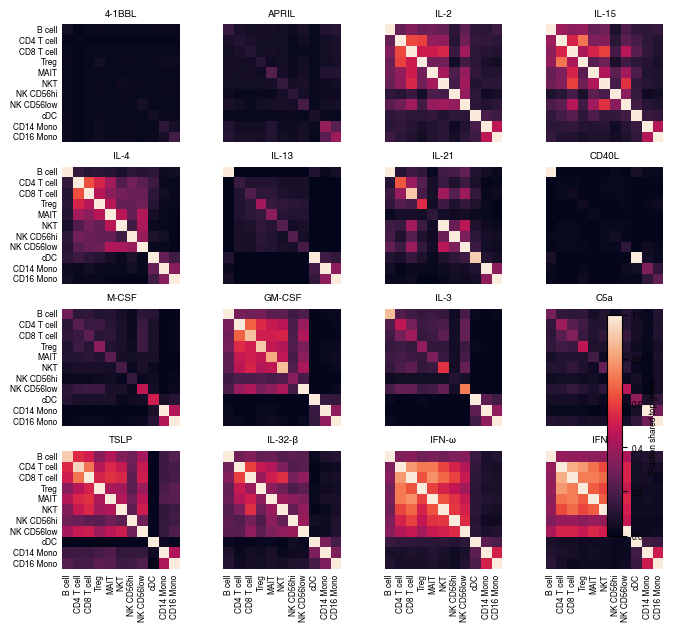

In [261]:
# generate a table here!
cytokines_to_plot = [
    "4-1BBL", "APRIL", "IL-2", "IL-15",
    "IL-4", "IL-13", "IL-21", "CD40L",
    "M-CSF", "GM-CSF", "IL-3", "C5a",
    "TSLP", "IL-32-beta", "IFN-omega", "IFN-gamma",
]

# Determine grid dimensions; here we force a 4×4 grid.
n_plots = len(cytokines_to_plot)
n_cols = 4
n_rows = int(np.ceil(n_plots / n_cols))

# Create a figure with subplots.
fig, axes = plt.subplots(n_rows, n_cols,
                         figsize=cm_to_inches((18, 16)))
# Flatten the axes array for easy iteration.
axes = axes.flatten()

# Loop over each cytokine and plot its heatmap in the corresponding subplot.
for i, cytokine in enumerate(cytokines_to_plot):
    ax = axes[i]
    
    # Extract the data for this cytokine.
    data = intersection_df_filter.xs(cytokine, axis=1, level=0)
    
    # Plot the heatmap without its own colorbar.
    sns.heatmap(data,
                cmap="rocket",
                vmin=0, vmax=1,
                cbar=False,
                ax=ax,
                square=True)
    
    # Give each subplot its own title.
    ax.set_title(f"{introduce_greek_letters(cytokine)}", fontsize=7)
    
    # Remove tick labels from interior subplots:
    # - Only show x tick labels on the bottom row.
    # - Only show y tick labels on the left column.
    row = i // n_cols
    col = i % n_cols
    if row != n_rows - 1:  # not bottom row
        ax.set_xticklabels([])
    if col != 0:          # not left column
        ax.set_yticklabels([])
    
    ax.set_xlabel("")
    ax.set_ylabel("")
    # Optionally remove tick marks.
    ax.tick_params(length=0)

# Remove any unused (empty) subplots (if the total number of cytokines is less than n_rows*n_cols)
for j in range(n_plots, len(axes)):
    fig.delaxes(axes[j])

# Add one shared colorbar on the right side.
# First, create a ScalarMappable with the same normalization and colormap as used in the heatmaps.
norm = plt.Normalize(vmin=0, vmax=1)
sm = plt.cm.ScalarMappable(cmap="rocket", norm=norm)
sm.set_array([])

# Adjust the figure layout to make room for the colorbar.
fig.subplots_adjust(right=0.85, wspace=0.3, hspace=0.3)
cbar_ax = fig.add_axes([0.88, 0.15, 0.02, 0.35])
cbar = fig.colorbar(sm, cax=cbar_ax)
cbar.set_label("Fraction shared top genes")

# apply tight_layout
plt.tight_layout()

# Save the complete grid as PNG and SVG.
for fmt in ["png", "svg"]:
    fig.savefig(os.path.join(plot_folder, f"6.3_ALT_cell_cell_similarity_grid.{fmt}"), dpi=300)

plt.show()

In [262]:
cell_types_by_cytokine = {}
for cytokine in CYTOKINE_ORDER:
    cell_type_list = []
    for cell_type in ALL_CELL_TYPES_EXCLUDE:
        if cell_type in cell_types_to_exclude:
            continue
        diagonal_val = intersection_df_filter.loc[cell_type, (cytokine, cell_type)]
        #if diagonal_val < 0.5:
        if not strong_impact_by_cell_type.loc[cytokine, cell_type]:
            intersection_df_filter.loc[:, (cytokine, cell_type)] = np.nan
            intersection_df_filter.loc[cell_type, (cytokine, slice(None))] = np.nan
        else:
            cell_type_list.append(cell_type)
        cell_types_by_cytokine[cytokine] = cell_type_list

In [263]:
# also create a dictionary with the lengths
cell_types_by_cytokine_len = {cytokine: len(cell_list) for cytokine, cell_list in cell_types_by_cytokine.items()}
removal_list = [cytokine for cytokine in cell_types_by_cytokine_len.keys() if cell_types_by_cytokine_len[cytokine] < 1]
print(cell_types_by_cytokine_len)

{'IL-1-alpha': 11, 'IL-1-beta': 11, 'IL-1Ra': 8, 'IL-18': 1, 'IL-33': 2, 'IL-36-alpha': 0, 'IL-36Ra': 0, 'IL-2': 11, 'IL-7': 11, 'IL-9': 0, 'IL-15': 11, 'IL-21': 9, 'TSLP': 11, 'IL-4': 11, 'IL-13': 4, 'IL-3': 5, 'IL-5': 0, 'GM-CSF': 10, 'IL-6': 1, 'IL-11': 0, 'IL-31': 0, 'LIF': 0, 'OSM': 6, 'CT-1': 0, 'IL-12': 9, 'IL-23': 0, 'IL-27': 3, 'IL-35': 0, 'IL-10': 10, 'IL-19': 0, 'IL-20': 0, 'IL-22': 0, 'IL-24': 0, 'IL-26': 1, 'IL-17A': 2, 'IL-17B': 0, 'IL-17C': 6, 'IL-17D': 7, 'IL-17E': 0, 'IL-17F': 0, 'IFN-alpha1': 10, 'IFN-beta': 11, 'IFN-epsilon': 8, 'IFN-omega': 11, 'IFN-gamma': 11, 'IFN-lambda1': 6, 'IFN-lambda2': 0, 'IFN-lambda3': 11, 'LT-alpha1-beta2': 0, 'LT-alpha2-beta1': 0, 'TNF-alpha': 4, 'OX40L': 0, 'CD27L': 2, 'FasL': 0, 'CD40L': 2, 'CD30L': 1, '4-1BBL': 0, 'TRAIL': 0, 'RANKL': 4, 'TWEAK': 0, 'APRIL': 0, 'BAFF': 5, 'LIGHT': 0, 'TL1A': 9, 'GITRL': 1, 'C3a': 0, 'C5a': 4, 'FLT3L': 0, 'IL-34': 10, 'M-CSF': 5, 'G-CSF': 4, 'SCF': 0, 'EGF': 3, 'VEGF': 0, 'FGF-beta': 6, 'HGF': 0, 'IGF-1

In [264]:
# remove anything with a length below 2 from the df
intersection_df_filter = intersection_df_filter.drop(labels=removal_list, axis=1)

C:\Users\loesi\AppData\Local\Temp\ipykernel_37688\2071377114.py:2: PerformanceWarning:

dropping on a non-lexsorted multi-index without a level parameter may impact performance.



In [265]:
# Set diagonal values to np.nan
for cytokine in intersection_df_filter.columns.get_level_values(0).unique():
    for cell_type in intersection_df_filter.index:
        if (cytokine, cell_type) in intersection_df_filter.columns and pd.notna(intersection_df_filter.loc[cell_type, (cytokine, cell_type)]):
            intersection_df_filter.loc[cell_type, (cytokine, cell_type)] = np.nan

In [266]:
def get_results_from_eval_subset(df, eval_subset):
    df = df.loc[eval_subset, (slice(None), eval_subset)]
    
    df.index.name = "cell_type_1"
    df.columns.names = ["cytokine", "cell_type_2"]

    df = df.melt(ignore_index=False).dropna()
    mean_cell_cell_vals = df.groupby("cytokine")["value"].mean()
    std_cell_cell_vals = df.groupby("cytokine")["value"].std()
    
    return mean_cell_cell_vals, std_cell_cell_vals
    
cell_eval_subset = ["B cell", "CD4 T cell", "NK CD56low", "cDC", "CD14 Mono"]
mean_cell_cell_inter, std_cell_cell_inter =  get_results_from_eval_subset(intersection_df_filter.copy(), [cell for cell in ALL_CELL_TYPES if not cell in cell_types_to_exclude])
std_cell_cell_inter = std_cell_cell_inter.dropna()
mean_cell_cell_inter = mean_cell_cell_inter.loc[std_cell_cell_inter.index]

other_subset = [
    ["B cell", "CD4 T cell"],
    ["B cell", "NK CD56low"],
    ["B cell", "cDC"],
    ["B cell", "CD14 Mono"],
]
mean_by_subset = {}
for subset in other_subset:
    mean_by_subset[f"{subset[0]}-{subset[1]}"], _ =  get_results_from_eval_subset(intersection_df_filter.copy(), subset)

Minimum value of mean (sorted_vals_data): 0.01
Maximum value of mean (sorted_vals_data): 0.6066666666666667
Minimum value of (mean - std) before clipping: -0.04472390211961218
Maximum value of (mean + std) before clipping: 0.7332631384447801


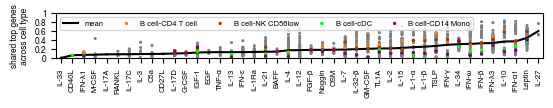

In [267]:
from matplotlib.ticker import FuncFormatter
def apply_greek_labels(ax):
    """
    Apply Greek letter formatting to axis tick labels.
    Numeric labels are preserved or formatted; text labels are processed.
    """
    original_x_formatter = ax.xaxis.get_major_formatter()
    original_y_formatter = ax.yaxis.get_major_formatter()

    def custom_tick_formatter(original_formatter, value, tick_position, is_numeric_axis=False):
        """
        Custom formatter that applies Greek letters to text and preserves/formats numbers.
        """
        label_string = ""
        # Ensure the original_formatter is callable before calling it
        if callable(original_formatter):
            label_string = original_formatter(value, tick_position)
        
        # If the original formatter gave a non-empty string...
        if label_string:
            try:
                # Test if it's a number. If so, return it directly.
                float(label_string.strip())
                return label_string
            except ValueError:
                # Not a number, apply Greek letter substitution.
                return introduce_greek_letters(label_string)
        # If original returned empty, AND it's a numeric axis AND value is a number...
        elif is_numeric_axis and isinstance(value, (int, float)):
            # Fallback: Format the number yourself.
            # Use 'g' for a general format or specify (e.g., '.1f').
            return f"{value:g}"
        # Otherwise (text axis with empty original, or non-number), return empty.
        else:
            return ""

    # Apply the custom formatter, telling the Y-axis it's likely numeric.
    # Note: We assume Y is numeric and X might be text/category.
    # If X can also be purely numeric and disappear, set is_numeric_axis=True for it too.
    ax.xaxis.set_major_formatter(FuncFormatter(
        lambda val, pos: custom_tick_formatter(original_x_formatter, val, pos, is_numeric_axis=False)
    ))
    ax.yaxis.set_major_formatter(FuncFormatter(
        lambda val, pos: custom_tick_formatter(original_y_formatter, val, pos, is_numeric_axis=True)
    ))

    # Redraw the figure to apply formatter changes.
    if ax.figure and ax.figure.canvas:
        ax.figure.canvas.draw_idle()
    

plt.figure(figsize=cm_to_inches((14,2.7)))

# Prepare data for plotting
# Convert pandas Series to NumPy arrays for direct use with Matplotlib
sorted_vals_series = mean_cell_cell_inter.sort_values()
# Use .to_numpy() for explicit conversion to a NumPy array
sorted_vals_data = sorted_vals_series.to_numpy() 
# X-axis as a simple integer sequence (NumPy array)
x_plot_indices = np.arange(len(sorted_vals_data)) 

# Ensure std_cell_cell_inter is aligned with sorted_vals_series.index and convert to NumPy array
# This alignment was established when mean_cell_cell_inter and std_cell_cell_inter were created,
# ensuring that sorted_vals_series.index contains keys present in std_cell_cell_inter.
aligned_std_dev_series = std_cell_cell_inter[sorted_vals_series.index]
aligned_std_dev_data = aligned_std_dev_series.to_numpy()

# Calculate y1 and y2 for the shaded area using NumPy arrays
y1_data = sorted_vals_data - aligned_std_dev_data
y2_data = sorted_vals_data + aligned_std_dev_data

# Sanity check: print the minimums to understand the data ranges using the NumPy arrays
print(f"Minimum value of mean (sorted_vals_data): {sorted_vals_data.min()}")
print(f"Maximum value of mean (sorted_vals_data): {sorted_vals_data.max()}")
print(f"Minimum value of (mean - std) before clipping: {y1_data.min()}")
print(f"Maximum value of (mean + std) before clipping: {y2_data.max()}")

# Clip the lower bound of the shaded area at 0.0, as "fraction shared top genes" should not be negative.
# If these values can also not exceed 1.0, y2_data could also be clipped: np.minimum(y2_data, 1.0)
y1_data_clipped = np.maximum(y1_data, 0.0)

# Plot mean line using NumPy arrays
plt.plot(x_plot_indices, sorted_vals_data, '-', markersize=2, color="black", label="mean")

# Plot standard deviation as shaded area using NumPy arrays
# plt.fill_between(x_plot_indices, 
#                  y1_data_clipped,
#                  y2_data,
#                  alpha=0.2, color='gray', label='mean ± std')

for i, cytokine in enumerate(sorted_vals_series.index):
    sub_df_for_cytokine = intersection_df_filter[cytokine]
    y_values_np_flat = sub_df_for_cytokine.to_numpy().flatten()
    y_vals = y_values_np_flat[~np.isnan(y_values_np_flat)]
    
    if len(y_vals) > 0:
        x_scatter_positions = [i] * len(y_vals)
        plt.scatter(x_scatter_positions, y_vals, color='grey', s=4, alpha=1, zorder=1, edgecolor="none")

# plot the various subset to show how it varies by cell similarity
for subset_name, subset_data in mean_by_subset.items():
    # Get only the cytokines that exist in both sorted_vals_series and subset_data
    valid_indices = subset_data.index.intersection(sorted_vals_series.index)
    if len(valid_indices) > 0:
        # x_values_scatter are integer positions on the x-axis corresponding to sorted_vals_series
        # Use sorted_vals_series.index (Pandas Index object) for get_loc
        x_values_scatter = [sorted_vals_series.index.get_loc(idx) for idx in valid_indices]
        # y_values are from the specific subset_data for these cytokines, converted to NumPy array
        y_values_subset = subset_data.loc[valid_indices].to_numpy()
        plt.scatter(x_values_scatter, y_values_subset, s=6, 
                   color=CELL_TYPE_COLORS[subset_name.split('-')[1]], alpha=1, label=f"{subset_name}", zorder=2, edgecolor="none")

# --- Formatting ---
# Set x-ticks and labels using the original Series index for cytokine names
plt.xticks(x_plot_indices, sorted_vals_series.index, rotation=90, ha='center', fontsize=5.5)
plt.ylabel('shared top genes\nacross cell type')
plt.margins(x=0.01) # Remove whitespace on left and right

plt.ylim(0.0, 1)  # Set y-axis limits
plt.gca().set_yticks(np.arange(0.0, 1.2, 0.2))

# Apply custom greek label formatting. This function might alter axis properties.
apply_greek_labels(plt.gca())
plt.legend(loc="upper left", ncol=5, fontsize=5.5)
plt.tight_layout()
plt.savefig(os.path.join(plot_folder, "6.3_ALT_mean_similarity_vals_ordered.svg"))

## Top genes for cytokine groupings 

In [268]:
with open("output/6_all_communities_cyto_cyto.pkl", "rb") as f:
    all_communities = pickle.load(f)
    all_communities_flat = [item for sublist in all_communities for item in sublist]
all_communities = {f"community_{i}": l for i, l in enumerate(all_communities)}

In [269]:
curr_key, curr_community = "community_0", all_communities["community_0"]
top_upregulated_by_label = {}
top_downregulated_by_label = {}
for cell_type in ALL_CELL_TYPES_EXCLUDE:
    # filter to strong impact in current cell type
    strong_impact = strong_impact_by_cell_type[cell_type]
    strong_impact = strong_impact[strong_impact]
    curr_community_filter = [c for c in curr_community if c in strong_impact]
    for cytokine in curr_community_filter:
        top_regulated = get_top_values_both_directions(cell_type, cytokine, n=100, filter_protein_coding=True)
        top_regulated["rank"] = range(1, len(top_regulated) + 1)
        top_upregulated = top_regulated[top_regulated["direction"] == "upregulation"]
        top_downregulated = top_regulated[top_regulated["direction"] == "downregulation"]
        top_upregulated_by_label[(cell_type, cytokine)] = top_upregulated.reset_index()
        top_downregulated_by_label[(cell_type, cytokine)] = top_downregulated.reset_index()

In [270]:
def borda_consensus(ranked_dfs_dict, minimum_default_rank=None):
    # ---------- long → wide --------------------------------------------------
    long = pd.concat(
        [df[['gene', 'rank']]
        .assign(list_id='_'.join(map(str, k)))   # tuple → single string
        for k, df in ranked_dfs_dict.items()]
    )
    wide = long.pivot_table(index='gene',
                            columns='list_id',
                            values='rank',
                            aggfunc='first')          # NaN = gene absent
    # ---------- appearances BEFORE filling ----------------------------------
    n_lists = wide.notna().sum(axis=1)

    # ---------- fill gaps with a per-column penalty --------------------------
    if minimum_default_rank is None:
        # each column gets its own worst-case rank
        filled = wide.apply(lambda col: col.fillna(col.max() + 1), axis=0)
    else:
        filled = wide.apply(
            lambda col: col.fillna(max(col.max() + 1, minimum_default_rank)),
            axis=0
        )

    # ---------- aggregate ----------------------------------------------------
    filled['borda_score'] = filled.sum(axis=1)
    filled['mean_rank']   = filled['borda_score'] / len(ranked_dfs_dict)
    filled['median_rank'] = filled.median(axis=1)
    filled['n_lists']     = n_lists                   # true appearances

    return (filled
            .sort_values('borda_score')              # lower = stronger consensus
            .reset_index())

cons_up   = borda_consensus(top_upregulated_by_label, 51).head(50)
cons_down = borda_consensus(top_downregulated_by_label, 51).head(50)

# add some descriptive columns
for df, sign in [(cons_up,'up'), (cons_down,'down')]:
    df.insert(1, 'direction', sign)

# CODE DEVELOPMENT

In [271]:
raise Exception("In Development - Stopping auto execution")

Exception: In Development - Stopping auto execution

### Alternative similarity measures for cell-cell similarity

In [ ]:
cell_types_exclude_wo_HSPC = [cell_type for cell_type in ALL_CELL_TYPES_EXCLUDE if not cell_type=="HSPC"]
reference_cell_types = cell_types_exclude_wo_HSPC
other_cell_types_to_plot = cell_types_exclude_wo_HSPC
cytokines = CYTOKINE_ORDER

triplexes = [(reference_cell_type, other_cell_type, cytokine) 
             for cytokine in cytokines
             for reference_cell_type in reference_cell_types
             for other_cell_type in other_cell_types_to_plot
             ]

cell_types_log2_fill = edger_df_log2FoldChange.fillna(0)
all_similarities = []
total = 0
for cell_type_1, cell_type_2, cytokine in triplexes:
    if total % 100 == 0:
        print(f"Processed {total} of {len(triplexes)}")
    try:
        all_inclusive_filter = common_filter_by_cell_type_comb[f"{cell_type_1}_{cell_type_2}"]
    except KeyError:
        all_inclusive_filter = common_filter_by_cell_type_comb[f"{cell_type_2}_{cell_type_1}"]
    vals_1 = cell_types_log2[cell_type_1][cytokine].dropna()
    vals_2 = cell_types_log2[cell_type_2][cytokine].dropna()
    
    # vals_1 = cell_types_log2[cell_type_1][cytokine].dropna()
    # vals_2 = cell_types_log2[cell_type_2][cytokine].dropna()
    # common_index = vals_1.index.intersection(vals_2.index)
    # vals_1 = vals_1.loc[common_index]
    # vals_2 = vals_2.loc[common_index]
    vals_1 = cell_types_log2[cell_type_1][cytokine]
    vals_2 = cell_types_log2[cell_type_2][cytokine]
    
    similarity = (vals_1*vals_2).sum() / len(vals_1)
    
    similarity = {
        "cell_type_1": cell_type_1,
        "cell_type_2": cell_type_2,
        "cytokine": cytokine,
        "similarity": similarity,
    }
    
    all_similarities.append(similarity)
    total = total + 1
    # if cell_type_1 != cell_type_2:
    #     break
    
all_similarities = pd.DataFrame.from_dict(all_similarities)

In [ ]:
all_similarities_pivot = all_similarities.pivot(index="cell_type_1", columns=["cytokine", "cell_type_2"], values="similarity")

In [ ]:
all_similarities_pivot = np.log10(all_similarities_pivot)

In [ ]:
all_similarities_pivot = all_similarities_pivot.loc[cell_types_exclude_wo_HSPC, (slice(None), cell_types_exclude_wo_HSPC)]

In [ ]:
cytokines_to_plot = [
    "4-1BBL", "APRIL", "IL-2", "IL-15",
    "IL-4", "IL-13", "IL-21", "CD40L",
    "M-CSF", "GM-CSF", "IL-3", "C5a",
    "TSLP", "IL-32-beta", "IFN-omega", "IFN-gamma",
]

# Determine grid dimensions; here we force a 4×4 grid.
n_plots = len(cytokines_to_plot)
n_cols = 4
n_rows = int(np.ceil(n_plots / n_cols))

# Create a figure with subplots.
fig, axes = plt.subplots(n_rows, n_cols,
                         figsize=cm_to_inches((18, 16)))
# Flatten the axes array for easy iteration.
axes = axes.flatten()

# Loop over each cytokine and plot its heatmap in the corresponding subplot.
for i, cytokine in enumerate(cytokines_to_plot):
    ax = axes[i]
    
    # Extract the data for this cytokine.
    data = all_similarities_pivot.xs(cytokine, axis=1, level=0)
    
    # Plot the heatmap without its own colorbar.
    sns.heatmap(data,
                cmap="rocket",
                vmin=all_similarities_pivot.min().min(), vmax=all_similarities_pivot.max().max(),
                cbar=False,
                ax=ax,
                square=True)
    
    # Give each subplot its own title.
    ax.set_title(f"{cytokine}", fontsize=7)
    
    ax.set_xlabel("")
    ax.set_ylabel("")
    
    # Remove tick labels from interior subplots:
    # - Only show x tick labels on the bottom row.
    # - Only show y tick labels on the left column.
    row = i // n_cols
    col = i % n_cols
    if row != n_rows - 1:  # not bottom row
        ax.set_xticklabels([])
    if col != 0:          # not left column
        ax.set_yticklabels([])
    
    # Optionally remove tick marks.
    ax.tick_params(length=0)

# Remove any unused (empty) subplots (if the total number of cytokines is less than n_rows*n_cols)
for j in range(n_plots, len(axes)):
    fig.delaxes(axes[j])

# Add one shared colorbar on the right side.
# First, create a ScalarMappable with the same normalization and colormap as used in the heatmaps.
norm = plt.Normalize(vmin=all_similarities_pivot.min().min(), vmax=all_similarities_pivot.max().max())
sm = plt.cm.ScalarMappable(cmap="rocket", norm=norm)
sm.set_array([])

# Adjust the figure layout to make room for the colorbar.
fig.subplots_adjust(right=0.85, wspace=0.3, hspace=0.3)
cbar_ax = fig.add_axes([0.88, 0.15, 0.02, 0.35])
cbar = fig.colorbar(sm, cax=cbar_ax)
cbar.set_label("Similarity")

# apply tight_layout 
plt.tight_layout()

# Save the complete grid as PNG and SVG.
for fmt in ["png", "svg"]:
    fig.savefig(os.path.join(plot_folder, f"6.2_alternative_similarity_grid.{fmt}"), dpi=300)

plt.show()

In [ ]:
# set all diagonals to NaN
for cell_type in all_similarities_pivot.index:
    all_similarities_pivot.loc[cell_type, (slice(None), cell_type)] = np.nan

def get_results_from_eval_subset(df, eval_subset):
    df = df.loc[eval_subset, (slice(None), eval_subset)]
    # name the index cell_type_1 and the second column level cell_type_2
    # rename the index and column levels
    df.index.name = "cell_type_1"
    df.columns.names = ["cytokine", "cell_type_2"]

    # flatten mean_cell_cell_alt_sim
    df = df.melt(ignore_index=False).dropna()
    mean_cell_cell_alt_sim = df.groupby("cytokine")["value"].mean()
    std_cell_cell_alt_sim = df.groupby("cytokine")["value"].std()
    
    return mean_cell_cell_alt_sim, std_cell_cell_alt_sim
    
cell_eval_subset = ["B cell", "CD4 T cell", "NK CD56low", "cDC", "CD14 Mono"]
mean_cell_cell_alt_sim, std_cell_cell_alt_sim =  get_results_from_eval_subset(all_similarities_pivot.copy(), cell_eval_subset)

other_subset = [
    ["B cell", "CD4 T cell"],
    ["B cell", "NK CD56low"],
    ["B cell", "cDC"],
    ["B cell", "CD14 Mono"],
]
mean_by_subset = {}
for subset in other_subset:
    mean_by_subset[f"{subset[0]}-{subset[1]}"], _ =  get_results_from_eval_subset(all_similarities_pivot.copy(), subset)

In [ ]:
# create a line plot of mean_cell_cell_alt_sim with the cytokine names as the x-axis, ordered from low to high mean pearson r
plt.figure(figsize=cm_to_inches((18,2.7)))
sorted_vals = mean_cell_cell_alt_sim.sort_values()
plt.plot(range(len(sorted_vals)), sorted_vals, '-', markersize=2, color="black", label="mean")
plt.plot(range(len(sorted_vals)), mean_by_subset["B cell-cDC"][sorted_vals.index], '-', markersize=2, color=CELL_TYPE_COLORS["cDC"], alpha=0.5, label="B cell-cDC")
plt.plot(range(len(sorted_vals)), mean_by_subset["B cell-CD14 Mono"][sorted_vals.index], '-', markersize=2, color=CELL_TYPE_COLORS["CD14 Mono"], alpha=0.5, label="B cell-CD14 Mono")
plt.plot(range(len(sorted_vals)), mean_by_subset["B cell-CD4 T cell"][sorted_vals.index], '-', markersize=2, color=CELL_TYPE_COLORS["CD4 T cell"], alpha=0.5, label="B cell-CD4 T cell")
plt.plot(range(len(sorted_vals)), mean_by_subset["B cell-NK CD56low"][sorted_vals.index], '-', markersize=2, color=CELL_TYPE_COLORS["NK CD56low"], alpha=0.5, label="B cell-NK CD56low")
plt.legend(ncol=5)

# Find the index where mean goes above 0.6
threshold = 0.6
above_threshold_indices = np.where(sorted_vals.values > threshold)[0]
if len(above_threshold_indices) > 0:
    first_above_threshold_idx = above_threshold_indices[0]
    # Add a vertical dashed line at the threshold point
    plt.axvline(x=first_above_threshold_idx, color='red', linestyle='--', linewidth=1)
    # Add text annotation
    plt.text(first_above_threshold_idx + 1, 0.3, f'r < {threshold}', 
             color='red', fontsize=7, verticalalignment='bottom')

# Plot standard deviation as shaded area
plt.fill_between(range(len(sorted_vals)), 
                 sorted_vals - std_cell_cell_alt_sim[sorted_vals.index],
                 sorted_vals + std_cell_cell_alt_sim[sorted_vals.index],
                 alpha=0.2, color='gray')
plt.xticks(range(len(sorted_vals)), sorted_vals.index, rotation=90, ha='center', fontsize=5.5)
plt.ylabel('mean cell-cell\nsimilarity')
# plt.ylim(0.25, 0.9)
apply_greek_labels_heatmap(plt.gca())
#plt.grid(True, alpha=0.3)
plt.margins(x=0.01) # Remove whitespace on left and right
plt.tight_layout()
plt.savefig(os.path.join(plot_folder, "6.2_mean_alt_sim_vals_ordered.svg")) 